# Multi-Horizon Forecasting of Petroleum Market Dynamics Using Machine and Deep Learning

**Reproducible analysis notebook**

This notebook implements the empirical analysis for U.S. petroleum demand, domestic crude-oil supply, and WTI prices. It covers data preparation, exploratory analysis, correlation and lead–lag analysis, stationarity diagnostics, feature engineering, chronological train/validation/test splitting, persistence and regression benchmarks, nonlinear machine learning, MLP/LSTM/GRU models, multi-horizon forecasting, forecast diagnostics, Diebold–Mariano tests, feature importance, look-back sensitivity, chronological split sensitivity, and feature-set ablation.

**Important:** No Lotka–Volterra model is estimated or used in this notebook. The source workbook retains its original filename and worksheet label only so that the analysis can read the supplied dataset without modification.


In [1]:
# ============================================================
# OUTPUT DIRECTORIES
# ============================================================
from pathlib import Path

OUTPUT_DIR = Path("outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Figures will be saved to: {FIGURE_DIR.resolve()}")
print(f"Tables will be saved to:  {TABLE_DIR.resolve()}")


Figures will be saved to: C:\Users\SOBAdmin\Desktop\multi-horizon\outputs\figures
Tables will be saved to:  C:\Users\SOBAdmin\Desktop\multi-horizon\outputs\tables


In [2]:
# ============================================================
# CELL 1: LIBRARIES AND GLOBAL CONFIGURATION
# Petroleum Market Machine/Deep Learning Forecasting
# ============================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt

# Statistical analysis
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Machine learning
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor

# Reproducibility
SEED = 42
np.random.seed(SEED)

# Plot configuration
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 11

print("Environment initialized successfully.")
print(f"NumPy version : {np.__version__}")
print(f"Pandas version: {pd.__version__}")

Environment initialized successfully.
NumPy version : 2.4.6
Pandas version: 3.0.3


In [5]:
# ============================================================
# CELL 2: LOAD DATASET
# ============================================================

FILE_PATH = "EIA_LV_Demand_Supply_Harmonized (1)(2).xlsx"
SHEET_NAME = "LV Ready"

df = pd.read_excel(
    FILE_PATH,
    sheet_name=SHEET_NAME
)

print(f"Dataset shape: {df.shape}")
print(f"Number of observations: {len(df)}")

display(df.head())

Dataset shape: (485, 8)
Number of observations: 485


,t (month),Date,D(t) raw,S(t) raw,P(t) raw,d(t)=D/mean(D),s(t)=S/mean(S),p(t)=P/mean(P)
0,0,1986-01-01,498728,283248,22.925455,0.860666,1.179242,0.473092
1,1,1986-02-01,453209,256855,15.454737,0.782113,1.069361,0.318926
2,2,1986-03-01,504565,279413,12.612500,0.870739,1.163276,0.260273
3,3,1986-04-01,478339,265917,12.843636,0.825481,1.107088,0.265043
4,4,1986-05-01,495789,273964,15.377619,0.855594,1.140590,0.317334


In [6]:
print("\nColumn names:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i:2d}. {column}")

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))


Column names:
 1. t (month)
 2. Date
 3. D(t) raw
 4. S(t) raw
 5. P(t) raw
 6. d(t)=D/mean(D)
 7. s(t)=S/mean(S)
 8. p(t)=P/mean(P)

Data types:


,Data Type
t (month),int64
Date,datetime64[us]
D(t) raw,int64
S(t) raw,int64
P(t) raw,float64
d(t)=D/mean(D),float64
s(t)=S/mean(S),float64
p(t)=P/mean(P),float64



Missing values:


,Missing Values
t (month),0
Date,0
D(t) raw,0
S(t) raw,0
P(t) raw,0
d(t)=D/mean(D),0
s(t)=S/mean(S),0
p(t)=P/mean(P),0


In [7]:
df.shape
df.columns.tolist()
df.head()

,t (month),Date,D(t) raw,S(t) raw,P(t) raw,d(t)=D/mean(D),s(t)=S/mean(S),p(t)=P/mean(P)
0,0,1986-01-01,498728,283248,22.925455,0.860666,1.179242,0.473092
1,1,1986-02-01,453209,256855,15.454737,0.782113,1.069361,0.318926
2,2,1986-03-01,504565,279413,12.612500,0.870739,1.163276,0.260273
3,3,1986-04-01,478339,265917,12.843636,0.825481,1.107088,0.265043
4,4,1986-05-01,495789,273964,15.377619,0.855594,1.140590,0.317334


In [8]:
# ============================================================
# CELL 3: CLEAN AND STANDARDIZE DATASET
# ============================================================

# Rename columns to convenient names
df = df.rename(columns={
    "t (month)": "t",
    "Date": "date",
    "D(t) raw": "demand",
    "S(t) raw": "supply",
    "P(t) raw": "price",
    "d(t)=D/mean(D)": "demand_norm",
    "s(t)=S/mean(S)": "supply_norm",
    "p(t)=P/mean(P)": "price_norm"
})

# Convert date column
df["date"] = pd.to_datetime(df["date"])

# Sort chronologically
df = df.sort_values("date").reset_index(drop=True)

# Ensure numeric variables are numeric
numeric_cols = [
    "t",
    "demand",
    "supply",
    "price",
    "demand_norm",
    "supply_norm",
    "price_norm"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Basic validation
print("=" * 60)
print("DATASET SUMMARY")
print("=" * 60)

print(f"Observations : {len(df)}")
print(f"Variables    : {df.shape[1]}")
print(f"Start date   : {df['date'].min().date()}")
print(f"End date     : {df['date'].max().date()}")

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing"))

print("\nFirst observations:")
display(df.head())

print("\nLast observations:")
display(df.tail())

DATASET SUMMARY
Observations : 485
Variables    : 8
Start date   : 1986-01-01
End date     : 2026-05-01

Missing values:


,Missing
t,0
date,0
demand,0
supply,0
price,0
demand_norm,0
supply_norm,0
price_norm,0



First observations:


,t,date,demand,supply,price,demand_norm,supply_norm,price_norm
0,0,1986-01-01,498728,283248,22.925455,0.860666,1.179242,0.473092
1,1,1986-02-01,453209,256855,15.454737,0.782113,1.069361,0.318926
2,2,1986-03-01,504565,279413,12.612500,0.870739,1.163276,0.260273
3,3,1986-04-01,478339,265917,12.843636,0.825481,1.107088,0.265043
4,4,1986-05-01,495789,273964,15.377619,0.855594,1.140590,0.317334



Last observations:


,t,date,demand,supply,price,demand_norm,supply_norm,price_norm
480,480,2026-01-01,640136,412456,60.037000,1.104697,1.717172,1.238930
481,481,2026-02-01,591856,383898,64.508421,1.021379,1.598277,1.331203
482,482,2026-03-01,631875,425498,91.383636,1.090441,1.771470,1.885803
483,483,2026-04-01,624246,419022,100.316667,1.077276,1.744508,2.070146
484,484,2026-05-01,622188,425149,102.134000,1.073724,1.770017,2.107649


In [9]:
# ============================================================
# CELL 4: TIME-SERIES INTEGRITY CHECK
# ============================================================

expected_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="MS"
)

missing_dates = expected_dates.difference(df["date"])

print(f"Expected monthly observations : {len(expected_dates)}")
print(f"Actual observations           : {len(df)}")
print(f"Missing months                : {len(missing_dates)}")

if len(missing_dates) == 0:
    print("\n✓ The time series is complete with no missing months.")
else:
    print("\nMissing dates:")
    for date in missing_dates:
        print(date.strftime("%Y-%m"))

Expected monthly observations : 485
Actual observations           : 485
Missing months                : 0

✓ The time series is complete with no missing months.


In [10]:
# ============================================================
# CELL 5: DESCRIPTIVE STATISTICS
# ============================================================

variables = ["demand", "supply", "price"]

descriptive_stats = df[variables].describe().T

descriptive_stats["skewness"] = df[variables].skew()
descriptive_stats["kurtosis"] = df[variables].kurtosis()

display(descriptive_stats.round(4))

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
demand,485.0,579467.2887,45860.3398,436455.0000,542427.0000,585109.0000,616161.0000,671648.00,-0.4146,-0.6113
supply,485.0,240194.9175,79267.9205,119208.0000,176441.0000,214269.0000,282371.0000,429777.00,0.9039,-0.3574
price,485.0,48.4587,29.4666,11.3473,20.2525,43.1495,71.5332,133.88,0.5535,-0.8618


In [11]:
print("Means of raw variables")
print("-" * 40)

print(f"Demand mean : {df['demand'].mean():,.4f}")
print(f"Supply mean : {df['supply'].mean():,.4f}")
print(f"Price mean  : {df['price'].mean():,.4f}")

print("\nMeans of supplied normalized variables")
print("-" * 40)

print(f"d(t) mean : {df['demand_norm'].mean():.6f}")
print(f"s(t) mean : {df['supply_norm'].mean():.6f}")
print(f"p(t) mean : {df['price_norm'].mean():.6f}")

Means of raw variables
----------------------------------------
Demand mean : 579,467.2887
Supply mean : 240,194.9175
Price mean  : 48.4587

Means of supplied normalized variables
----------------------------------------
d(t) mean : 1.000000
s(t) mean : 1.000000
p(t) mean : 1.000000


In [12]:
# ============================================================
# CELL 5: DESCRIPTIVE STATISTICS
# ============================================================

variables = ["demand", "supply", "price"]

descriptive_stats = df[variables].describe().T

descriptive_stats["skewness"] = df[variables].skew()
descriptive_stats["kurtosis"] = df[variables].kurtosis()

display(descriptive_stats.round(4))


# Check normalization
print("\nMeans of raw variables")
print("-" * 40)

print(f"Demand mean : {df['demand'].mean():,.4f}")
print(f"Supply mean : {df['supply'].mean():,.4f}")
print(f"Price mean  : {df['price'].mean():,.4f}")

print("\nMeans of supplied normalized variables")
print("-" * 40)

print(f"d(t) mean : {df['demand_norm'].mean():.6f}")
print(f"s(t) mean : {df['supply_norm'].mean():.6f}")
print(f"p(t) mean : {df['price_norm'].mean():.6f}")

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
demand,485.0,579467.2887,45860.3398,436455.0000,542427.0000,585109.0000,616161.0000,671648.00,-0.4146,-0.6113
supply,485.0,240194.9175,79267.9205,119208.0000,176441.0000,214269.0000,282371.0000,429777.00,0.9039,-0.3574
price,485.0,48.4587,29.4666,11.3473,20.2525,43.1495,71.5332,133.88,0.5535,-0.8618



Means of raw variables
----------------------------------------
Demand mean : 579,467.2887
Supply mean : 240,194.9175
Price mean  : 48.4587

Means of supplied normalized variables
----------------------------------------
d(t) mean : 1.000000
s(t) mean : 1.000000
p(t) mean : 1.000000


In [13]:
scaler = StandardScaler()

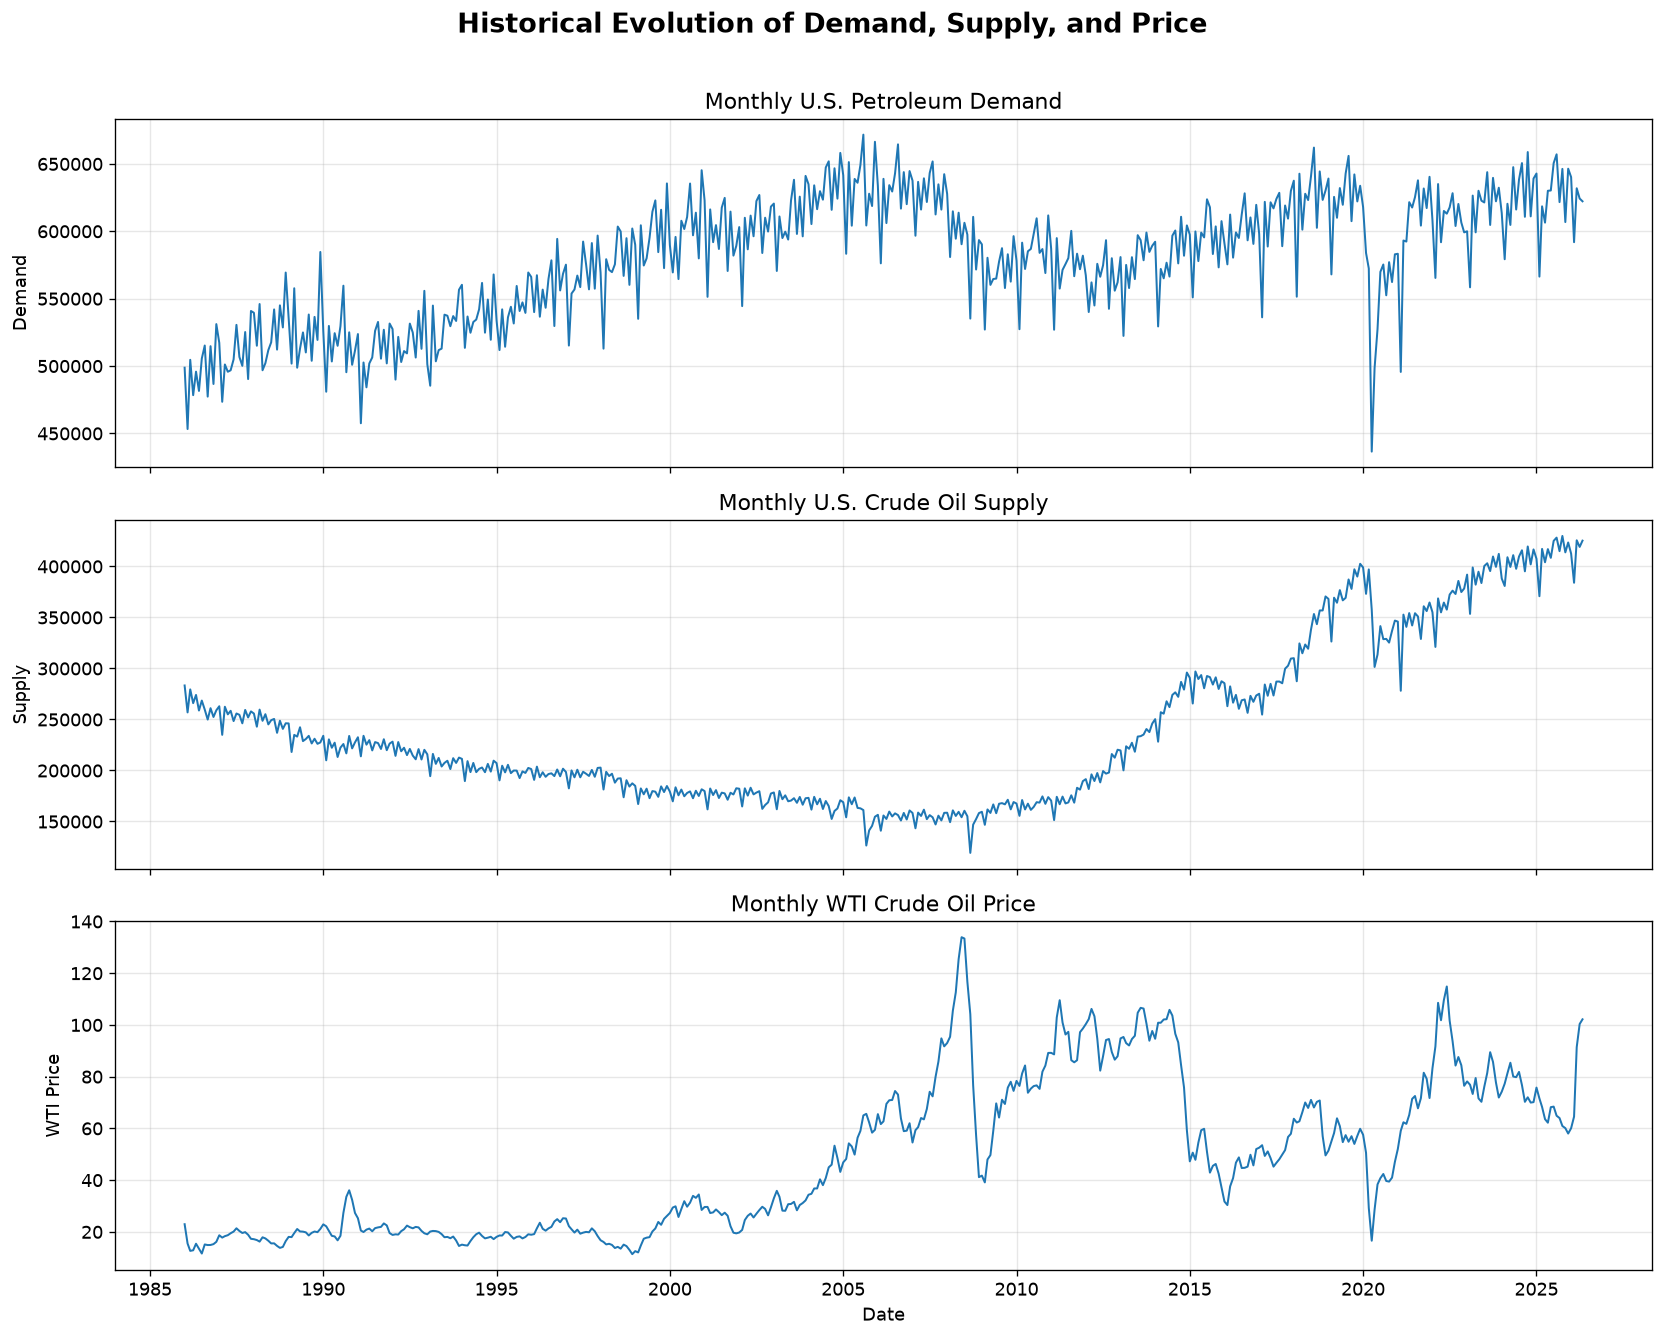

In [14]:
# ============================================================
# CELL 6: EXPLORATORY TIME-SERIES VISUALIZATION
# ============================================================

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 11),
    sharex=True
)

# ------------------------------------------------------------
# Demand
# ------------------------------------------------------------
axes[0].plot(
    df["date"],
    df["demand"],
    linewidth=1.2
)

axes[0].set_title("Monthly U.S. Petroleum Demand")
axes[0].set_ylabel("Demand")
axes[0].grid(True, alpha=0.3)


# ------------------------------------------------------------
# Supply
# ------------------------------------------------------------
axes[1].plot(
    df["date"],
    df["supply"],
    linewidth=1.2
)

axes[1].set_title("Monthly U.S. Crude Oil Supply")
axes[1].set_ylabel("Supply")
axes[1].grid(True, alpha=0.3)


# ------------------------------------------------------------
# WTI Price
# ------------------------------------------------------------
axes[2].plot(
    df["date"],
    df["price"],
    linewidth=1.2
)

axes[2].set_title("Monthly WTI Crude Oil Price")
axes[2].set_ylabel("WTI Price")
axes[2].set_xlabel("Date")
axes[2].grid(True, alpha=0.3)


fig.suptitle(
    "Historical Evolution of Demand, Supply, and Price",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

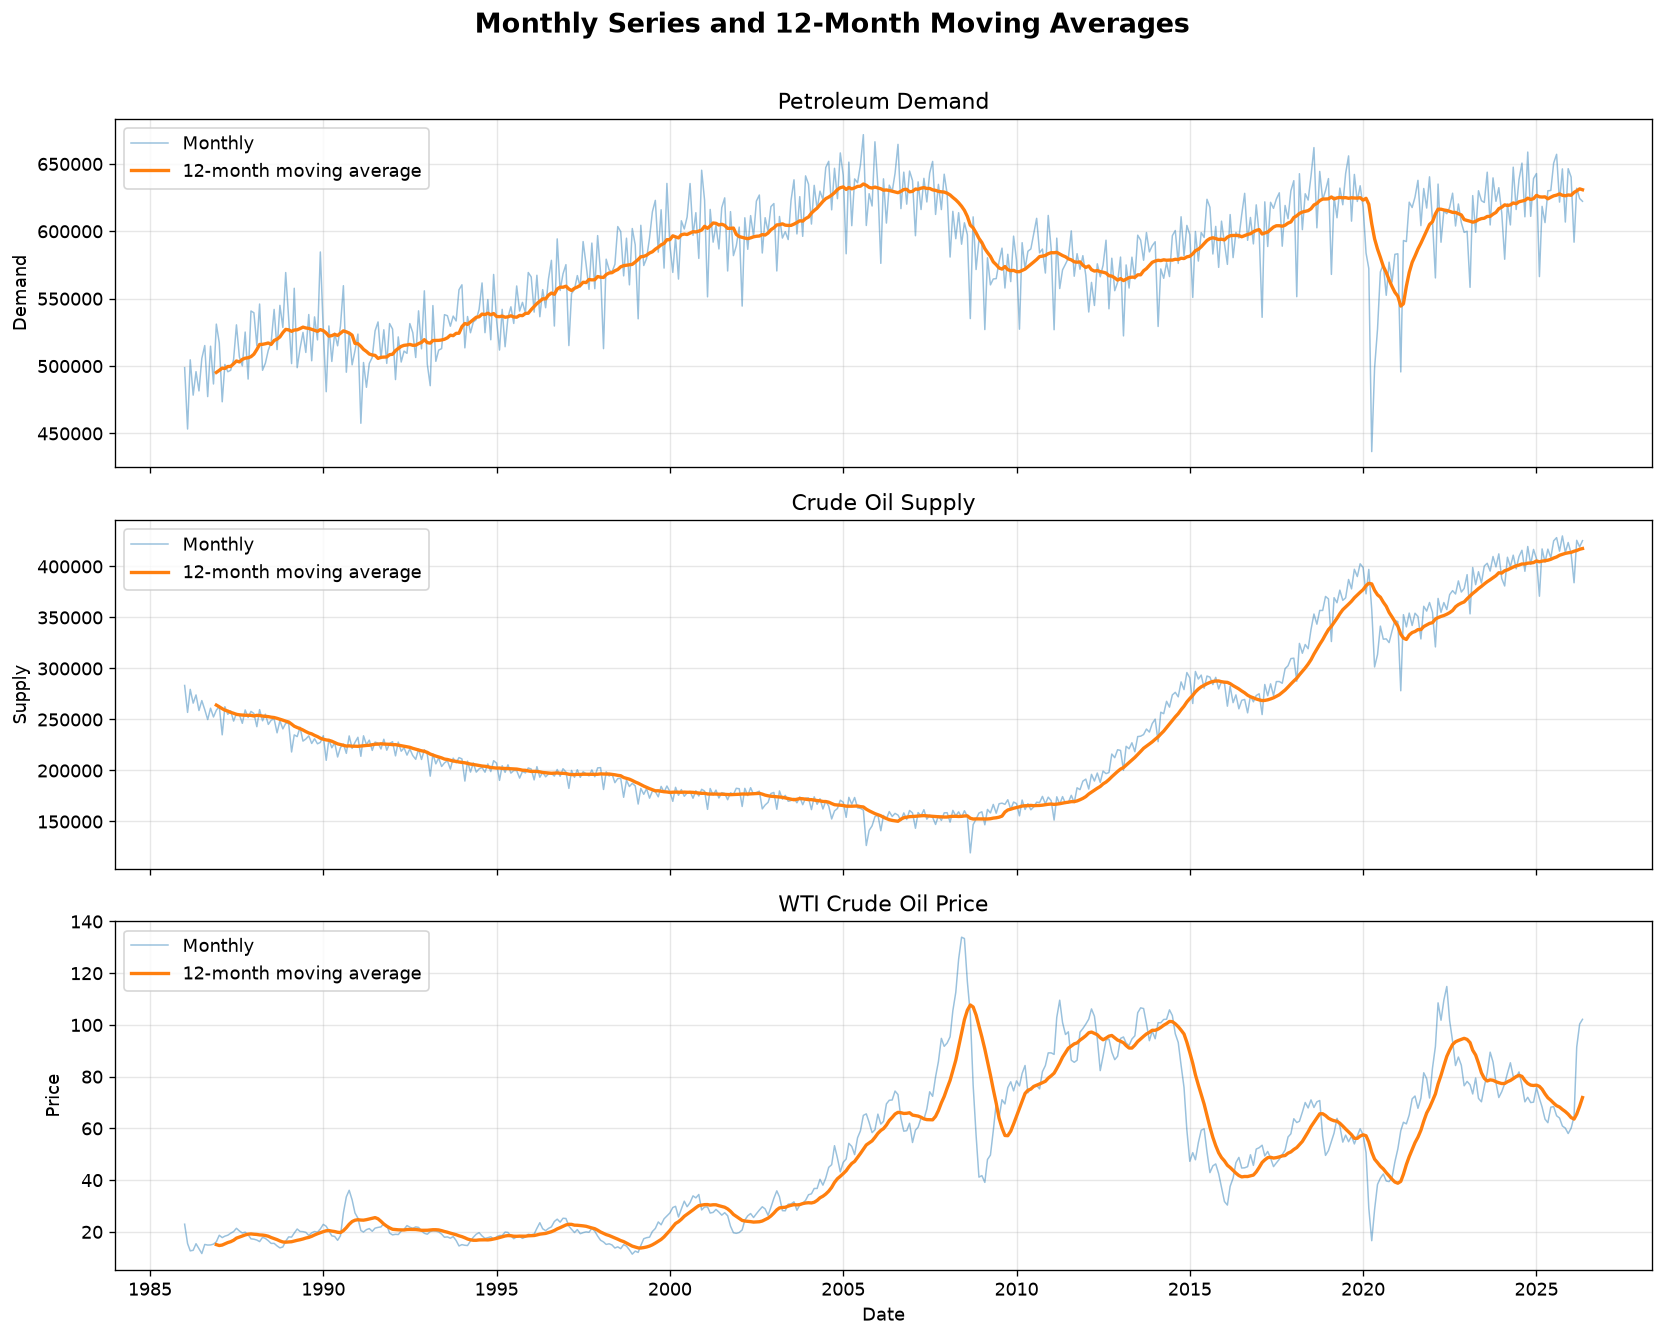

In [15]:
# ============================================================
# CELL 6B: 12-MONTH ROLLING MEANS
# ============================================================

df["demand_ma12"] = df["demand"].rolling(window=12).mean()
df["supply_ma12"] = df["supply"].rolling(window=12).mean()
df["price_ma12"] = df["price"].rolling(window=12).mean()


fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 11),
    sharex=True
)


# Demand
axes[0].plot(
    df["date"],
    df["demand"],
    alpha=0.45,
    linewidth=0.9,
    label="Monthly"
)

axes[0].plot(
    df["date"],
    df["demand_ma12"],
    linewidth=2,
    label="12-month moving average"
)

axes[0].set_title("Petroleum Demand")
axes[0].set_ylabel("Demand")
axes[0].legend()
axes[0].grid(True, alpha=0.3)


# Supply
axes[1].plot(
    df["date"],
    df["supply"],
    alpha=0.45,
    linewidth=0.9,
    label="Monthly"
)

axes[1].plot(
    df["date"],
    df["supply_ma12"],
    linewidth=2,
    label="12-month moving average"
)

axes[1].set_title("Crude Oil Supply")
axes[1].set_ylabel("Supply")
axes[1].legend()
axes[1].grid(True, alpha=0.3)


# Price
axes[2].plot(
    df["date"],
    df["price"],
    alpha=0.45,
    linewidth=0.9,
    label="Monthly"
)

axes[2].plot(
    df["date"],
    df["price_ma12"],
    linewidth=2,
    label="12-month moving average"
)

axes[2].set_title("WTI Crude Oil Price")
axes[2].set_ylabel("Price")
axes[2].set_xlabel("Date")
axes[2].legend()
axes[2].grid(True, alpha=0.3)


fig.suptitle(
    "Monthly Series and 12-Month Moving Averages",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

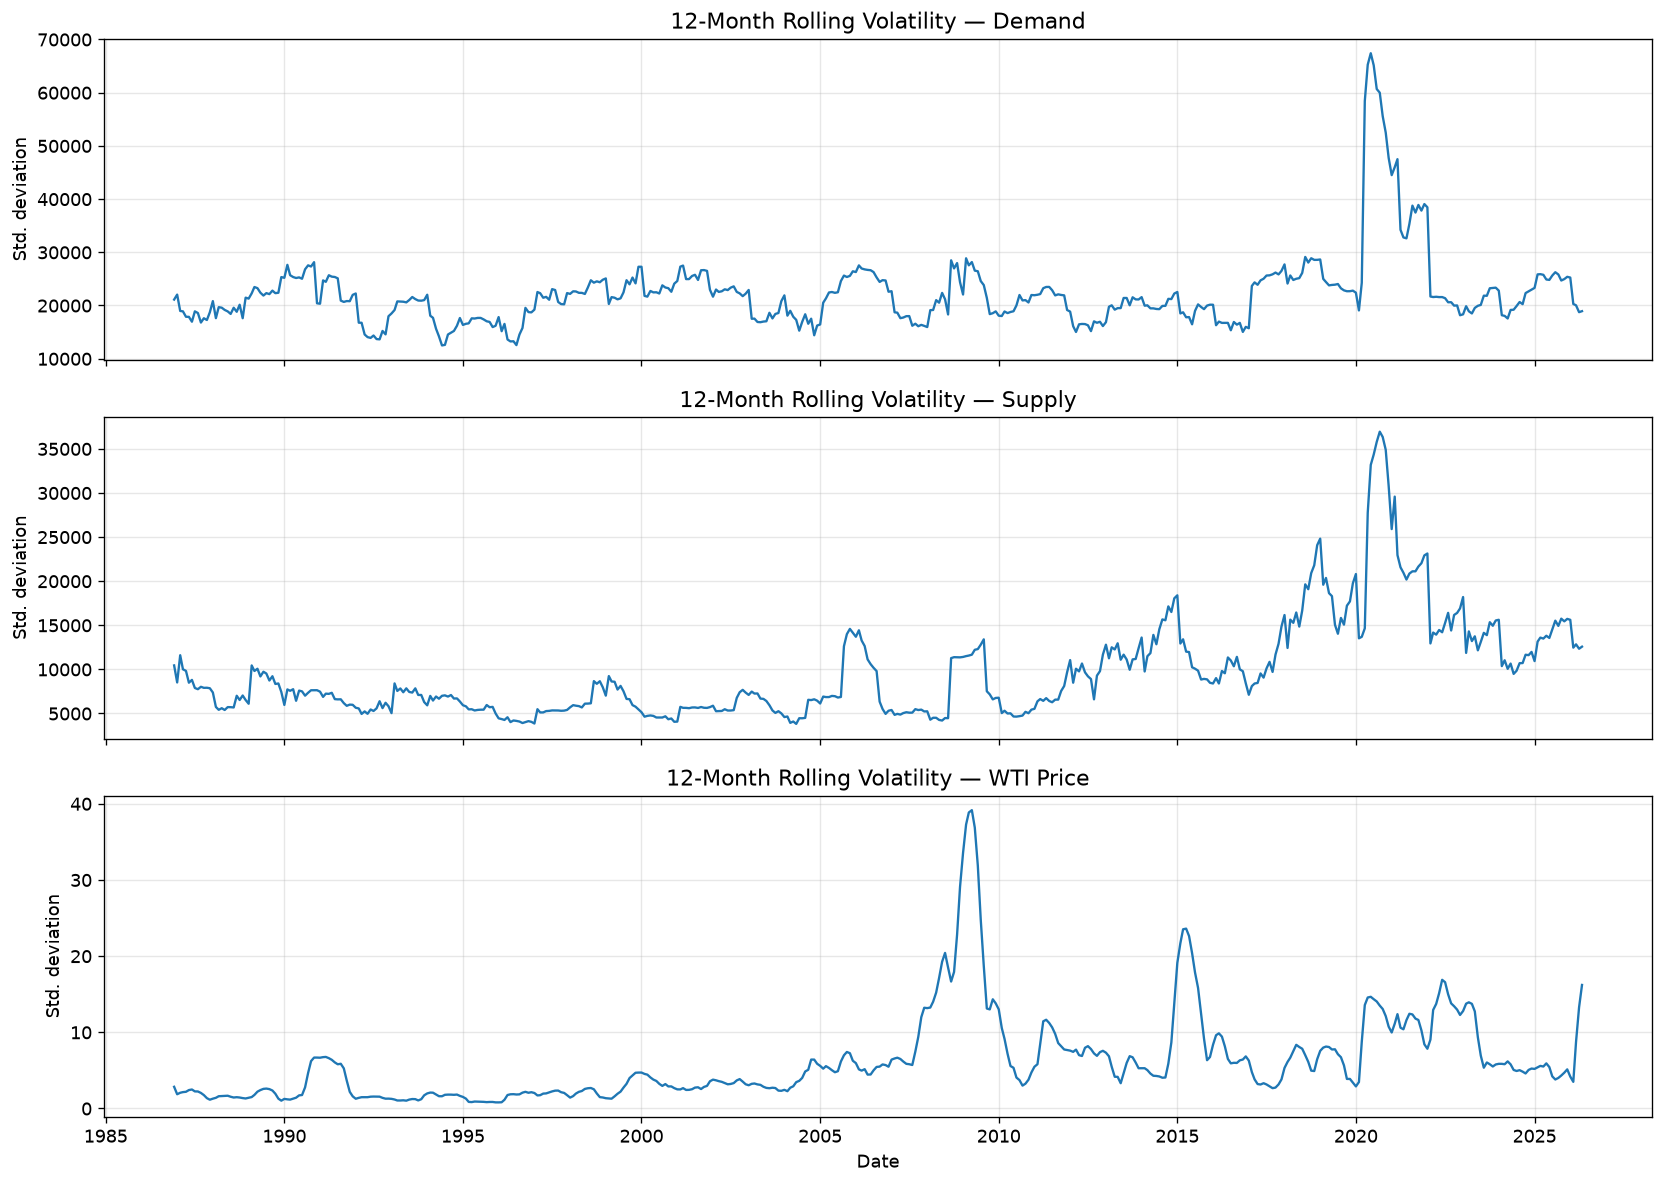

In [16]:
# ============================================================
# CELL 6D: 12-MONTH ROLLING VOLATILITY
# ============================================================

rolling_window = 12

df["demand_vol12"] = df["demand"].rolling(rolling_window).std()
df["supply_vol12"] = df["supply"].rolling(rolling_window).std()
df["price_vol12"] = df["price"].rolling(rolling_window).std()


fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 10),
    sharex=True
)

axes[0].plot(
    df["date"],
    df["demand_vol12"],
    linewidth=1.4
)
axes[0].set_title("12-Month Rolling Volatility — Demand")
axes[0].set_ylabel("Std. deviation")
axes[0].grid(True, alpha=0.3)


axes[1].plot(
    df["date"],
    df["supply_vol12"],
    linewidth=1.4
)
axes[1].set_title("12-Month Rolling Volatility — Supply")
axes[1].set_ylabel("Std. deviation")
axes[1].grid(True, alpha=0.3)


axes[2].plot(
    df["date"],
    df["price_vol12"],
    linewidth=1.4
)
axes[2].set_title("12-Month Rolling Volatility — WTI Price")
axes[2].set_ylabel("Std. deviation")
axes[2].set_xlabel("Date")
axes[2].grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# CELL 7A: CONTEMPORANEOUS CORRELATION ANALYSIS
# ============================================================

variables = ["demand", "supply", "price"]

# Pearson correlation
pearson_corr = df[variables].corr(method="pearson")

# Spearman correlation
spearman_corr = df[variables].corr(method="spearman")

print("=" * 60)
print("PEARSON CORRELATION")
print("=" * 60)
display(pearson_corr.round(4))

print("\n" + "=" * 60)
print("SPEARMAN CORRELATION")
print("=" * 60)
display(spearman_corr.round(4))

PEARSON CORRELATION


,demand,supply,price
demand,1.0000,0.2061,0.4766
supply,0.2061,1.0000,0.2417
price,0.4766,0.2417,1.0000



SPEARMAN CORRELATION


,demand,supply,price
demand,1.0000,0.0288,0.5252
supply,0.0288,1.0000,0.0753
price,0.5252,0.0753,1.0000


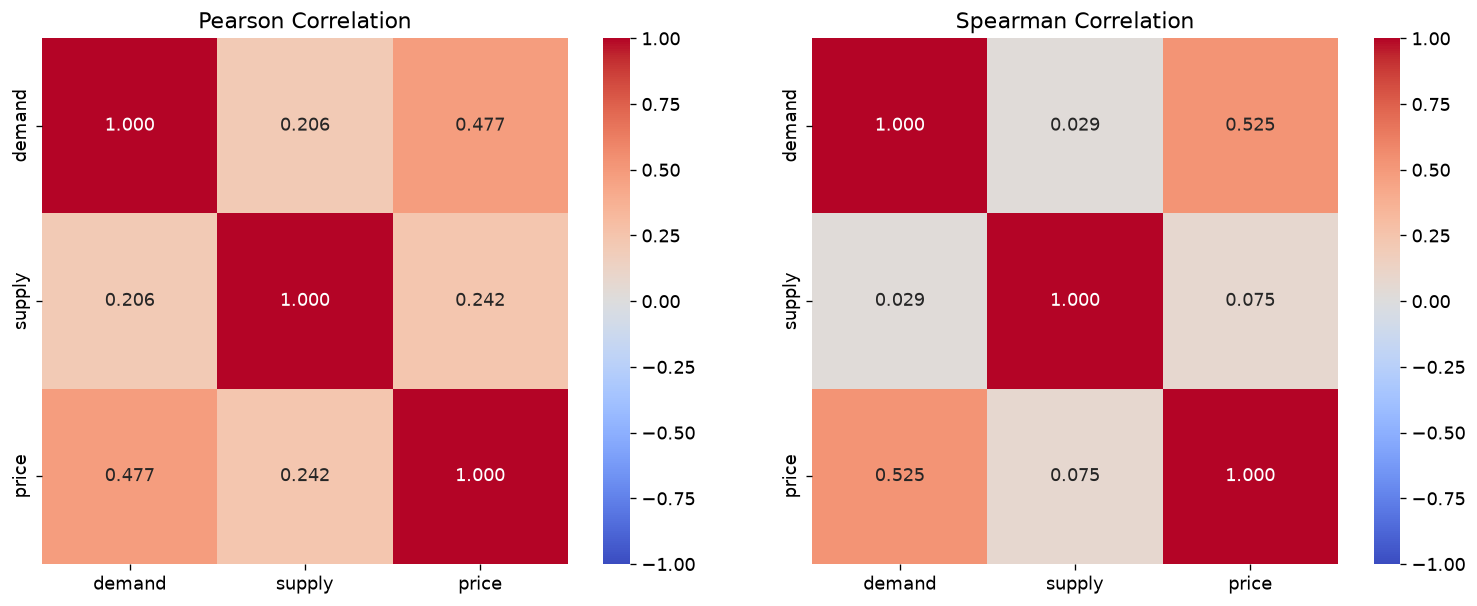

In [18]:
# ============================================================
# CELL 7B: CORRELATION HEATMAPS
# ============================================================

import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=axes[0]
)

axes[0].set_title("Pearson Correlation")


sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=axes[1]
)

axes[1].set_title("Spearman Correlation")

plt.tight_layout()
plt.show()

In [19]:
# ============================================================
# CELL 7C: LEAD-LAG CORRELATION FUNCTION
# ============================================================

def lagged_correlation(predictor, target, max_lag=24):
    """
    Calculate Corr(X_{t-k}, Y_t) for k = 0,...,max_lag.

    Positive lag k means the predictor occurs k months
    BEFORE the target.

    Example:
        lag = 6
        Corr(Demand_{t-6}, Price_t)
    """

    results = []

    for lag in range(max_lag + 1):

        x = predictor.shift(lag)

        valid = pd.concat(
            [x, target],
            axis=1
        ).dropna()

        r, p_value = stats.pearsonr(
            valid.iloc[:, 0],
            valid.iloc[:, 1]
        )

        results.append({
            "lag": lag,
            "correlation": r,
            "p_value": p_value,
            "n": len(valid)
        })

    return pd.DataFrame(results)

In [20]:
MAX_LAG = 24

demand_price_lag = lagged_correlation(
    df["demand"],
    df["price"],
    MAX_LAG
)

supply_price_lag = lagged_correlation(
    df["supply"],
    df["price"],
    MAX_LAG
)

print("Demand → Price")
display(demand_price_lag.round(4))

print("\nSupply → Price")
display(supply_price_lag.round(4))

Demand → Price


,lag,correlation,p_value,n
0,0,0.4766,0.0,485
1,1,0.4748,0.0,484
2,2,0.4733,0.0,483
3,3,0.4770,0.0,482
4,4,0.4757,0.0,481
5,5,0.4779,0.0,480
6,6,0.4808,0.0,479
7,7,0.4850,0.0,478
8,8,0.4860,0.0,477
9,9,0.4866,0.0,476



Supply → Price


,lag,correlation,p_value,n
0,0,0.2417,0.0000,485
1,1,0.2302,0.0000,484
2,2,0.2205,0.0000,483
3,3,0.2115,0.0000,482
4,4,0.2023,0.0000,481
5,5,0.1938,0.0000,480
6,6,0.1857,0.0000,479
7,7,0.1772,0.0001,478
8,8,0.1678,0.0002,477
9,9,0.1598,0.0005,476


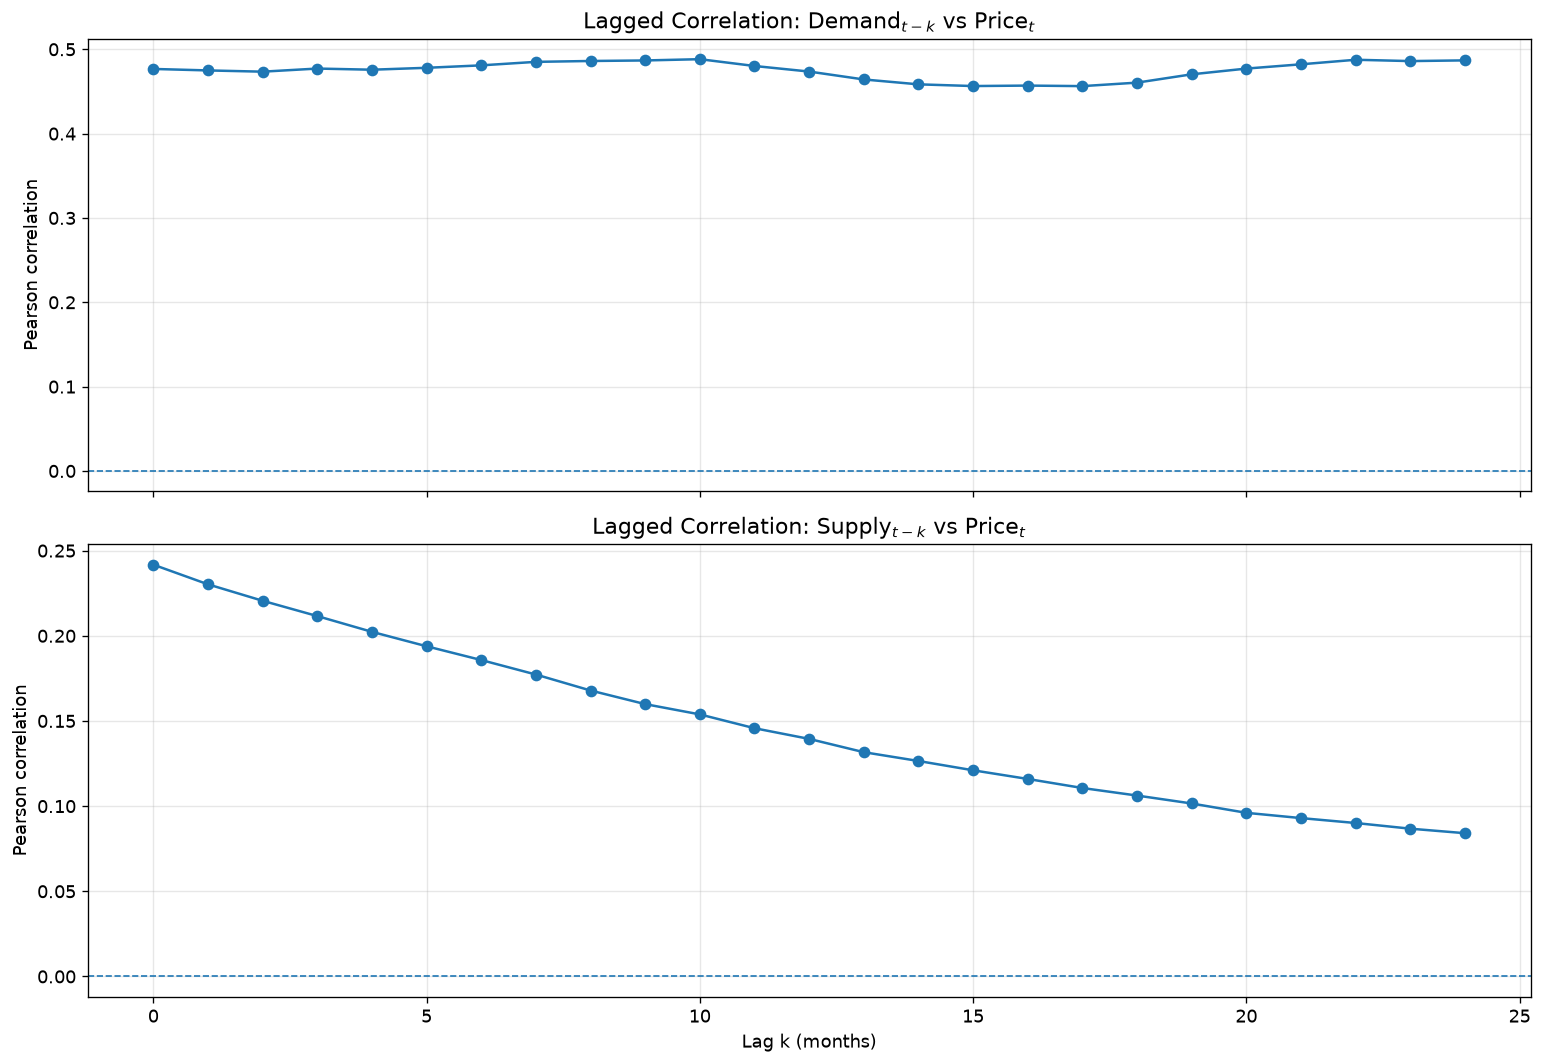

In [21]:
# ============================================================
# CELL 7D: LEAD-LAG CORRELATION PLOTS
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 9),
    sharex=True
)

# Demand -> Price
axes[0].plot(
    demand_price_lag["lag"],
    demand_price_lag["correlation"],
    marker="o",
    linewidth=1.5
)

axes[0].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[0].set_title(
    r"Lagged Correlation: Demand$_{t-k}$ vs Price$_t$"
)

axes[0].set_ylabel("Pearson correlation")
axes[0].grid(True, alpha=0.3)


# Supply -> Price
axes[1].plot(
    supply_price_lag["lag"],
    supply_price_lag["correlation"],
    marker="o",
    linewidth=1.5
)

axes[1].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[1].set_title(
    r"Lagged Correlation: Supply$_{t-k}$ vs Price$_t$"
)

axes[1].set_xlabel("Lag k (months)")
axes[1].set_ylabel("Pearson correlation")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
# ============================================================
# CELL 7E: STRONGEST LAGGED ASSOCIATIONS
# ============================================================

def strongest_lags(results, top_n=10):

    temp = results.copy()

    # Exclude contemporaneous lag
    temp = temp[temp["lag"] > 0]

    temp["abs_correlation"] = temp["correlation"].abs()

    return (
        temp
        .sort_values(
            "abs_correlation",
            ascending=False
        )
        .head(top_n)
    )


print("=" * 60)
print("STRONGEST DEMAND → PRICE LAGS")
print("=" * 60)

display(
    strongest_lags(
        demand_price_lag
    ).round(4)
)


print("\n" + "=" * 60)
print("STRONGEST SUPPLY → PRICE LAGS")
print("=" * 60)

display(
    strongest_lags(
        supply_price_lag
    ).round(4)
)

STRONGEST DEMAND → PRICE LAGS


,lag,correlation,p_value,n,abs_correlation
10,10,0.4881,0.0,475,0.4881
22,22,0.4875,0.0,463,0.4875
24,24,0.4867,0.0,461,0.4867
9,9,0.4866,0.0,476,0.4866
8,8,0.4860,0.0,477,0.4860
23,23,0.4859,0.0,462,0.4859
7,7,0.4850,0.0,478,0.4850
21,21,0.4821,0.0,464,0.4821
6,6,0.4808,0.0,479,0.4808
11,11,0.4801,0.0,474,0.4801



STRONGEST SUPPLY → PRICE LAGS


,lag,correlation,p_value,n,abs_correlation
1,1,0.2302,0.0000,484,0.2302
2,2,0.2205,0.0000,483,0.2205
3,3,0.2115,0.0000,482,0.2115
4,4,0.2023,0.0000,481,0.2023
5,5,0.1938,0.0000,480,0.1938
6,6,0.1857,0.0000,479,0.1857
7,7,0.1772,0.0001,478,0.1772
8,8,0.1678,0.0002,477,0.1678
9,9,0.1598,0.0005,476,0.1598
10,10,0.1538,0.0008,475,0.1538


In [23]:
# ============================================================
# CELL 7F: ALL PAIRWISE DIRECTIONAL LAG RELATIONSHIPS
# ============================================================

lag_relationships = {
    "Demand → Price": ("demand", "price"),
    "Supply → Price": ("supply", "price"),
    "Price → Demand": ("price", "demand"),
    "Price → Supply": ("price", "supply"),
    "Demand → Supply": ("demand", "supply"),
    "Supply → Demand": ("supply", "demand")
}


all_lag_results = {}

for name, (predictor, target) in lag_relationships.items():

    result = lagged_correlation(
        df[predictor],
        df[target],
        MAX_LAG
    )

    all_lag_results[name] = result

In [24]:
# ============================================================
# CELL 7G: SUMMARY OF STRONGEST LEAD-LAG RELATIONSHIPS
# ============================================================

summary = []

for name, result in all_lag_results.items():

    temp = result[result["lag"] > 0].copy()

    temp["abs_corr"] = temp["correlation"].abs()

    best = temp.loc[
        temp["abs_corr"].idxmax()
    ]

    summary.append({
        "Relationship": name,
        "Best lag (months)": int(best["lag"]),
        "Correlation": best["correlation"],
        "Absolute correlation": best["abs_corr"],
        "p-value": best["p_value"],
        "N": int(best["n"])
    })


lag_summary = pd.DataFrame(summary)

display(
    lag_summary.round(4)
)

,Relationship,Best lag (months),Correlation,Absolute correlation,p-value,N
0,Demand → Price,10,0.4881,0.4881,0.0000,475
1,Supply → Price,1,0.2302,0.2302,0.0000,484
2,Price → Demand,1,0.4685,0.4685,0.0000,484
3,Price → Supply,24,0.3717,0.3717,0.0000,461
4,Demand → Supply,5,0.1903,0.1903,0.0000,480
5,Supply → Demand,2,0.1653,0.1653,0.0003,483


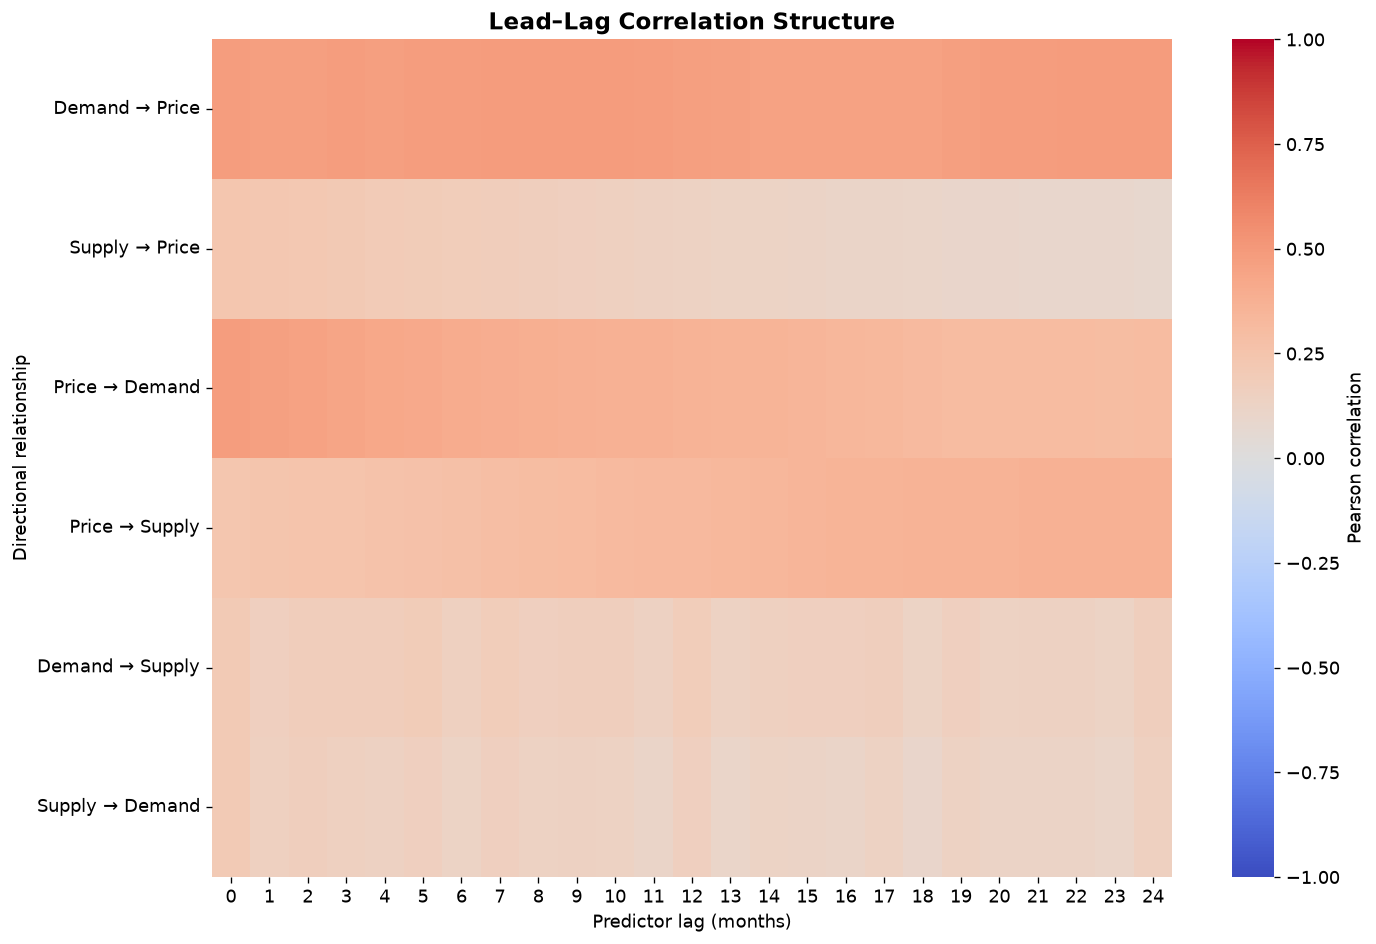

In [25]:
# ============================================================
# CELL 7H: LEAD-LAG CORRELATION HEATMAP
# ============================================================

lag_matrix = pd.DataFrame({
    name: result.set_index("lag")["correlation"]
    for name, result in all_lag_results.items()
})

plt.figure(figsize=(12, 8))

sns.heatmap(
    lag_matrix.T,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title(
    "Lead–Lag Correlation Structure",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predictor lag (months)")
plt.ylabel("Directional relationship")

plt.tight_layout()
plt.show()

In [26]:
# ============================================================
# CELL 8A: STATIONARITY TEST FUNCTIONS
# ============================================================

from statsmodels.tsa.stattools import adfuller, kpss


def adf_test(series, name):
    """
    Augmented Dickey-Fuller test.

    H0: Series has a unit root (nonstationary)
    H1: Series is stationary
    """

    x = series.dropna()

    result = adfuller(
        x,
        autolag="AIC"
    )

    return {
        "Variable": name,
        "ADF statistic": result[0],
        "ADF p-value": result[1],
        "ADF lags": result[2],
        "ADF N": result[3],
        "ADF conclusion":
            "Stationary"
            if result[1] < 0.05
            else "Nonstationary"
    }


def kpss_test(series, name):
    """
    KPSS test.

    H0: Series is stationary
    H1: Series is nonstationary
    """

    x = series.dropna()

    result = kpss(
        x,
        regression="c",
        nlags="auto"
    )

    return {
        "Variable": name,
        "KPSS statistic": result[0],
        "KPSS p-value": result[1],
        "KPSS lags": result[2],
        "KPSS conclusion":
            "Stationary"
            if result[1] >= 0.05
            else "Nonstationary"
    }


print("Stationarity test functions created successfully.")

Stationarity test functions created successfully.


In [27]:
# ============================================================
# CELL 8B: STATIONARITY TESTS — LEVEL SERIES
# ============================================================

stationarity_results = []

for variable in ["demand", "supply", "price"]:

    adf_result = adf_test(
        df[variable],
        variable
    )

    kpss_result = kpss_test(
        df[variable],
        variable
    )

    combined = {
        **adf_result,
        **{
            k: v
            for k, v in kpss_result.items()
            if k != "Variable"
        }
    }

    stationarity_results.append(combined)


stationarity_level = pd.DataFrame(
    stationarity_results
)

display(
    stationarity_level.round(4)
)

C:\Users\SOBAdmin\AppData\Local\Temp\ipykernel_12444\1224946309.py:46: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  result = kpss(
C:\Users\SOBAdmin\AppData\Local\Temp\ipykernel_12444\1224946309.py:46: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  result = kpss(
C:\Users\SOBAdmin\AppData\Local\Temp\ipykernel_12444\1224946309.py:46: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  result = kpss(


,Variable,ADF statistic,ADF p-value,ADF lags,ADF N,ADF conclusion,KPSS statistic,KPSS p-value,KPSS lags,KPSS conclusion
0,demand,-1.9041,0.3301,18,466,Nonstationary,2.2502,0.01,12,Nonstationary
1,supply,0.3416,0.9792,15,469,Nonstationary,1.9804,0.01,12,Nonstationary
2,price,-2.4125,0.1382,1,483,Nonstationary,2.5225,0.01,12,Nonstationary


In [28]:
# ============================================================
# CELL 8C: FIRST DIFFERENCES
# ============================================================

df["demand_diff"] = df["demand"].diff()
df["supply_diff"] = df["supply"].diff()
df["price_diff"] = df["price"].diff()

display(
    df[
        [
            "date",
            "demand",
            "demand_diff",
            "supply",
            "supply_diff",
            "price",
            "price_diff"
        ]
    ].head(10)
)

,date,demand,demand_diff,supply,supply_diff,price,price_diff
0,1986-01-01,498728,NaN,283248,NaN,22.925455,NaN
1,1986-02-01,453209,-45519.0,256855,-26393.0,15.454737,-7.470718
2,1986-03-01,504565,51356.0,279413,22558.0,12.612500,-2.842237
3,1986-04-01,478339,-26226.0,265917,-13496.0,12.843636,0.231136
4,1986-05-01,495789,17450.0,273964,8047.0,15.377619,2.533983
5,1986-06-01,481482,-14307.0,258700,-15264.0,13.425714,-1.951905
6,1986-07-01,505514,24032.0,268448,9748.0,11.584545,-1.841169
7,1986-08-01,515167,9653.0,259580,-8868.0,15.096667,3.512121
8,1986-09-01,477269,-37898.0,249843,-9737.0,14.866667,-0.230000
9,1986-10-01,514674,37405.0,260984,11141.0,14.896818,0.030152


In [29]:
# ============================================================
# CELL 8D-1: CHECK POSITIVITY BEFORE LOG TRANSFORMATION
# ============================================================

for variable in ["demand", "supply", "price"]:

    minimum = df[variable].min()

    print(
        f"{variable:10s} minimum = {minimum:.6f}"
    )

demand     minimum = 436455.000000
supply     minimum = 119208.000000
price      minimum = 11.347273


In [30]:
# ============================================================
# CELL 8D-2: LOG LEVELS AND LOG DIFFERENCES
# ============================================================

for variable in ["demand", "supply", "price"]:

    df[f"log_{variable}"] = np.log(
        df[variable]
    )

    df[f"{variable}_logdiff"] = (
        df[f"log_{variable}"].diff()
    )


display(
    df[
        [
            "date",
            "demand_logdiff",
            "supply_logdiff",
            "price_logdiff"
        ]
    ].head(10)
)

,date,demand_logdiff,supply_logdiff,price_logdiff
0,1986-01-01,NaN,NaN,NaN
1,1986-02-01,-0.095707,-0.097811,-0.394332
2,1986-03-01,0.107343,0.084179,-0.203227
3,1986-04-01,-0.053377,-0.049507,0.018160
4,1986-05-01,0.035831,0.029812,0.180065
5,1986-06-01,-0.029282,-0.057328,-0.135741
6,1986-07-01,0.048707,0.036988,-0.147500
7,1986-08-01,0.018915,-0.033592,0.264802
8,1986-09-01,-0.076411,-0.038232,-0.015352
9,1986-10-01,0.075453,0.043626,0.002026


In [31]:
# ============================================================
# CELL 8E: STATIONARITY TESTS — FIRST DIFFERENCES
# ============================================================

diff_variables = {
    "ΔDemand": "demand_diff",
    "ΔSupply": "supply_diff",
    "ΔPrice": "price_diff"
}

diff_results = []

for name, variable in diff_variables.items():

    adf_result = adf_test(
        df[variable],
        name
    )

    kpss_result = kpss_test(
        df[variable],
        name
    )

    combined = {
        **adf_result,
        **{
            k: v
            for k, v in kpss_result.items()
            if k != "Variable"
        }
    }

    diff_results.append(combined)


stationarity_diff = pd.DataFrame(
    diff_results
)

display(
    stationarity_diff.round(4)
)

C:\Users\SOBAdmin\AppData\Local\Temp\ipykernel_12444\1224946309.py:46: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(
C:\Users\SOBAdmin\AppData\Local\Temp\ipykernel_12444\1224946309.py:46: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  result = kpss(
C:\Users\SOBAdmin\AppData\Local\Temp\ipykernel_12444\1224946309.py:46: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(


,Variable,ADF statistic,ADF p-value,ADF lags,ADF N,ADF conclusion,KPSS statistic,KPSS p-value,KPSS lags,KPSS conclusion
0,ΔDemand,-5.9596,0.0000,17,466,Stationary,0.0200,0.10,7,Stationary
1,ΔSupply,-4.4932,0.0002,14,469,Stationary,0.7899,0.01,21,Nonstationary
2,ΔPrice,-10.1773,0.0000,5,478,Stationary,0.0331,0.10,5,Stationary


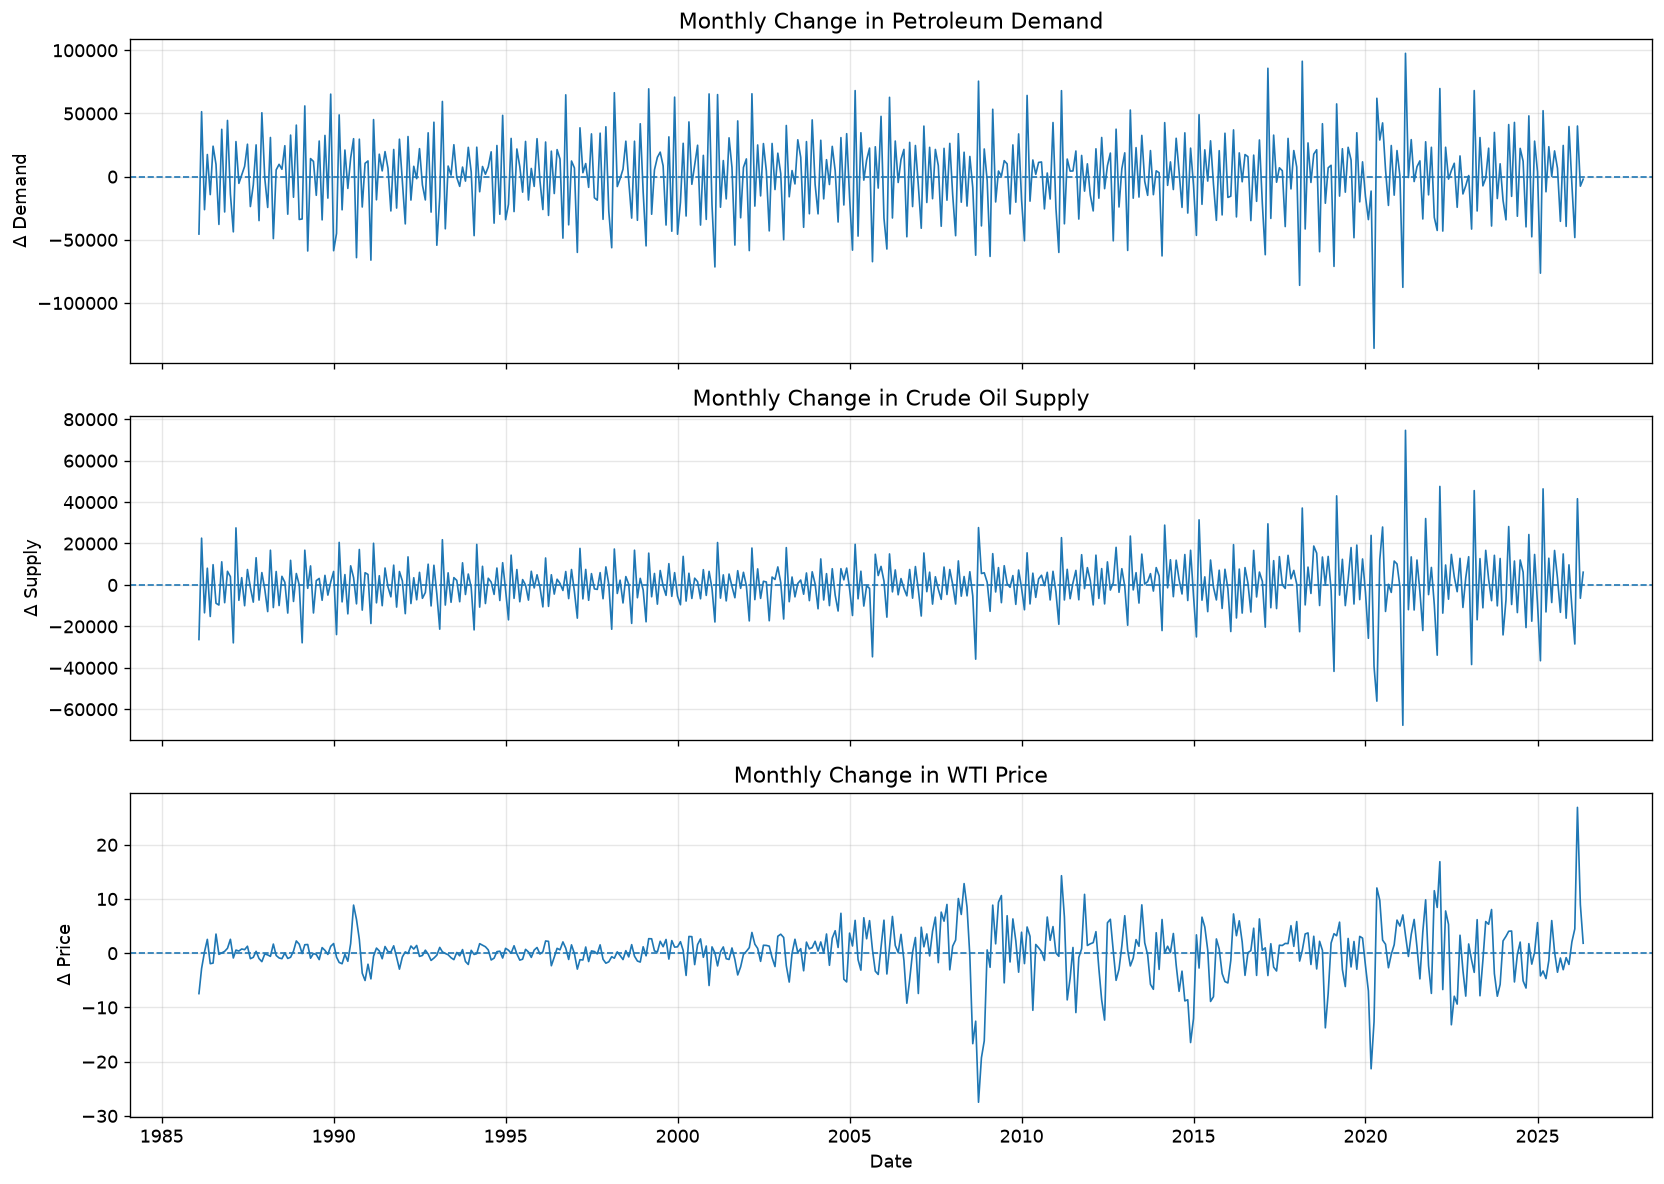

In [32]:
# ============================================================
# CELL 8H: FIRST-DIFFERENCE TIME SERIES
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 10),
    sharex=True
)


axes[0].plot(
    df["date"],
    df["demand_diff"],
    linewidth=1
)

axes[0].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[0].set_title(
    "Monthly Change in Petroleum Demand"
)

axes[0].set_ylabel("Δ Demand")
axes[0].grid(True, alpha=0.3)


axes[1].plot(
    df["date"],
    df["supply_diff"],
    linewidth=1
)

axes[1].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[1].set_title(
    "Monthly Change in Crude Oil Supply"
)

axes[1].set_ylabel("Δ Supply")
axes[1].grid(True, alpha=0.3)


axes[2].plot(
    df["date"],
    df["price_diff"],
    linewidth=1
)

axes[2].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[2].set_title(
    "Monthly Change in WTI Price"
)

axes[2].set_ylabel("Δ Price")
axes[2].set_xlabel("Date")
axes[2].grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

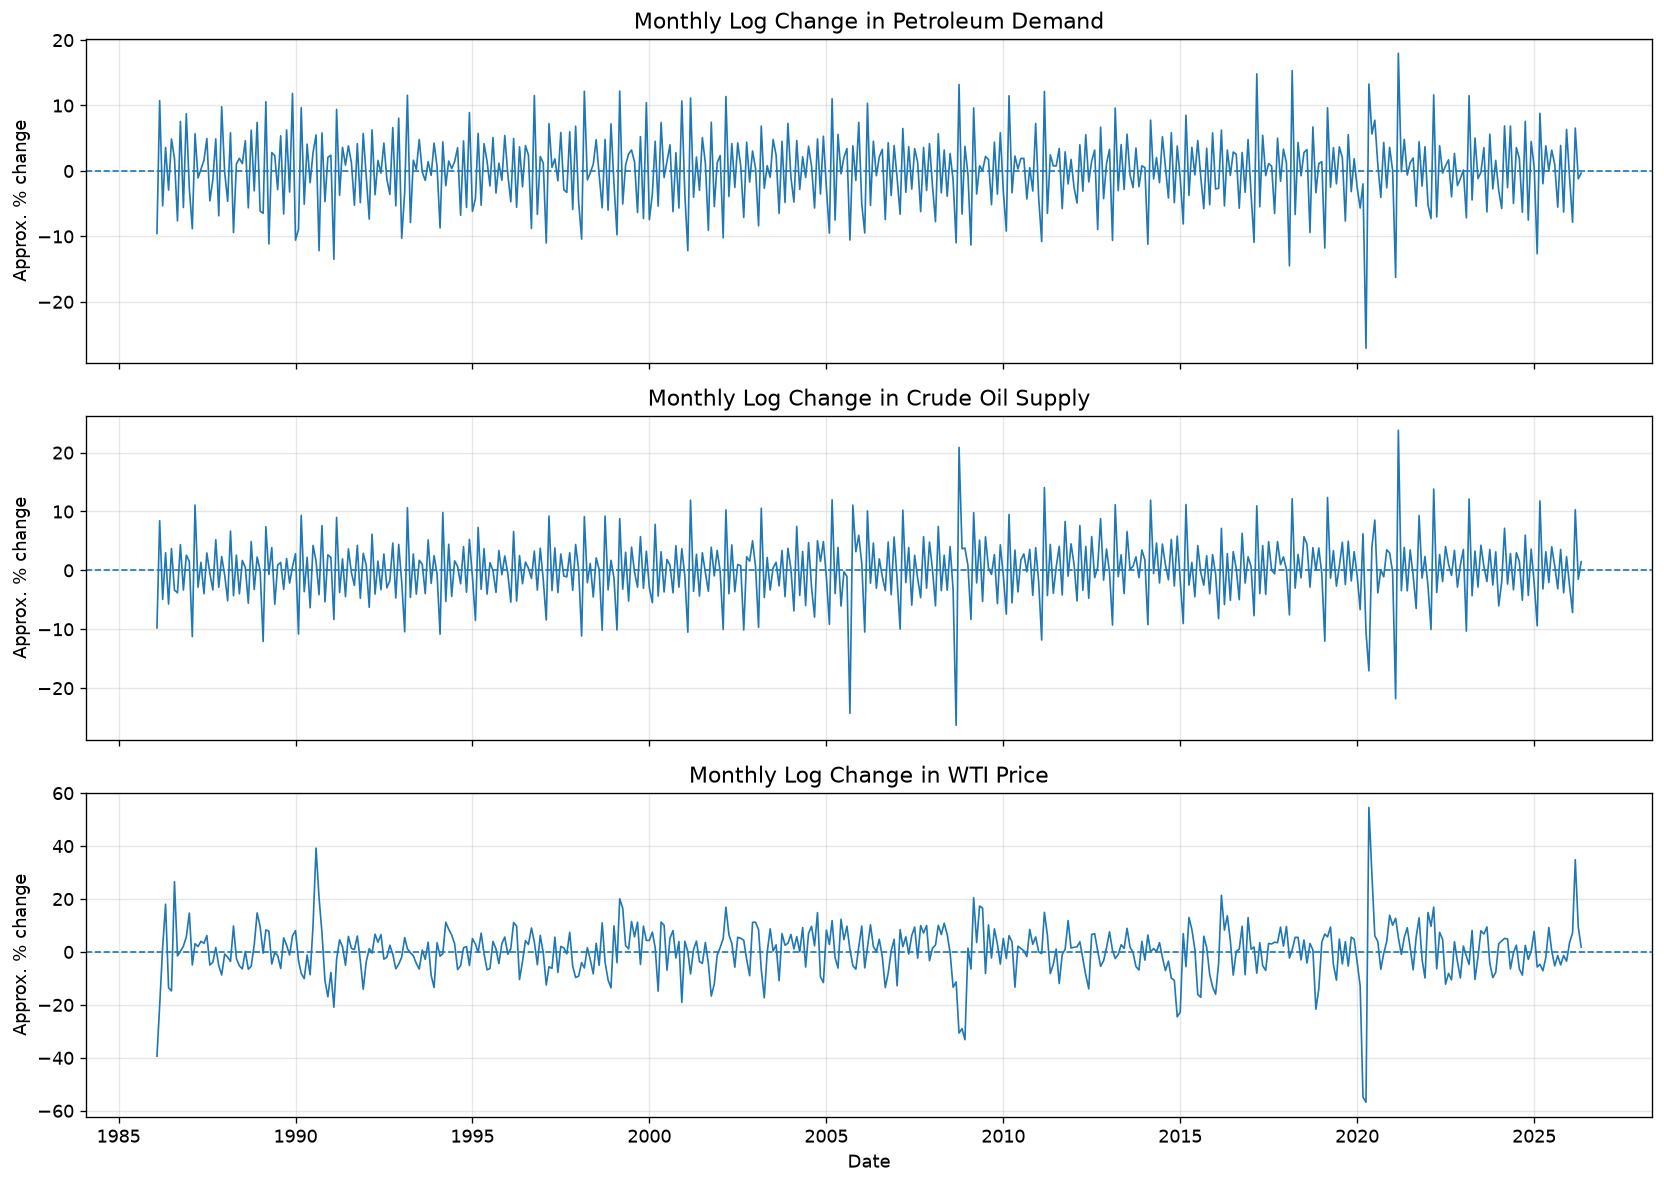

In [33]:
# ============================================================
# CELL 8I: LOG-DIFFERENCE TIME SERIES
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 10),
    sharex=True
)


axes[0].plot(
    df["date"],
    100 * df["demand_logdiff"],
    linewidth=1
)

axes[0].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[0].set_title(
    "Monthly Log Change in Petroleum Demand"
)

axes[0].set_ylabel("Approx. % change")
axes[0].grid(True, alpha=0.3)


axes[1].plot(
    df["date"],
    100 * df["supply_logdiff"],
    linewidth=1
)

axes[1].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[1].set_title(
    "Monthly Log Change in Crude Oil Supply"
)

axes[1].set_ylabel("Approx. % change")
axes[1].grid(True, alpha=0.3)


axes[2].plot(
    df["date"],
    100 * df["price_logdiff"],
    linewidth=1
)

axes[2].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[2].set_title(
    "Monthly Log Change in WTI Price"
)

axes[2].set_ylabel("Approx. % change")
axes[2].set_xlabel("Date")
axes[2].grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

In [34]:
# ============================================================
# CELL 9A: CORRELATION OF STATIONARY LOG CHANGES
# ============================================================

logdiff_cols = [
    "demand_logdiff",
    "supply_logdiff",
    "price_logdiff"
]

stationary_data = df[
    ["date"] + logdiff_cols
].dropna().copy()

# Pearson
logdiff_pearson = stationary_data[
    logdiff_cols
].corr(method="pearson")

# Spearman
logdiff_spearman = stationary_data[
    logdiff_cols
].corr(method="spearman")


print("=" * 60)
print("PEARSON CORRELATION — LOG DIFFERENCES")
print("=" * 60)
display(logdiff_pearson.round(4))


print("\n" + "=" * 60)
print("SPEARMAN CORRELATION — LOG DIFFERENCES")
print("=" * 60)
display(logdiff_spearman.round(4))

PEARSON CORRELATION — LOG DIFFERENCES


,demand_logdiff,supply_logdiff,price_logdiff
demand_logdiff,1.0000,0.7981,0.1214
supply_logdiff,0.7981,1.0000,0.0001
price_logdiff,0.1214,0.0001,1.0000



SPEARMAN CORRELATION — LOG DIFFERENCES


,demand_logdiff,supply_logdiff,price_logdiff
demand_logdiff,1.0000,0.8192,0.0223
supply_logdiff,0.8192,1.0000,0.0074
price_logdiff,0.0223,0.0074,1.0000


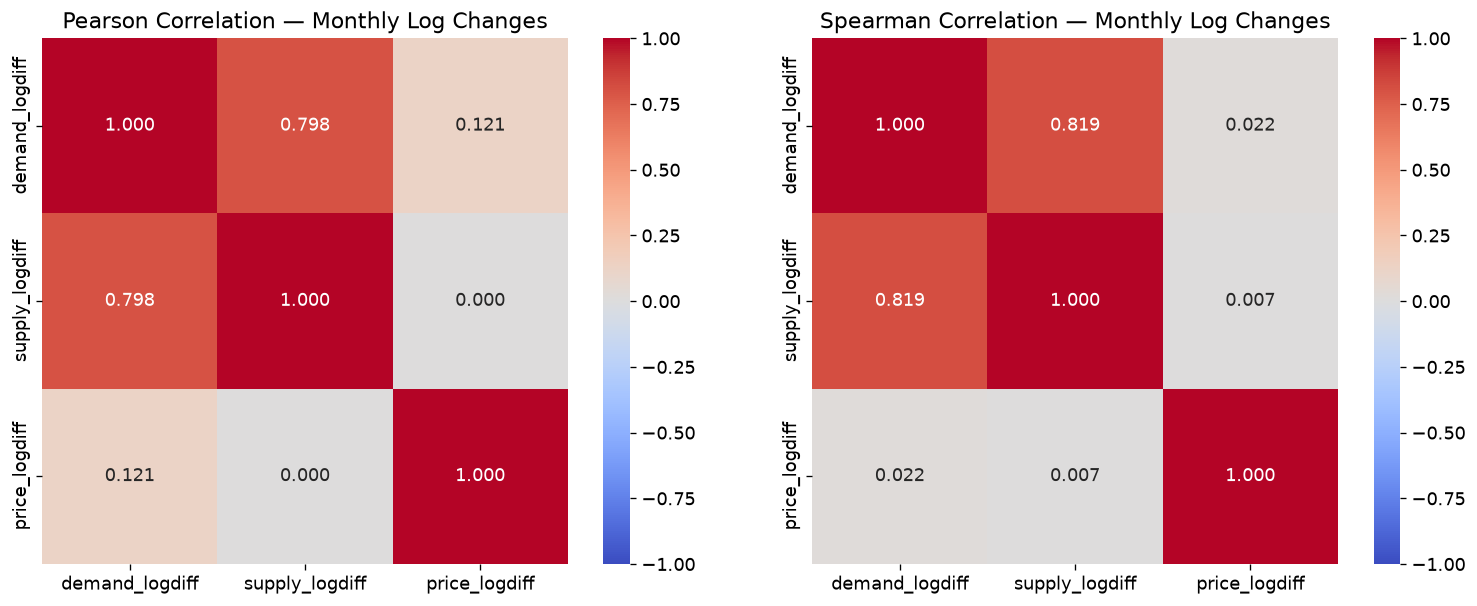

In [35]:
# ============================================================
# CELL 9B: CORRELATION HEATMAPS — LOG DIFFERENCES
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

sns.heatmap(
    logdiff_pearson,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=axes[0]
)

axes[0].set_title(
    "Pearson Correlation — Monthly Log Changes"
)


sns.heatmap(
    logdiff_spearman,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=axes[1]
)

axes[1].set_title(
    "Spearman Correlation — Monthly Log Changes"
)

plt.tight_layout()
plt.show()

In [36]:
# ============================================================
# CELL 9C: LEAD-LAG CORRELATIONS — LOG DIFFERENCES
# ============================================================

MAX_LAG = 24

demand_change_price_change = lagged_correlation(
    stationary_data["demand_logdiff"],
    stationary_data["price_logdiff"],
    MAX_LAG
)

supply_change_price_change = lagged_correlation(
    stationary_data["supply_logdiff"],
    stationary_data["price_logdiff"],
    MAX_LAG
)


print("=" * 60)
print("Δlog(Demand) → Δlog(Price)")
print("=" * 60)

display(
    demand_change_price_change.round(4)
)


print("\n" + "=" * 60)
print("Δlog(Supply) → Δlog(Price)")
print("=" * 60)

display(
    supply_change_price_change.round(4)
)

Δlog(Demand) → Δlog(Price)


,lag,correlation,p_value,n
0,0,0.1214,0.0075,484
1,1,0.0012,0.9795,483
2,2,-0.0433,0.3428,482
3,3,0.0470,0.3036,481
4,4,-0.0602,0.1877,480
5,5,0.0287,0.5305,479
6,6,-0.0214,0.6411,478
7,7,0.0080,0.8624,477
8,8,-0.0276,0.5478,476
9,9,-0.0189,0.6805,475



Δlog(Supply) → Δlog(Price)


,lag,correlation,p_value,n
0,0,0.0001,0.9976,484
1,1,-0.0466,0.3066,483
2,2,-0.0105,0.8175,482
3,3,0.0495,0.2786,481
4,4,-0.0640,0.1614,480
5,5,0.0256,0.5763,479
6,6,-0.0074,0.8714,478
7,7,-0.0129,0.7794,477
8,8,-0.0400,0.3843,476
9,9,-0.0671,0.1440,475


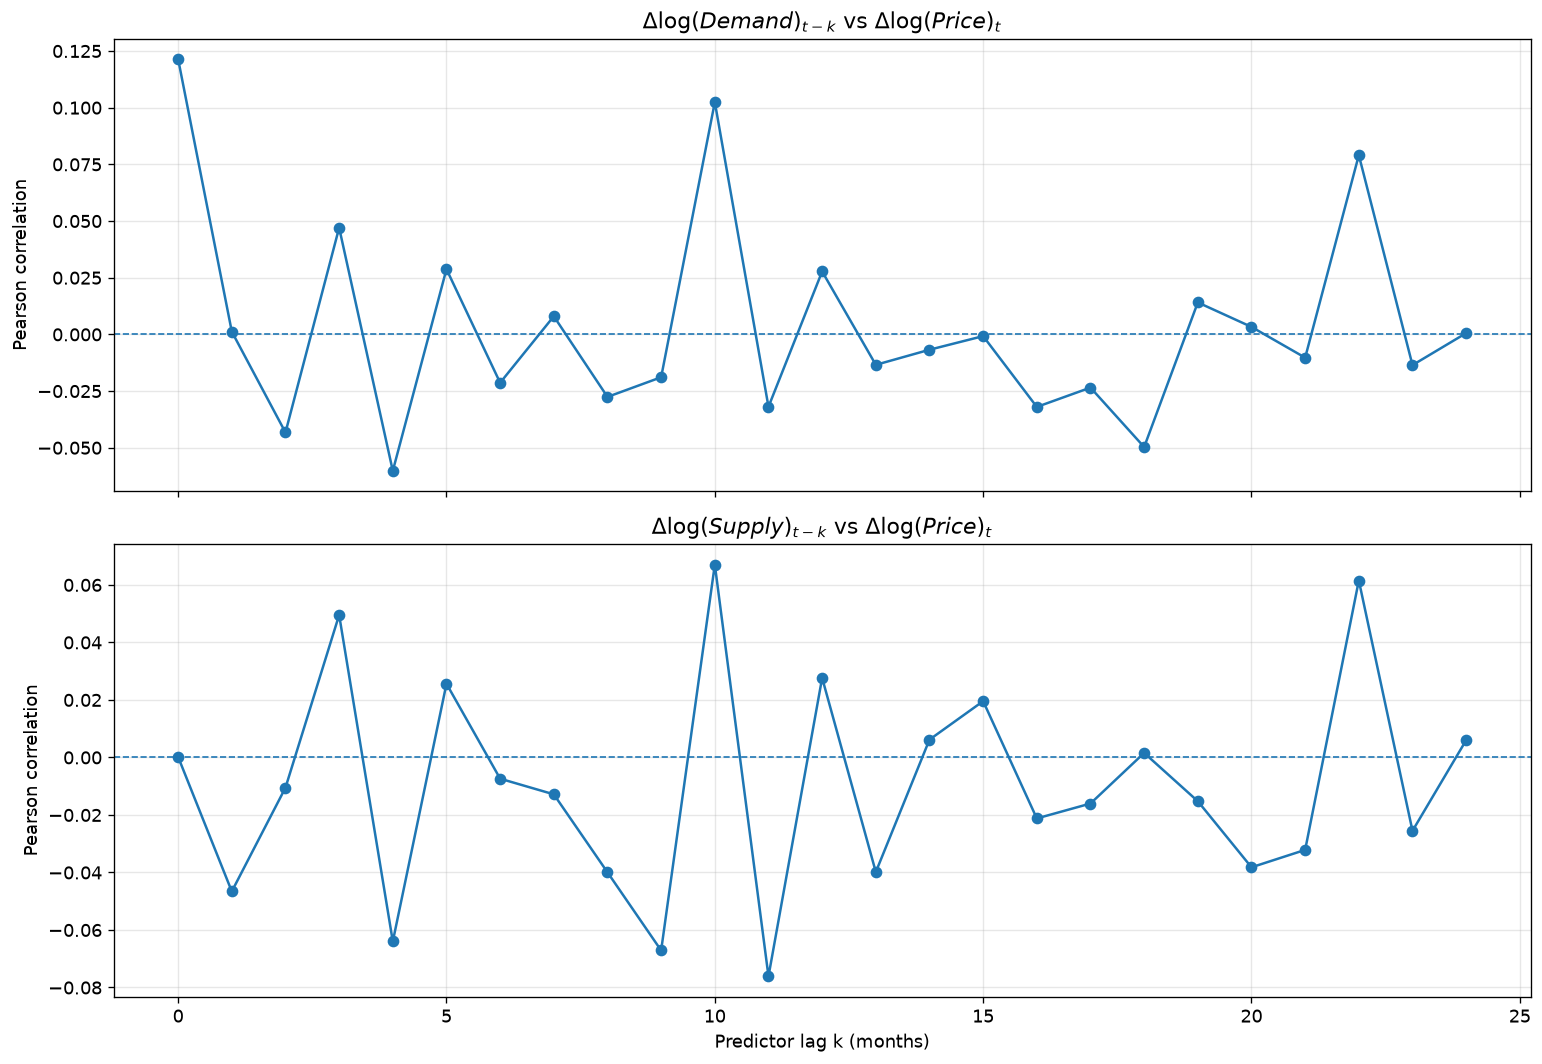

In [37]:
# ============================================================
# CELL 9D: LEAD-LAG PLOTS — STATIONARY SERIES
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 9),
    sharex=True
)


# Demand changes -> Price changes
axes[0].plot(
    demand_change_price_change["lag"],
    demand_change_price_change["correlation"],
    marker="o",
    linewidth=1.5
)

axes[0].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[0].set_title(
    r"$\Delta\log(Demand)_{t-k}$ vs "
    r"$\Delta\log(Price)_t$"
)

axes[0].set_ylabel(
    "Pearson correlation"
)

axes[0].grid(
    True,
    alpha=0.3
)


# Supply changes -> Price changes
axes[1].plot(
    supply_change_price_change["lag"],
    supply_change_price_change["correlation"],
    marker="o",
    linewidth=1.5
)

axes[1].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[1].set_title(
    r"$\Delta\log(Supply)_{t-k}$ vs "
    r"$\Delta\log(Price)_t$"
)

axes[1].set_xlabel(
    "Predictor lag k (months)"
)

axes[1].set_ylabel(
    "Pearson correlation"
)

axes[1].grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [38]:
# ============================================================
# CELL 9E: ALL DIRECTIONAL RELATIONSHIPS — LOG CHANGES
# ============================================================

stationary_relationships = {

    "Demand → Price":
        ("demand_logdiff", "price_logdiff"),

    "Supply → Price":
        ("supply_logdiff", "price_logdiff"),

    "Price → Demand":
        ("price_logdiff", "demand_logdiff"),

    "Price → Supply":
        ("price_logdiff", "supply_logdiff"),

    "Demand → Supply":
        ("demand_logdiff", "supply_logdiff"),

    "Supply → Demand":
        ("supply_logdiff", "demand_logdiff")
}


stationary_lag_results = {}


for name, (predictor, target) in stationary_relationships.items():

    stationary_lag_results[name] = lagged_correlation(
        stationary_data[predictor],
        stationary_data[target],
        MAX_LAG
    )


print(
    "All stationary lead-lag relationships calculated."
)

All stationary lead-lag relationships calculated.


In [39]:
# ============================================================
# CELL 9F: STRONGEST STATIONARY LEAD-LAG RELATIONSHIPS
# ============================================================

stationary_summary = []


for name, result in stationary_lag_results.items():

    # Exclude lag zero
    temp = result[
        result["lag"] > 0
    ].copy()

    temp["abs_corr"] = (
        temp["correlation"].abs()
    )

    best = temp.loc[
        temp["abs_corr"].idxmax()
    ]

    stationary_summary.append({

        "Relationship": name,

        "Best lag (months)":
            int(best["lag"]),

        "Correlation":
            best["correlation"],

        "Absolute correlation":
            best["abs_corr"],

        "p-value":
            best["p_value"],

        "N":
            int(best["n"])
    })


stationary_lag_summary = pd.DataFrame(
    stationary_summary
)


display(
    stationary_lag_summary.round(4)
)

,Relationship,Best lag (months),Correlation,Absolute correlation,p-value,N
0,Demand → Price,10,0.1024,0.1024,0.0258,474
1,Supply → Price,11,-0.0761,0.0761,0.0981,473
2,Price → Demand,2,0.0925,0.0925,0.0425,482
3,Price → Supply,2,0.1312,0.1312,0.0039,482
4,Demand → Supply,24,0.7229,0.7229,0.0000,460
5,Supply → Demand,12,0.7146,0.7146,0.0000,472


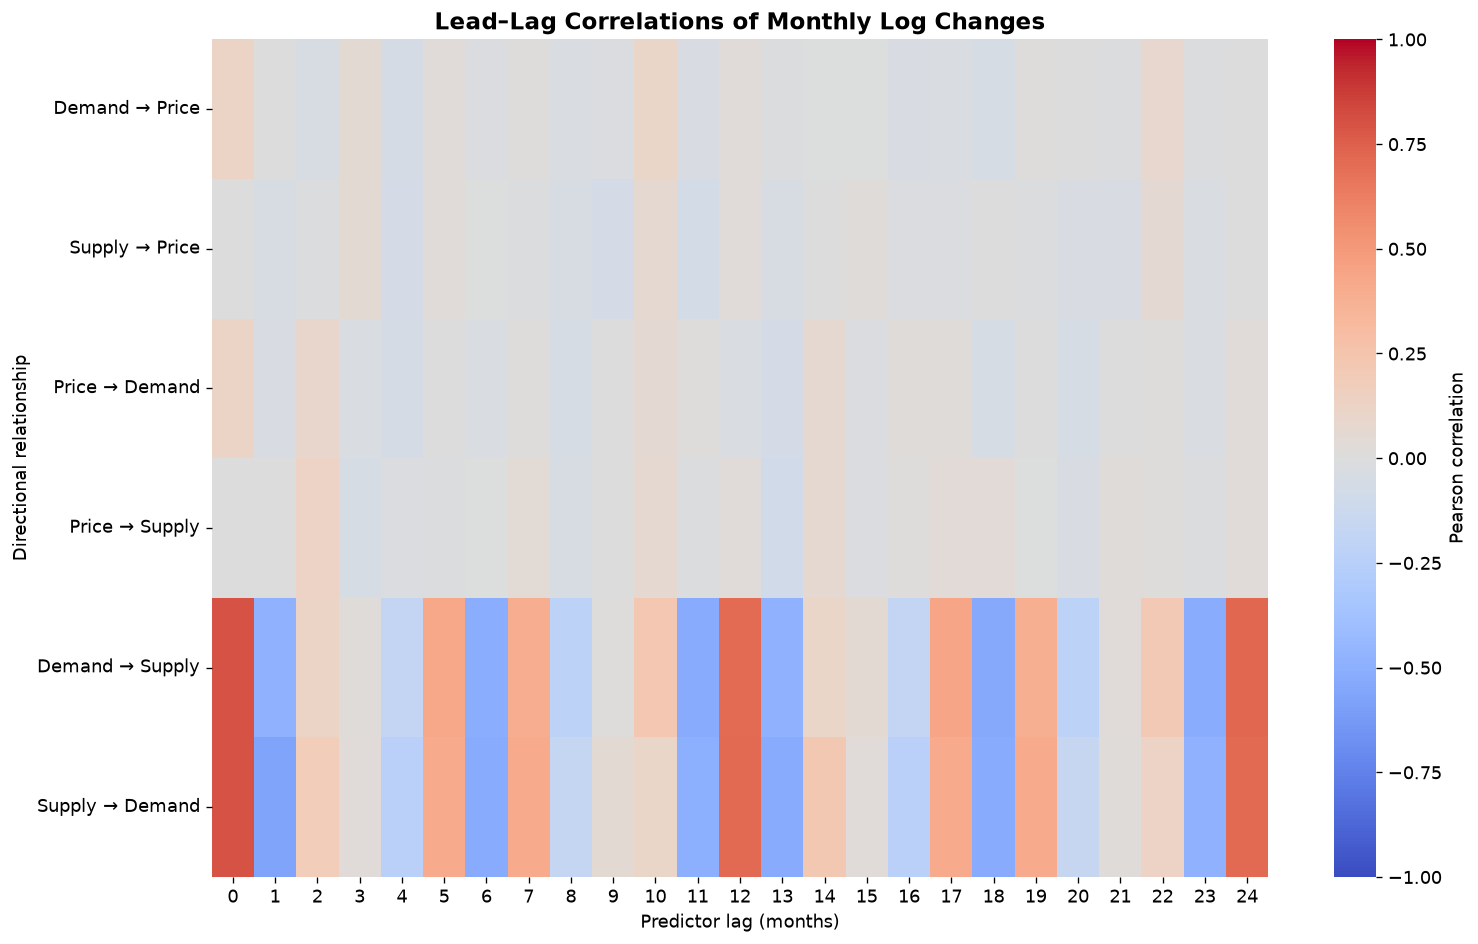

In [40]:
# ============================================================
# CELL 9G: STATIONARY LEAD-LAG HEATMAP
# ============================================================

stationary_lag_matrix = pd.DataFrame({

    name:
        result.set_index("lag")["correlation"]

    for name, result
    in stationary_lag_results.items()
})


plt.figure(
    figsize=(13, 8)
)


sns.heatmap(
    stationary_lag_matrix.T,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    cbar_kws={
        "label": "Pearson correlation"
    }
)


plt.title(
    "Lead–Lag Correlations of Monthly Log Changes",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Predictor lag (months)"
)

plt.ylabel(
    "Directional relationship"
)

plt.tight_layout()
plt.show()

In [41]:
# ============================================================
# CELL 9H: SELECTED ECONOMIC/TEMPORAL LAGS
# ============================================================

selected_lags = [
    1,
    3,
    6,
    12,
    18,
    24
]


selected_lag_table = []


for name, result in stationary_lag_results.items():

    temp = result[
        result["lag"].isin(selected_lags)
    ]

    for _, row in temp.iterrows():

        selected_lag_table.append({

            "Relationship": name,

            "Lag":
                int(row["lag"]),

            "Correlation":
                row["correlation"],

            "p-value":
                row["p_value"]
        })


selected_lag_table = pd.DataFrame(
    selected_lag_table
)


display(
    selected_lag_table
    .pivot(
        index="Relationship",
        columns="Lag",
        values="Correlation"
    )
    .round(4)
)

Lag,1,3,6,12,18,24
Relationship,,,,,,
Demand → Price,0.0012,0.0470,-0.0214,0.0277,-0.0497,0.0005
Demand → Supply,-0.4820,0.0162,-0.5153,0.7046,-0.5333,0.7229
Price → Demand,-0.0360,-0.0251,-0.0288,-0.0274,-0.0488,0.0255
Price → Supply,0.0067,-0.0514,-0.0069,0.0290,0.0318,0.0303
Supply → Demand,-0.5675,0.0309,-0.5261,0.7146,-0.5248,0.7133
Supply → Price,-0.0466,0.0495,-0.0074,0.0276,0.0015,0.0060


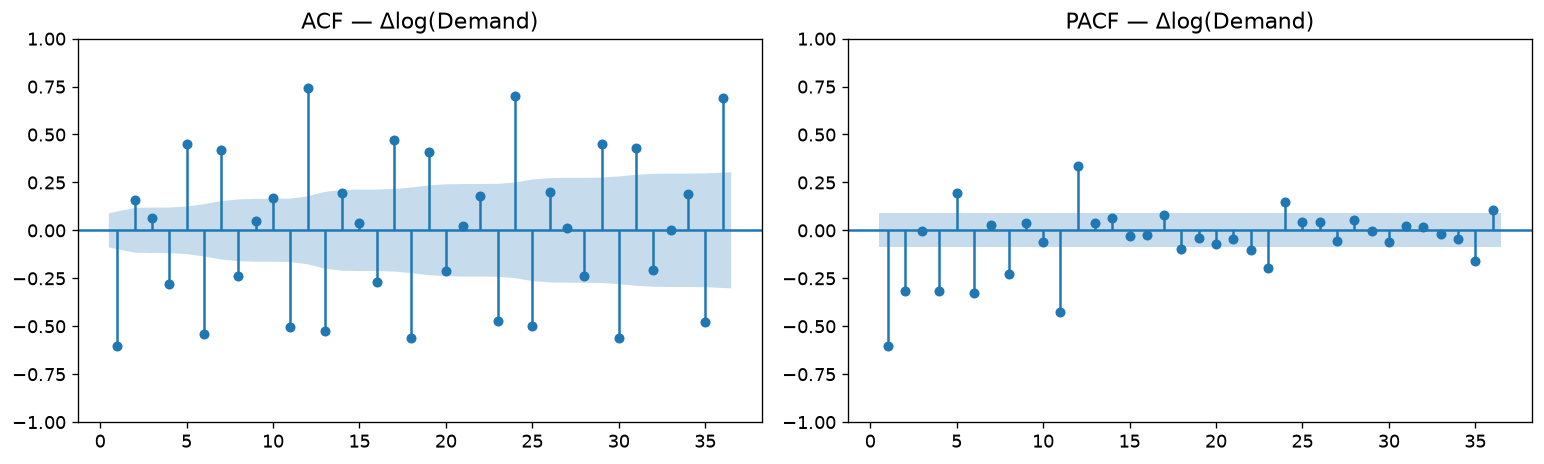

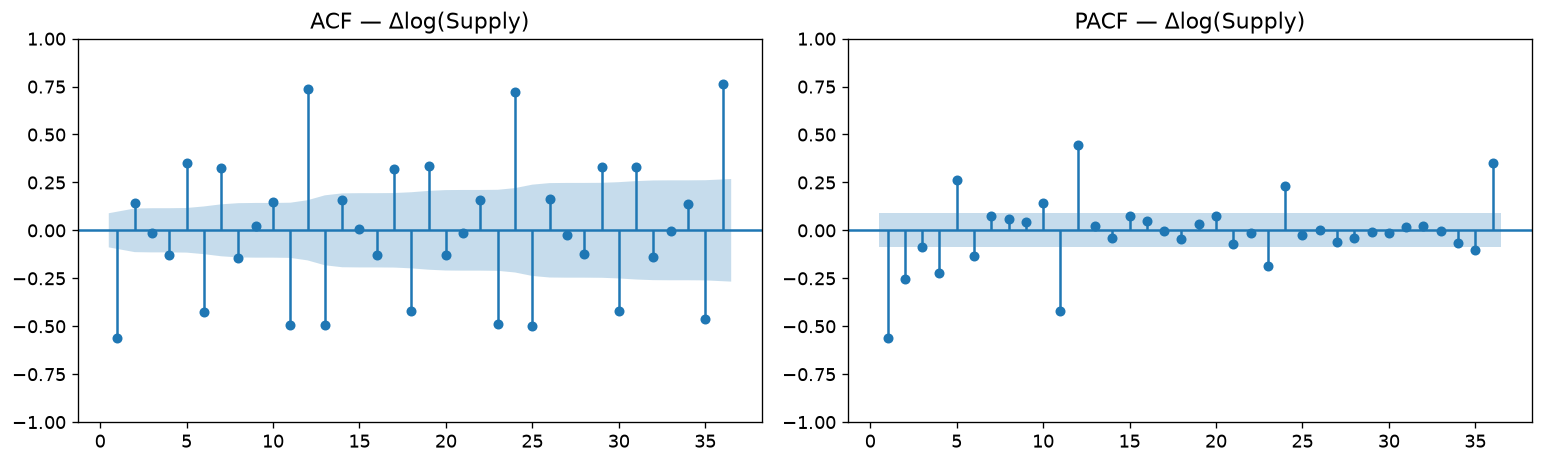

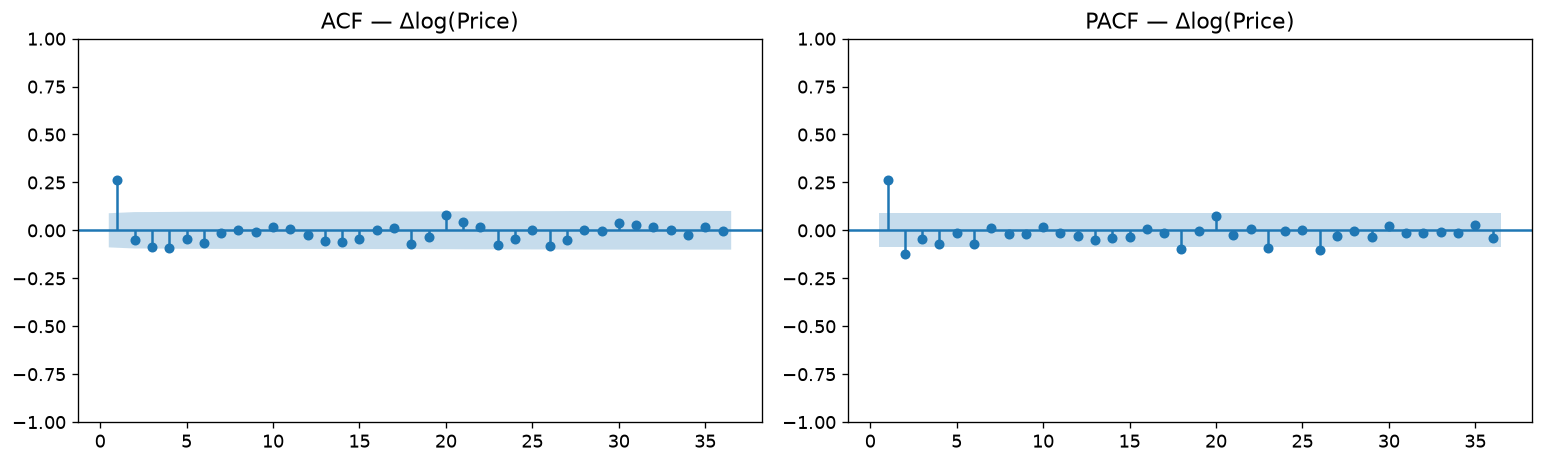

In [42]:
# ============================================================
# CELL 9I: ACF AND PACF — LOG DIFFERENCES
# ============================================================

variables_acf = {
    "Demand": "demand_logdiff",
    "Supply": "supply_logdiff",
    "Price": "price_logdiff"
}


for name, variable in variables_acf.items():

    series = df[
        variable
    ].dropna()

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 4)
    )

    plot_acf(
        series,
        lags=36,
        ax=axes[0],
        zero=False
    )

    axes[0].set_title(
        f"ACF — Δlog({name})"
    )


    plot_pacf(
        series,
        lags=36,
        ax=axes[1],
        zero=False,
        method="ywm"
    )

    axes[1].set_title(
        f"PACF — Δlog({name})"
    )


    plt.tight_layout()
    plt.show()

In [43]:
# ============================================================
# CELL 10A: FORECASTING CONFIGURATION
# ============================================================

# Forecast horizons that will eventually be evaluated
FORECAST_HORIZONS = [1, 3, 6, 12]

# Lags chosen a priori to capture:
# short-term dynamics + quarterly + semiannual + annual effects
LAGS = [1, 2, 3, 6, 12, 18, 24]

# Rolling windows
ROLLING_WINDOWS = [3, 6, 12]

# Primary raw variables
RAW_VARIABLES = [
    "demand",
    "supply",
    "price"
]

# Stationary transformations
CHANGE_VARIABLES = [
    "demand_logdiff",
    "supply_logdiff",
    "price_logdiff"
]

print("Forecast horizons :", FORECAST_HORIZONS)
print("Lags              :", LAGS)
print("Rolling windows   :", ROLLING_WINDOWS)

Forecast horizons : [1, 3, 6, 12]
Lags              : [1, 2, 3, 6, 12, 18, 24]
Rolling windows   : [3, 6, 12]


In [44]:
# ============================================================
# CELL 10B: CALENDAR / SEASONAL FEATURES
# ============================================================

df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year

df["month_sin"] = np.sin(
    2 * np.pi * df["month"] / 12
)

df["month_cos"] = np.cos(
    2 * np.pi * df["month"] / 12
)

display(
    df[
        [
            "date",
            "year",
            "month",
            "month_sin",
            "month_cos"
        ]
    ].head(15)
)

,date,year,month,month_sin,month_cos
0,1986-01-01,1986,1,5.000000e-01,8.660254e-01
1,1986-02-01,1986,2,8.660254e-01,5.000000e-01
2,1986-03-01,1986,3,1.000000e+00,6.123234e-17
3,1986-04-01,1986,4,8.660254e-01,-5.000000e-01
4,1986-05-01,1986,5,5.000000e-01,-8.660254e-01
5,1986-06-01,1986,6,1.224647e-16,-1.000000e+00
6,1986-07-01,1986,7,-5.000000e-01,-8.660254e-01
7,1986-08-01,1986,8,-8.660254e-01,-5.000000e-01
8,1986-09-01,1986,9,-1.000000e+00,-1.836970e-16
9,1986-10-01,1986,10,-8.660254e-01,5.000000e-01


In [45]:
# ============================================================
# CELL 10C: LAGGED FEATURES
# ============================================================

feature_df = df.copy()

lag_source_variables = (
    RAW_VARIABLES +
    CHANGE_VARIABLES
)

for variable in lag_source_variables:

    for lag in LAGS:

        feature_df[
            f"{variable}_lag{lag}"
        ] = feature_df[
            variable
        ].shift(lag)


print(
    "Lagged features created successfully."
)

print(
    "Current number of columns:",
    feature_df.shape[1]
)

Lagged features created successfully.
Current number of columns: 69


In [46]:
# ============================================================
# CELL 10D: ROLLING FEATURES
# ============================================================

for variable in RAW_VARIABLES:

    for window in ROLLING_WINDOWS:

        # Historical rolling mean
        feature_df[
            f"{variable}_rollmean{window}"
        ] = (
            feature_df[variable]
            .shift(1)
            .rolling(window)
            .mean()
        )

        # Historical rolling standard deviation
        feature_df[
            f"{variable}_rollstd{window}"
        ] = (
            feature_df[variable]
            .shift(1)
            .rolling(window)
            .std()
        )


print(
    "Rolling features created successfully."
)

Rolling features created successfully.


In [47]:
# ============================================================
# CELL 10E: MOMENTUM FEATURES
# ============================================================

for variable in RAW_VARIABLES:

    feature_df[
        f"{variable}_pct1"
    ] = (
        feature_df[variable]
        .pct_change(1)
        .shift(1)
    )

    feature_df[
        f"{variable}_pct3"
    ] = (
        feature_df[variable]
        .pct_change(3)
        .shift(1)
    )

    feature_df[
        f"{variable}_pct6"
    ] = (
        feature_df[variable]
        .pct_change(6)
        .shift(1)
    )

    feature_df[
        f"{variable}_pct12"
    ] = (
        feature_df[variable]
        .pct_change(12)
        .shift(1)
    )


print("Momentum features created.")

Momentum features created.


In [48]:
# ============================================================
# CELL 10F: PETROLEUM-MARKET INTERACTION FEATURES
# ============================================================

# Use lagged values only to avoid leakage

D_prev = feature_df["demand"].shift(1)
S_prev = feature_df["supply"].shift(1)
P_prev = feature_df["price"].shift(1)


# Demand-supply gap
feature_df["ds_gap"] = (
    D_prev - S_prev
)


# Relative market imbalance
feature_df["ds_imbalance"] = (
    (D_prev - S_prev) /
    (D_prev + S_prev)
)


# Demand / supply ratio
feature_df["demand_supply_ratio"] = (
    D_prev / S_prev
)


# Lagged price × imbalance interaction
feature_df["price_imbalance"] = (
    P_prev *
    feature_df["ds_imbalance"]
)


display(
    feature_df[
        [
            "date",
            "ds_gap",
            "ds_imbalance",
            "demand_supply_ratio",
            "price_imbalance"
        ]
    ].tail()
)

,date,ds_gap,ds_imbalance,demand_supply_ratio,price_imbalance
480,2026-01-01,223036.0,0.208494,1.526828,12.086869
481,2026-02-01,227680.0,0.216304,1.552010,12.986251
482,2026-03-01,207958.0,0.213125,1.541701,13.748386
483,2026-04-01,206377.0,0.195179,1.485025,17.836166
484,2026-05-01,205224.0,0.196713,1.489769,19.733556


In [49]:
# ============================================================
# CELL 10G: MULTI-HORIZON FORECAST TARGETS
# ============================================================

for h in FORECAST_HORIZONS:

    feature_df[
        f"demand_target_h{h}"
    ] = feature_df[
        "demand"
    ].shift(-h)

    feature_df[
        f"supply_target_h{h}"
    ] = feature_df[
        "supply"
    ].shift(-h)

    feature_df[
        f"price_target_h{h}"
    ] = feature_df[
        "price"
    ].shift(-h)


print(
    "Forecast targets created for:",
    FORECAST_HORIZONS
)

Forecast targets created for: [1, 3, 6, 12]


In [50]:
# ============================================================
# CELL 10H: DEFINE PREDICTOR COLUMNS
# ============================================================

# Columns that must NOT be predictors
exclude_columns = [

    "date",

    # Original current-period values
    "demand",
    "supply",
    "price",

    # Existing full-sample normalized values
    "demand_norm",
    "supply_norm",
    "price_norm",

    # Current transformations
    "demand_diff",
    "supply_diff",
    "price_diff",

    "log_demand",
    "log_supply",
    "log_price",

    "demand_logdiff",
    "supply_logdiff",
    "price_logdiff",

    # Earlier EDA-only rolling variables
    "demand_ma12",
    "supply_ma12",
    "price_ma12",

    "demand_vol12",
    "supply_vol12",
    "price_vol12",

    # Time index
    "t",

    # Raw month/year
    "month",
    "year"
]


# Exclude every target
target_columns = [
    col
    for col in feature_df.columns
    if "_target_h" in col
]


feature_columns = [
    col
    for col in feature_df.columns
    if col not in exclude_columns
    and col not in target_columns
]


print(
    f"Number of predictor variables: "
    f"{len(feature_columns)}"
)

print("\nPredictors:")

for i, col in enumerate(
    feature_columns,
    start=1
):
    print(
        f"{i:3d}. {col}"
    )

Number of predictor variables: 78

Predictors:
  1. month_sin
  2. month_cos
  3. demand_lag1
  4. demand_lag2
  5. demand_lag3
  6. demand_lag6
  7. demand_lag12
  8. demand_lag18
  9. demand_lag24
 10. supply_lag1
 11. supply_lag2
 12. supply_lag3
 13. supply_lag6
 14. supply_lag12
 15. supply_lag18
 16. supply_lag24
 17. price_lag1
 18. price_lag2
 19. price_lag3
 20. price_lag6
 21. price_lag12
 22. price_lag18
 23. price_lag24
 24. demand_logdiff_lag1
 25. demand_logdiff_lag2
 26. demand_logdiff_lag3
 27. demand_logdiff_lag6
 28. demand_logdiff_lag12
 29. demand_logdiff_lag18
 30. demand_logdiff_lag24
 31. supply_logdiff_lag1
 32. supply_logdiff_lag2
 33. supply_logdiff_lag3
 34. supply_logdiff_lag6
 35. supply_logdiff_lag12
 36. supply_logdiff_lag18
 37. supply_logdiff_lag24
 38. price_logdiff_lag1
 39. price_logdiff_lag2
 40. price_logdiff_lag3
 41. price_logdiff_lag6
 42. price_logdiff_lag12
 43. price_logdiff_lag18
 44. price_logdiff_lag24
 45. demand_rollmean3
 46. demand_rol

In [51]:
# ============================================================
# CELL 10I: BUILD H=1 FORECASTING DATASET
# ============================================================

HORIZON = 1

target_h1 = [
    "demand_target_h1",
    "supply_target_h1",
    "price_target_h1"
]


model_df_h1 = feature_df[
    ["date"] +
    feature_columns +
    target_h1
].dropna().copy()


print("=" * 60)
print("ONE-MONTH-AHEAD FORECASTING DATASET")
print("=" * 60)

print(
    f"Observations: {len(model_df_h1)}"
)

print(
    f"Predictors  : {len(feature_columns)}"
)

print(
    f"Targets     : {len(target_h1)}"
)

print(
    f"Start date  : "
    f"{model_df_h1['date'].min().date()}"
)

print(
    f"End date    : "
    f"{model_df_h1['date'].max().date()}"
)

ONE-MONTH-AHEAD FORECASTING DATASET
Observations: 459
Predictors  : 78
Targets     : 3
Start date  : 1988-02-01
End date    : 2026-04-01


In [52]:
# ============================================================
# CELL 10J: CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

n = len(model_df_h1)

train_end = int(n * 0.70)
val_end = int(n * 0.85)


train_df = (
    model_df_h1
    .iloc[:train_end]
    .copy()
)

val_df = (
    model_df_h1
    .iloc[train_end:val_end]
    .copy()
)

test_df = (
    model_df_h1
    .iloc[val_end:]
    .copy()
)


print("=" * 60)
print("CHRONOLOGICAL DATA SPLIT")
print("=" * 60)


print(
    f"\nTRAINING: {len(train_df)} observations"
)

print(
    train_df["date"].min().date(),
    "→",
    train_df["date"].max().date()
)


print(
    f"\nVALIDATION: {len(val_df)} observations"
)

print(
    val_df["date"].min().date(),
    "→",
    val_df["date"].max().date()
)


print(
    f"\nTEST: {len(test_df)} observations"
)

print(
    test_df["date"].min().date(),
    "→",
    test_df["date"].max().date()
)

CHRONOLOGICAL DATA SPLIT

TRAINING: 321 observations
1988-02-01 → 2014-10-01

VALIDATION: 69 observations
2014-11-01 → 2020-07-01

TEST: 69 observations
2020-08-01 → 2026-04-01


In [53]:
# ============================================================
# CELL 10K: X AND y MATRICES
# ============================================================

X_train = train_df[
    feature_columns
].copy()

X_val = val_df[
    feature_columns
].copy()

X_test = test_df[
    feature_columns
].copy()


y_train = train_df[
    target_h1
].copy()

y_val = val_df[
    target_h1
].copy()

y_test = test_df[
    target_h1
].copy()


print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print()

print("y_train:", y_train.shape)
print("y_val  :", y_val.shape)
print("y_test :", y_test.shape)

X_train: (321, 78)
X_val  : (69, 78)
X_test : (69, 78)

y_train: (321, 3)
y_val  : (69, 3)
y_test : (69, 3)


In [54]:
# ============================================================
# CELL 10L: TRAINING-ONLY FEATURE SCALING
# ============================================================

from sklearn.preprocessing import StandardScaler


X_scaler = StandardScaler()


# IMPORTANT:
# Fit ONLY on training data
X_train_scaled = X_scaler.fit_transform(
    X_train
)


# Validation/test use training parameters
X_val_scaled = X_scaler.transform(
    X_val
)

X_test_scaled = X_scaler.transform(
    X_test
)


print("Scaling completed successfully.")

print(
    "\nTraining scaled mean:",
    np.mean(X_train_scaled)
)

print(
    "Training scaled std :",
    np.std(X_train_scaled)
)

Scaling completed successfully.

Training scaled mean: 2.1000144758466097e-17
Training scaled std : 1.0


In [55]:
# ============================================================
# CELL 10M: TARGET SCALING
# ============================================================

y_scaler = StandardScaler()


y_train_scaled = y_scaler.fit_transform(
    y_train
)

y_val_scaled = y_scaler.transform(
    y_val
)

y_test_scaled = y_scaler.transform(
    y_test
)


print(
    "Target scaling completed."
)

print(
    "Target means:",
    y_scaler.mean_
)

print(
    "Target standard deviations:",
    y_scaler.scale_
)

Target scaling completed.
Target means: [5.73243928e+05 1.92022879e+05 4.46885561e+01]
Target standard deviations: [4.24770287e+04 3.03619310e+04 3.14006006e+01]


In [56]:
# ============================================================
# CELL 10N: FINAL DATA INTEGRITY CHECK
# ============================================================

datasets = {
    "X_train": X_train_scaled,
    "X_val": X_val_scaled,
    "X_test": X_test_scaled,
    "y_train": y_train_scaled,
    "y_val": y_val_scaled,
    "y_test": y_test_scaled
}


print("=" * 60)
print("FINAL INTEGRITY CHECK")
print("=" * 60)


for name, data in datasets.items():

    nan_count = np.isnan(data).sum()

    inf_count = np.isinf(data).sum()

    print(
        f"{name:10s} | "
        f"NaN = {nan_count:4d} | "
        f"Inf = {inf_count:4d}"
    )

FINAL INTEGRITY CHECK
X_train    | NaN =    0 | Inf =    0
X_val      | NaN =    0 | Inf =    0
X_test     | NaN =    0 | Inf =    0
y_train    | NaN =    0 | Inf =    0
y_val      | NaN =    0 | Inf =    0
y_test     | NaN =    0 | Inf =    0


In [57]:
# ============================================================
# CELL 11A: FORECAST EVALUATION FUNCTIONS
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)


def evaluate_forecast(y_true, y_pred, name="Model"):
    """
    Calculate standard forecasting metrics.
    """

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mape = (
        mean_absolute_percentage_error(
            y_true,
            y_pred
        ) * 100
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "R2": r2
    }


print("Evaluation function created.")

Evaluation function created.


In [58]:
# ============================================================
# CELL 11B: NAIVE / PERSISTENCE BENCHMARK
# ============================================================

# Map original observations by date
original_by_date = (
    df[
        [
            "date",
            "demand",
            "supply",
            "price"
        ]
    ]
    .set_index("date")
)


# Current state at each test forecast origin
naive_test = (
    original_by_date
    .loc[test_df["date"]]
    .reset_index()
)


naive_predictions = naive_test[
    [
        "demand",
        "supply",
        "price"
    ]
].values


print(
    "Naive predictions shape:",
    naive_predictions.shape
)

display(
    naive_test.head()
)

Naive predictions shape: (69, 3)


,date,demand,supply,price
0,2020-08-01,575294,328603,42.339048
1,2020-09-01,552445,328889,39.634286
2,2020-10-01,577023,325240,39.395909
3,2020-11-01,562276,336740,40.937368
4,2020-12-01,582852,346834,47.025000


In [59]:
# ============================================================
# CELL 11C: EVALUATE NAIVE MODEL
# ============================================================

target_names = [
    "Demand",
    "Supply",
    "Price"
]


naive_results = []


for i, target in enumerate(target_names):

    result = evaluate_forecast(
        y_test.iloc[:, i],
        naive_predictions[:, i],
        name=f"Naive - {target}"
    )

    naive_results.append(result)


naive_results_df = pd.DataFrame(
    naive_results
)


display(
    naive_results_df.round(4)
)

,Model,MAE,RMSE,MAPE (%),R2
0,Naive - Demand,26573.2464,33726.2882,4.3933,-0.4425
1,Naive - Supply,16594.0580,22013.7615,4.4407,0.5279
2,Naive - Price,4.9606,6.4834,6.3744,0.8224


In [60]:
# ============================================================
# CELL 11D: LINEAR REGRESSION
# ============================================================

from sklearn.linear_model import LinearRegression


linear_models = {}
linear_predictions = np.zeros_like(
    y_test.values,
    dtype=float
)


for i, target in enumerate(target_names):

    model = LinearRegression()

    model.fit(
        X_train_scaled,
        y_train.iloc[:, i]
    )

    prediction = model.predict(
        X_test_scaled
    )

    linear_models[target] = model

    linear_predictions[:, i] = prediction


print(
    "Linear regression models trained successfully."
)

Linear regression models trained successfully.


In [61]:
# ============================================================
# CELL 11E: LINEAR REGRESSION PERFORMANCE
# ============================================================

linear_results = []


for i, target in enumerate(target_names):

    result = evaluate_forecast(
        y_test.iloc[:, i],
        linear_predictions[:, i],
        name=f"Linear Regression - {target}"
    )

    linear_results.append(result)


linear_results_df = pd.DataFrame(
    linear_results
)


display(
    linear_results_df.round(4)
)

,Model,MAE,RMSE,MAPE (%),R2
0,Linear Regression - Demand,46566.3703,56334.6769,7.6457,-3.0246
1,Linear Regression - Supply,13827.4307,18575.3379,3.7300,0.6639
2,Linear Regression - Price,33.0817,35.8993,43.6175,-4.4461


In [62]:
# ============================================================
# CELL 11F: RIDGE REGRESSION — VALIDATION TUNING
# ============================================================

from sklearn.linear_model import Ridge


ridge_alphas = [
    0.001,
    0.01,
    0.1,
    1,
    10,
    100,
    1000
]


best_ridge_models = {}
best_ridge_alphas = {}


for i, target in enumerate(target_names):

    best_rmse = np.inf
    best_model = None
    best_alpha = None

    for alpha in ridge_alphas:

        model = Ridge(
            alpha=alpha
        )

        model.fit(
            X_train_scaled,
            y_train.iloc[:, i]
        )

        val_pred = model.predict(
            X_val_scaled
        )

        val_rmse = np.sqrt(
            mean_squared_error(
                y_val.iloc[:, i],
                val_pred
            )
        )

        if val_rmse < best_rmse:

            best_rmse = val_rmse
            best_model = model
            best_alpha = alpha


    best_ridge_models[target] = best_model
    best_ridge_alphas[target] = best_alpha

    print(
        f"{target:8s} | "
        f"Best alpha = {best_alpha:<8} | "
        f"Validation RMSE = {best_rmse:.4f}"
    )

Demand   | Best alpha = 10       | Validation RMSE = 33184.6817
Supply   | Best alpha = 10       | Validation RMSE = 21127.5044
Price    | Best alpha = 1000     | Validation RMSE = 11.0740


In [63]:
# ============================================================
# CELL 11G: RIDGE TEST PERFORMANCE
# ============================================================

ridge_predictions = np.zeros_like(
    y_test.values,
    dtype=float
)


ridge_results = []


for i, target in enumerate(target_names):

    model = best_ridge_models[
        target
    ]

    prediction = model.predict(
        X_test_scaled
    )

    ridge_predictions[:, i] = prediction

    result = evaluate_forecast(
        y_test.iloc[:, i],
        prediction,
        name=f"Ridge - {target}"
    )

    ridge_results.append(result)


ridge_results_df = pd.DataFrame(
    ridge_results
)


display(
    ridge_results_df.round(4)
)

,Model,MAE,RMSE,MAPE (%),R2
0,Ridge - Demand,29777.1574,35946.1274,4.8337,-0.6386
1,Ridge - Supply,17367.8826,19361.3644,4.5676,0.6348
2,Ridge - Price,17.8325,20.9453,22.7009,-0.8539


In [64]:
# ============================================================
# CELL 11H: BENCHMARK COMPARISON
# ============================================================

benchmark_results = pd.concat(
    [
        naive_results_df,
        linear_results_df,
        ridge_results_df
    ],
    ignore_index=True
)


display(
    benchmark_results.round(4)
)

,Model,MAE,RMSE,MAPE (%),R2
0,Naive - Demand,26573.2464,33726.2882,4.3933,-0.4425
1,Naive - Supply,16594.0580,22013.7615,4.4407,0.5279
2,Naive - Price,4.9606,6.4834,6.3744,0.8224
3,Linear Regression - Demand,46566.3703,56334.6769,7.6457,-3.0246
4,Linear Regression - Supply,13827.4307,18575.3379,3.7300,0.6639
5,Linear Regression - Price,33.0817,35.8993,43.6175,-4.4461
6,Ridge - Demand,29777.1574,35946.1274,4.8337,-0.6386
7,Ridge - Supply,17367.8826,19361.3644,4.5676,0.6348
8,Ridge - Price,17.8325,20.9453,22.7009,-0.8539


In [65]:
for target in target_names:

    print("\n" + "=" * 70)
    print(target.upper())
    print("=" * 70)

    target_results = (
        benchmark_results[
            benchmark_results[
                "Model"
            ].str.contains(
                target
            )
        ]
        .sort_values("RMSE")
    )

    display(
        target_results.round(4)
    )


DEMAND


,Model,MAE,RMSE,MAPE (%),R2
0,Naive - Demand,26573.2464,33726.2882,4.3933,-0.4425
6,Ridge - Demand,29777.1574,35946.1274,4.8337,-0.6386
3,Linear Regression - Demand,46566.3703,56334.6769,7.6457,-3.0246



SUPPLY


,Model,MAE,RMSE,MAPE (%),R2
4,Linear Regression - Supply,13827.4307,18575.3379,3.7300,0.6639
7,Ridge - Supply,17367.8826,19361.3644,4.5676,0.6348
1,Naive - Supply,16594.0580,22013.7615,4.4407,0.5279



PRICE


,Model,MAE,RMSE,MAPE (%),R2
2,Naive - Price,4.9606,6.4834,6.3744,0.8224
8,Ridge - Price,17.8325,20.9453,22.7009,-0.8539
5,Linear Regression - Price,33.0817,35.8993,43.6175,-4.4461


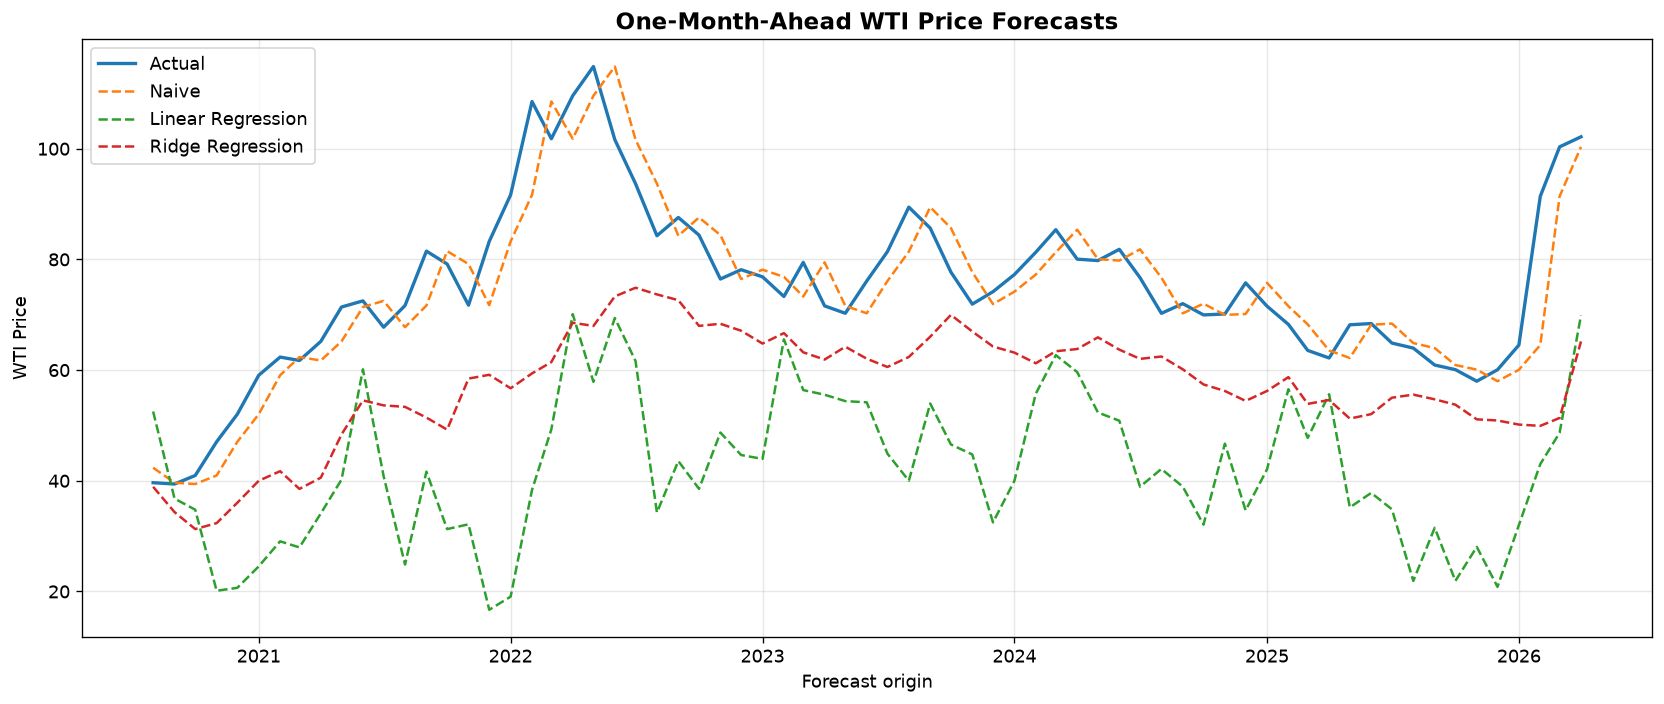

In [66]:
# ============================================================
# CELL 11I: ACTUAL VS PREDICTED WTI PRICE
# ============================================================

plt.figure(
    figsize=(14, 6)
)


plt.plot(
    test_df["date"],
    y_test["price_target_h1"],
    label="Actual",
    linewidth=2
)


plt.plot(
    test_df["date"],
    naive_predictions[:, 2],
    label="Naive",
    linestyle="--"
)


plt.plot(
    test_df["date"],
    linear_predictions[:, 2],
    label="Linear Regression",
    linestyle="--"
)


plt.plot(
    test_df["date"],
    ridge_predictions[:, 2],
    label="Ridge Regression",
    linestyle="--"
)


plt.title(
    "One-Month-Ahead WTI Price Forecasts",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Forecast origin")
plt.ylabel("WTI Price")

plt.legend()
plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [67]:
# ============================================================
# CELL 11J: DIRECTIONAL ACCURACY
# ============================================================

def directional_accuracy(
    current,
    actual_future,
    predicted_future
):

    current = np.asarray(current)
    actual_future = np.asarray(actual_future)
    predicted_future = np.asarray(predicted_future)

    actual_direction = np.sign(
        actual_future - current
    )

    predicted_direction = np.sign(
        predicted_future - current
    )

    return np.mean(
        actual_direction ==
        predicted_direction
    ) * 100

In [68]:
current_price_test = naive_test[
    "price"
].values


price_da = pd.DataFrame({

    "Model": [
        "Naive",
        "Linear Regression",
        "Ridge Regression"
    ],

    "Directional Accuracy (%)": [

        directional_accuracy(
            current_price_test,
            y_test["price_target_h1"],
            naive_predictions[:, 2]
        ),

        directional_accuracy(
            current_price_test,
            y_test["price_target_h1"],
            linear_predictions[:, 2]
        ),

        directional_accuracy(
            current_price_test,
            y_test["price_target_h1"],
            ridge_predictions[:, 2]
        )
    ]
})


display(
    price_da.round(2)
)

,Model,Directional Accuracy (%)
0,Naive,0.00
1,Linear Regression,46.38
2,Ridge Regression,47.83


In [69]:
# ============================================================
# CELL 11K: RMSE IMPROVEMENT OVER NAIVE FORECAST
# ============================================================

comparison_rows = []


for i, target in enumerate(
    target_names
):

    naive_rmse = np.sqrt(
        mean_squared_error(
            y_test.iloc[:, i],
            naive_predictions[:, i]
        )
    )


    linear_rmse = np.sqrt(
        mean_squared_error(
            y_test.iloc[:, i],
            linear_predictions[:, i]
        )
    )


    ridge_rmse = np.sqrt(
        mean_squared_error(
            y_test.iloc[:, i],
            ridge_predictions[:, i]
        )
    )


    comparison_rows.append({

        "Target": target,

        "Naive RMSE":
            naive_rmse,

        "Linear RMSE":
            linear_rmse,

        "Linear improvement (%)":
            100 * (
                1 -
                linear_rmse /
                naive_rmse
            ),

        "Ridge RMSE":
            ridge_rmse,

        "Ridge improvement (%)":
            100 * (
                1 -
                ridge_rmse /
                naive_rmse
            )
    })


improvement_table = pd.DataFrame(
    comparison_rows
)


display(
    improvement_table.round(4)
)

,Target,Naive RMSE,Linear RMSE,Linear improvement (%),Ridge RMSE,Ridge improvement (%)
0,Demand,33726.2882,56334.6769,-67.0349,35946.1274,-6.5819
1,Supply,22013.7615,18575.3379,15.6194,19361.3644,12.0488
2,Price,6.4834,35.8993,-453.7155,20.9453,-223.0634


In [70]:
# ============================================================
# CELL 12A: NONLINEAR ML SETUP
# ============================================================

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.svm import SVR

from sklearn.model_selection import ParameterGrid


ml_results = []
ml_predictions = {}
ml_best_models = {}
ml_best_params = {}

print("Machine-learning environment ready.")

Machine-learning environment ready.


In [71]:
# ============================================================
# CELL 12B: VALIDATION-BASED HYPERPARAMETER TUNING
# ============================================================

def tune_model(
    model_class,
    param_grid,
    X_train,
    y_train,
    X_val,
    y_val,
    fixed_params=None
):
    """
    Tune model using validation RMSE.

    Test data are never used here.
    """

    if fixed_params is None:
        fixed_params = {}

    best_rmse = np.inf
    best_model = None
    best_params = None

    for params in ParameterGrid(param_grid):

        model = model_class(
            **fixed_params,
            **params
        )

        model.fit(
            X_train,
            y_train
        )

        pred = model.predict(
            X_val
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_val,
                pred
            )
        )

        if rmse < best_rmse:

            best_rmse = rmse
            best_model = model
            best_params = params

    return (
        best_model,
        best_params,
        best_rmse
    )


print("Tuning function created.")

Tuning function created.


In [72]:
# ============================================================
# CELL 12C: RANDOM FOREST
# ============================================================

rf_grid = {

    "n_estimators": [
        200,
        500
    ],

    "max_depth": [
        3,
        5,
        8,
        None
    ],

    "min_samples_leaf": [
        2,
        5,
        10
    ],

    "max_features": [
        "sqrt",
        0.7
    ]
}


rf_predictions = np.zeros_like(
    y_test.values,
    dtype=float
)


for i, target in enumerate(target_names):

    print(
        f"\nTuning Random Forest for {target}..."
    )

    best_model, best_params, best_rmse = tune_model(

        RandomForestRegressor,

        rf_grid,

        X_train,
        y_train.iloc[:, i],

        X_val,
        y_val.iloc[:, i],

        fixed_params={
            "random_state": SEED,
            "n_jobs": -1
        }
    )


    ml_best_models[
        f"Random Forest - {target}"
    ] = best_model


    ml_best_params[
        f"Random Forest - {target}"
    ] = best_params


    prediction = best_model.predict(
        X_test
    )


    rf_predictions[:, i] = prediction


    result = evaluate_forecast(
        y_test.iloc[:, i],
        prediction,
        name=f"Random Forest - {target}"
    )


    ml_results.append(result)


    print(
        "Best parameters:",
        best_params
    )

    print(
        f"Validation RMSE: "
        f"{best_rmse:.4f}"
    )


Tuning Random Forest for Demand...
Best parameters: {'max_depth': 8, 'max_features': 0.7, 'min_samples_leaf': 2, 'n_estimators': 500}
Validation RMSE: 35739.0351

Tuning Random Forest for Supply...
Best parameters: {'max_depth': 5, 'max_features': 0.7, 'min_samples_leaf': 2, 'n_estimators': 200}
Validation RMSE: 65409.9639

Tuning Random Forest for Price...
Best parameters: {'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 5, 'n_estimators': 500}
Validation RMSE: 9.5495


In [73]:
# ============================================================
# CELL 12D: RANDOM FOREST PERFORMANCE
# ============================================================

rf_results_df = pd.DataFrame(
    [
        row
        for row in ml_results
        if row["Model"].startswith(
            "Random Forest"
        )
    ]
)


display(
    rf_results_df.round(4)
)

,Model,MAE,RMSE,MAPE (%),R2
0,Random Forest - Demand,32111.3485,35985.4083,5.1962,-0.6422
1,Random Forest - Supply,119354.1255,123273.6346,30.6562,-13.8031
2,Random Forest - Price,11.6534,14.7168,14.8928,0.0847


In [74]:
# ============================================================
# CELL 12E: GRADIENT BOOSTING
# ============================================================

gb_grid = {

    "n_estimators": [
        100,
        200,
        400
    ],

    "learning_rate": [
        0.01,
        0.05,
        0.1
    ],

    "max_depth": [
        2,
        3
    ],

    "min_samples_leaf": [
        3,
        5,
        10
    ],

    "subsample": [
        0.8,
        1.0
    ]
}


gb_predictions = np.zeros_like(
    y_test.values,
    dtype=float
)


for i, target in enumerate(target_names):

    print(
        f"\nTuning Gradient Boosting for {target}..."
    )


    best_model, best_params, best_rmse = tune_model(

        GradientBoostingRegressor,

        gb_grid,

        X_train,
        y_train.iloc[:, i],

        X_val,
        y_val.iloc[:, i],

        fixed_params={
            "random_state": SEED
        }
    )


    ml_best_models[
        f"Gradient Boosting - {target}"
    ] = best_model


    ml_best_params[
        f"Gradient Boosting - {target}"
    ] = best_params


    prediction = best_model.predict(
        X_test
    )


    gb_predictions[:, i] = prediction


    result = evaluate_forecast(
        y_test.iloc[:, i],
        prediction,
        name=f"Gradient Boosting - {target}"
    )


    ml_results.append(result)


    print(
        "Best parameters:",
        best_params
    )

    print(
        f"Validation RMSE: "
        f"{best_rmse:.4f}"
    )


Tuning Gradient Boosting for Demand...
Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 3, 'n_estimators': 100, 'subsample': 1.0}
Validation RMSE: 29295.4236

Tuning Gradient Boosting for Supply...
Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 400, 'subsample': 0.8}
Validation RMSE: 64343.3455

Tuning Gradient Boosting for Price...
Best parameters: {'learning_rate': 0.01, 'max_depth': 3, 'min_samples_leaf': 3, 'n_estimators': 200, 'subsample': 0.8}
Validation RMSE: 9.5448


In [75]:
# ============================================================
# CELL 12F: GRADIENT BOOSTING PERFORMANCE
# ============================================================

gb_results_df = pd.DataFrame(
    [
        row
        for row in ml_results
        if row["Model"].startswith(
            "Gradient Boosting"
        )
    ]
)


display(
    gb_results_df.round(4)
)

,Model,MAE,RMSE,MAPE (%),R2
0,Gradient Boosting - Demand,22497.0576,28844.0135,3.6478,-0.0551
1,Gradient Boosting - Supply,117737.5348,121418.9595,30.2630,-13.3610
2,Gradient Boosting - Price,17.3337,20.0850,21.7646,-0.7048


In [76]:
# ============================================================
# CELL 12G: SUPPORT VECTOR REGRESSION
# ============================================================

svr_grid = {

    "kernel": [
        "rbf"
    ],

    "C": [
        0.1,
        1,
        10,
        100
    ],

    "gamma": [
        "scale",
        0.001,
        0.01,
        0.1
    ],

    "epsilon": [
        0.01,
        0.05,
        0.1
    ]
}


svr_predictions = np.zeros_like(
    y_test.values,
    dtype=float
)


for i, target in enumerate(target_names):

    print(
        f"\nTuning SVR for {target}..."
    )


    best_model, best_params, best_rmse = tune_model(

        SVR,

        svr_grid,

        X_train_scaled,
        y_train.iloc[:, i],

        X_val_scaled,
        y_val.iloc[:, i]
    )


    ml_best_models[
        f"SVR - {target}"
    ] = best_model


    ml_best_params[
        f"SVR - {target}"
    ] = best_params


    prediction = best_model.predict(
        X_test_scaled
    )


    svr_predictions[:, i] = prediction


    result = evaluate_forecast(
        y_test.iloc[:, i],
        prediction,
        name=f"SVR - {target}"
    )


    ml_results.append(result)


    print(
        "Best parameters:",
        best_params
    )

    print(
        f"Validation RMSE: "
        f"{best_rmse:.4f}"
    )


Tuning SVR for Demand...
Best parameters: {'C': 100, 'epsilon': 0.01, 'gamma': 0.1, 'kernel': 'rbf'}
Validation RMSE: 45157.0151

Tuning SVR for Supply...
Best parameters: {'C': 100, 'epsilon': 0.01, 'gamma': 0.001, 'kernel': 'rbf'}
Validation RMSE: 133039.4040

Tuning SVR for Price...
Best parameters: {'C': 100, 'epsilon': 0.1, 'gamma': 0.001, 'kernel': 'rbf'}
Validation RMSE: 10.6393


In [77]:
# ============================================================
# CELL 12H: SVR PERFORMANCE
# ============================================================

svr_results_df = pd.DataFrame(
    [
        row
        for row in ml_results
        if row["Model"].startswith(
            "SVR"
        )
    ]
)


display(
    svr_results_df.round(4)
)

,Model,MAE,RMSE,MAPE (%),R2
0,SVR - Demand,42821.1210,47562.1219,6.8876,-1.8687
1,SVR - Supply,194377.1606,196977.1584,50.3545,-36.7957
2,SVR - Price,21.9998,24.6837,27.8581,-1.5748


In [78]:
# ============================================================
# CELL 12I: FULL MODEL COMPARISON SO FAR
# ============================================================

ml_results_df = pd.DataFrame(
    ml_results
)


all_results_so_far = pd.concat(
    [
        benchmark_results,
        ml_results_df
    ],
    ignore_index=True
)


display(
    all_results_so_far
    .sort_values(
        ["RMSE"]
    )
    .round(4)
)

,Model,MAE,RMSE,MAPE (%),R2
2,Naive - Price,4.9606,6.4834,6.3744,0.8224
11,Random Forest - Price,11.6534,14.7168,14.8928,0.0847
14,Gradient Boosting - Price,17.3337,20.0850,21.7646,-0.7048
8,Ridge - Price,17.8325,20.9453,22.7009,-0.8539
17,SVR - Price,21.9998,24.6837,27.8581,-1.5748
5,Linear Regression - Price,33.0817,35.8993,43.6175,-4.4461
4,Linear Regression - Supply,13827.4307,18575.3379,3.7300,0.6639
7,Ridge - Supply,17367.8826,19361.3644,4.5676,0.6348
1,Naive - Supply,16594.0580,22013.7615,4.4407,0.5279
12,Gradient Boosting - Demand,22497.0576,28844.0135,3.6478,-0.0551


In [79]:
for target in target_names:

    print("\n" + "=" * 80)
    print(
        f"{target.upper()} MODEL RANKING"
    )
    print("=" * 80)

    temp = (
        all_results_so_far[
            all_results_so_far[
                "Model"
            ].str.endswith(
                target
            )
        ]
        .sort_values("RMSE")
        .reset_index(drop=True)
    )

    temp.index = (
        temp.index + 1
    )

    display(
        temp.round(4)
    )


DEMAND MODEL RANKING


,Model,MAE,RMSE,MAPE (%),R2
1,Gradient Boosting - Demand,22497.0576,28844.0135,3.6478,-0.0551
2,Naive - Demand,26573.2464,33726.2882,4.3933,-0.4425
3,Ridge - Demand,29777.1574,35946.1274,4.8337,-0.6386
4,Random Forest - Demand,32111.3485,35985.4083,5.1962,-0.6422
5,SVR - Demand,42821.1210,47562.1219,6.8876,-1.8687
6,Linear Regression - Demand,46566.3703,56334.6769,7.6457,-3.0246



SUPPLY MODEL RANKING


,Model,MAE,RMSE,MAPE (%),R2
1,Linear Regression - Supply,13827.4307,18575.3379,3.7300,0.6639
2,Ridge - Supply,17367.8826,19361.3644,4.5676,0.6348
3,Naive - Supply,16594.0580,22013.7615,4.4407,0.5279
4,Gradient Boosting - Supply,117737.5348,121418.9595,30.2630,-13.3610
5,Random Forest - Supply,119354.1255,123273.6346,30.6562,-13.8031
6,SVR - Supply,194377.1606,196977.1584,50.3545,-36.7957



PRICE MODEL RANKING


,Model,MAE,RMSE,MAPE (%),R2
1,Naive - Price,4.9606,6.4834,6.3744,0.8224
2,Random Forest - Price,11.6534,14.7168,14.8928,0.0847
3,Gradient Boosting - Price,17.3337,20.0850,21.7646,-0.7048
4,Ridge - Price,17.8325,20.9453,22.7009,-0.8539
5,SVR - Price,21.9998,24.6837,27.8581,-1.5748
6,Linear Regression - Price,33.0817,35.8993,43.6175,-4.4461


In [80]:
# ============================================================
# CELL 12J: IMPROVEMENT OVER PERSISTENCE
# ============================================================

improvement_rows = []


for target in target_names:

    naive_row = all_results_so_far[
        all_results_so_far[
            "Model"
        ] == f"Naive - {target}"
    ]

    naive_rmse = naive_row[
        "RMSE"
    ].iloc[0]


    target_models = all_results_so_far[
        all_results_so_far[
            "Model"
        ].str.endswith(
            target
        )
    ]


    for _, row in target_models.iterrows():

        improvement = (
            100 *
            (
                1 -
                row["RMSE"] /
                naive_rmse
            )
        )


        improvement_rows.append({

            "Target": target,

            "Model": row["Model"],

            "RMSE": row["RMSE"],

            "Improvement over Naive (%)":
                improvement
        })


improvement_all = pd.DataFrame(
    improvement_rows
)


display(
    improvement_all
    .sort_values(
        [
            "Target",
            "RMSE"
        ]
    )
    .round(4)
)

,Target,Model,RMSE,Improvement over Naive (%)
4,Demand,Gradient Boosting - Demand,28844.0135,14.4762
0,Demand,Naive - Demand,33726.2882,0.0000
2,Demand,Ridge - Demand,35946.1274,-6.5819
3,Demand,Random Forest - Demand,35985.4083,-6.6984
5,Demand,SVR - Demand,47562.1219,-41.0239
1,Demand,Linear Regression - Demand,56334.6769,-67.0349
12,Price,Naive - Price,6.4834,0.0000
15,Price,Random Forest - Price,14.7168,-126.9932
16,Price,Gradient Boosting - Price,20.0850,-209.7938
14,Price,Ridge - Price,20.9453,-223.0634


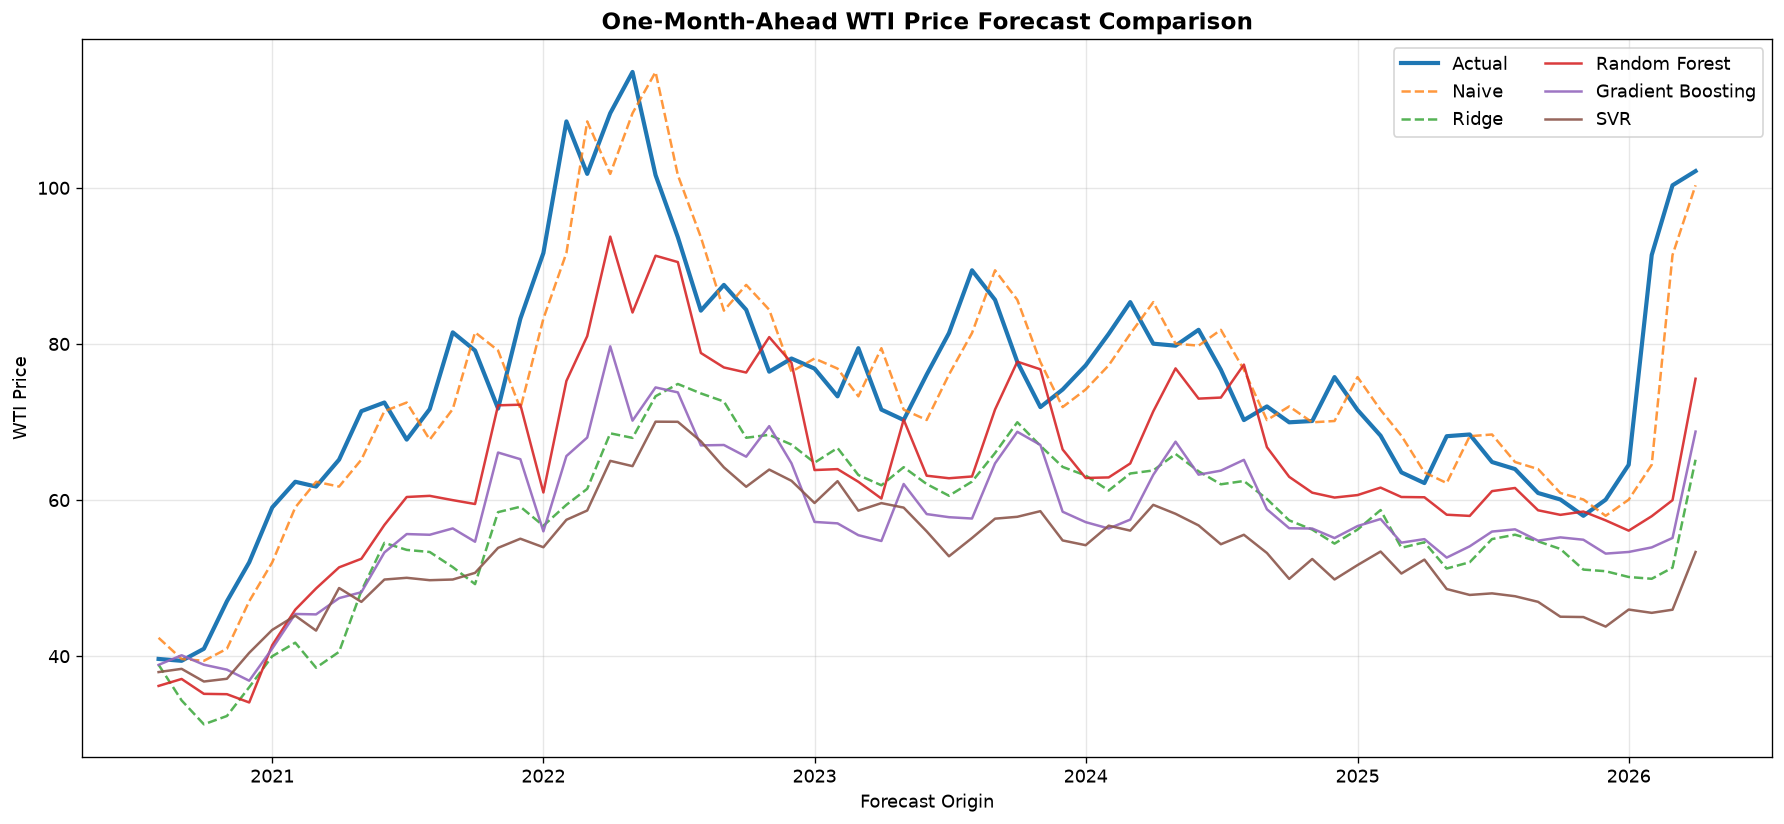

In [81]:
# ============================================================
# CELL 12K: WTI PRICE FORECAST COMPARISON
# ============================================================

plt.figure(
    figsize=(15, 7)
)


plt.plot(
    test_df["date"],
    y_test["price_target_h1"],
    label="Actual",
    linewidth=2.5
)


plt.plot(
    test_df["date"],
    naive_predictions[:, 2],
    label="Naive",
    linestyle="--",
    alpha=0.8
)


plt.plot(
    test_df["date"],
    ridge_predictions[:, 2],
    label="Ridge",
    linestyle="--",
    alpha=0.8
)


plt.plot(
    test_df["date"],
    rf_predictions[:, 2],
    label="Random Forest",
    alpha=0.9
)


plt.plot(
    test_df["date"],
    gb_predictions[:, 2],
    label="Gradient Boosting",
    alpha=0.9
)


plt.plot(
    test_df["date"],
    svr_predictions[:, 2],
    label="SVR",
    alpha=0.9
)


plt.title(
    "One-Month-Ahead WTI Price Forecast Comparison",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Forecast Origin"
)

plt.ylabel(
    "WTI Price"
)

plt.legend(
    ncol=2
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [82]:
# ============================================================
# CELL 12L: PRICE DIRECTIONAL ACCURACY
# ============================================================

price_direction_results = []


price_models = {

    "Linear Regression":
        linear_predictions[:, 2],

    "Ridge Regression":
        ridge_predictions[:, 2],

    "Random Forest":
        rf_predictions[:, 2],

    "Gradient Boosting":
        gb_predictions[:, 2],

    "SVR":
        svr_predictions[:, 2]
}


for model_name, prediction in price_models.items():

    da = directional_accuracy(

        current_price_test,

        y_test[
            "price_target_h1"
        ].values,

        prediction
    )


    price_direction_results.append({

        "Model":
            model_name,

        "Directional Accuracy (%)":
            da
    })


price_direction_df = pd.DataFrame(
    price_direction_results
)


display(
    price_direction_df
    .sort_values(
        "Directional Accuracy (%)",
        ascending=False
    )
    .round(2)
)

,Model,Directional Accuracy (%)
2,Random Forest,49.28
4,SVR,47.83
1,Ridge Regression,47.83
0,Linear Regression,46.38
3,Gradient Boosting,46.38


In [83]:
# ============================================================
# CELL 12M: RANDOM FOREST FEATURE IMPORTANCE — PRICE
# ============================================================

rf_price_model = ml_best_models[
    "Random Forest - Price"
]


rf_importance = pd.DataFrame({

    "Feature":
        feature_columns,

    "Importance":
        rf_price_model.feature_importances_
})


rf_importance = (
    rf_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    rf_importance.head(20).round(6)
)

,Feature,Importance
0,price_lag1,0.376557
1,price_imbalance,0.258056
2,price_rollmean12,0.101850
3,price_lag12,0.076533
4,price_rollmean6,0.043407
5,price_rollmean3,0.042588
6,price_lag2,0.033408
7,price_lag6,0.013833
8,price_lag3,0.007168
9,demand_rollstd12,0.004490


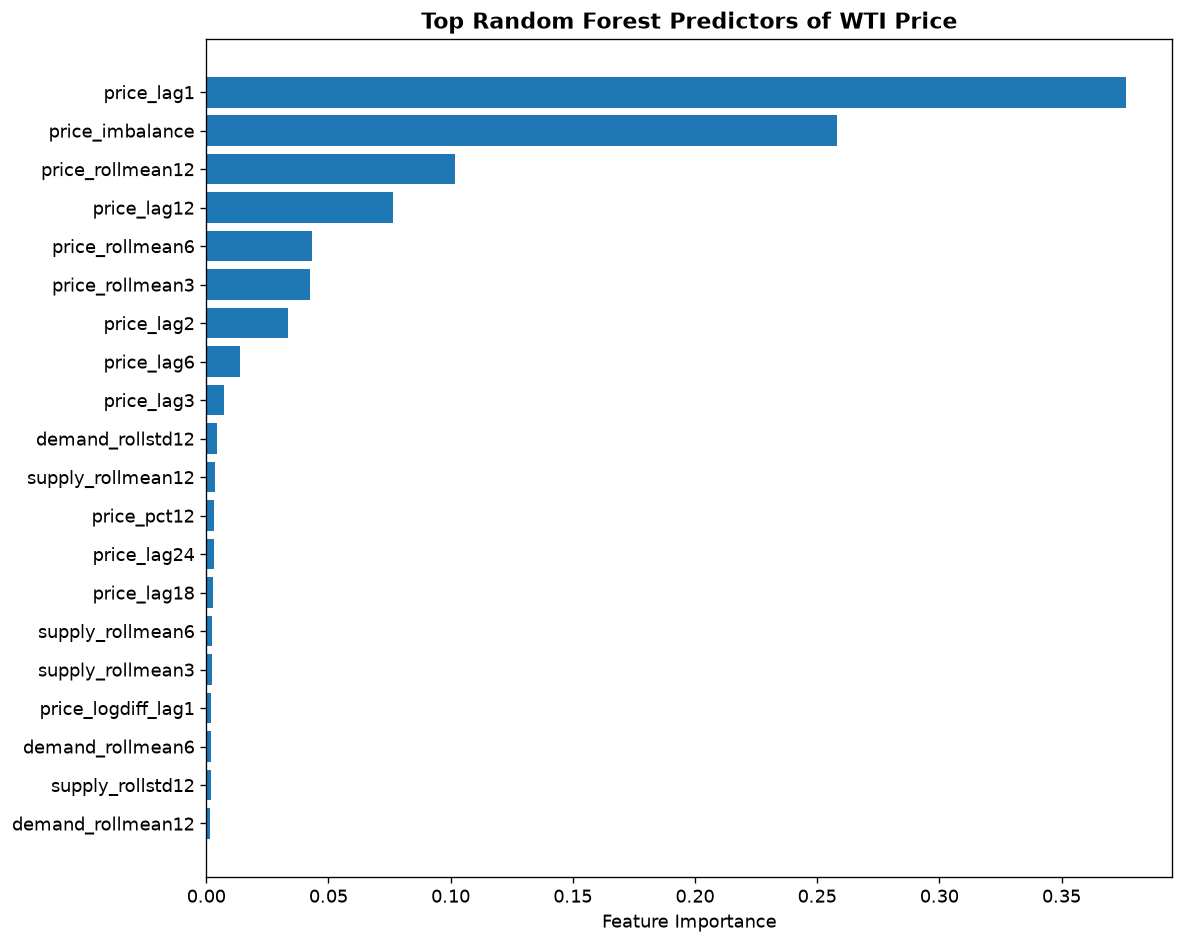

In [84]:
top_n = 20

temp = (
    rf_importance
    .head(top_n)
    .sort_values(
        "Importance"
    )
)


plt.figure(
    figsize=(10, 8)
)

plt.barh(
    temp["Feature"],
    temp["Importance"]
)

plt.title(
    "Top Random Forest Predictors of WTI Price",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel(
    "Feature Importance"
)

plt.tight_layout()
plt.show()

In [85]:
# ============================================================
# CELL 12N: GRADIENT BOOSTING FEATURE IMPORTANCE — PRICE
# ============================================================

gb_price_model = ml_best_models[
    "Gradient Boosting - Price"
]


gb_importance = pd.DataFrame({

    "Feature":
        feature_columns,

    "Importance":
        gb_price_model.feature_importances_
})


gb_importance = (
    gb_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    gb_importance.head(20).round(6)
)

,Feature,Importance
0,price_lag1,0.406646
1,price_imbalance,0.338727
2,price_lag12,0.088300
3,price_rollmean12,0.087668
4,price_rollmean6,0.017985
5,price_pct12,0.006209
6,price_rollmean3,0.006128
7,demand_rollstd12,0.005396
8,supply_rollmean3,0.004350
9,price_lag24,0.004267


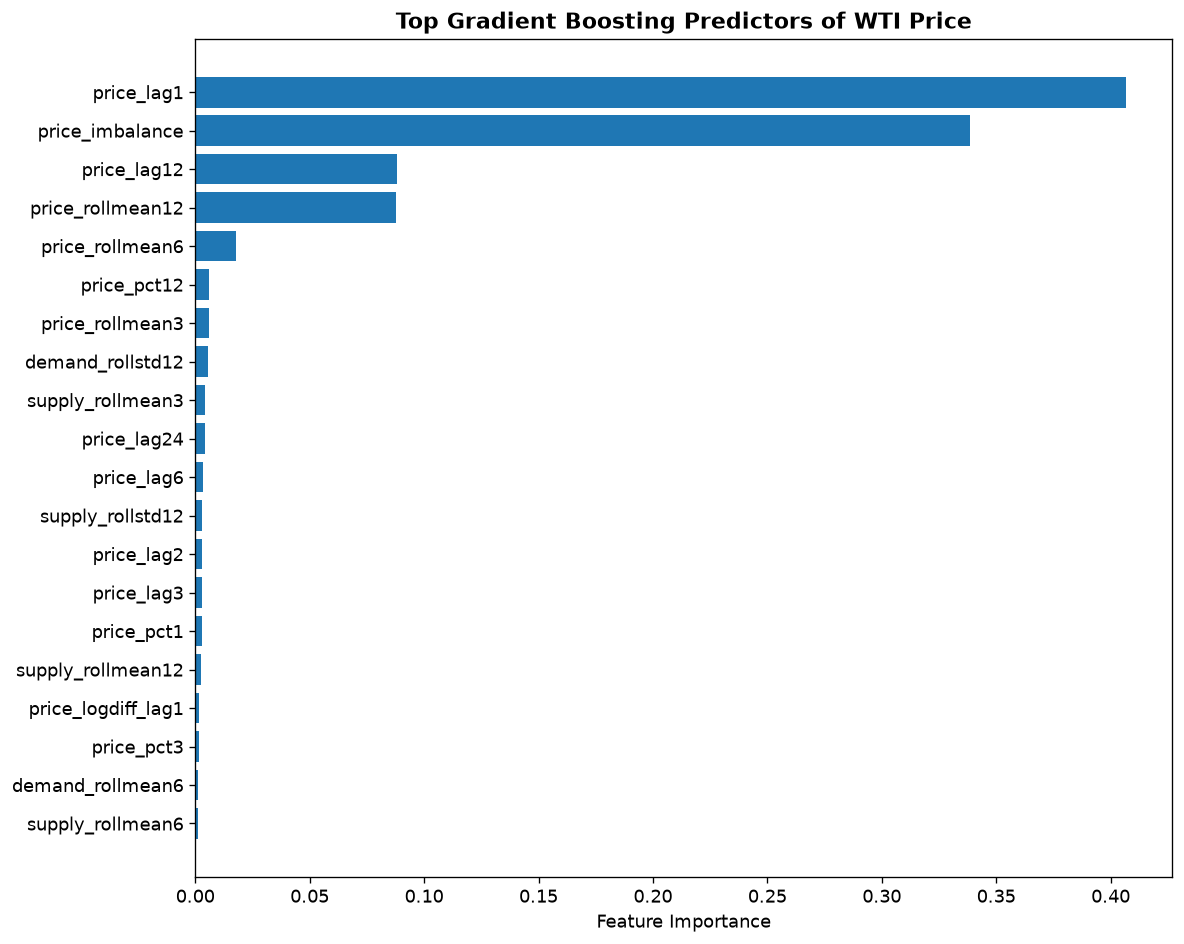

In [86]:
temp = (
    gb_importance
    .head(20)
    .sort_values(
        "Importance"
    )
)


plt.figure(
    figsize=(10, 8)
)

plt.barh(
    temp["Feature"],
    temp["Importance"]
)

plt.title(
    "Top Gradient Boosting Predictors of WTI Price",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel(
    "Feature Importance"
)

plt.tight_layout()
plt.show()

In [87]:
# ============================================================
# CELL 13A: DEEP LEARNING SETUP
# ============================================================

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    LSTM,
    GRU,
    Input
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from tensorflow.keras.optimizers import Adam


# Reproducibility
tf.random.set_seed(SEED)
np.random.seed(SEED)


print("TensorFlow version:", tf.__version__)

print(
    "GPU available:",
    len(tf.config.list_physical_devices("GPU")) > 0
)

TensorFlow version: 2.22.0-rc0
GPU available: False


In [88]:
# ============================================================
# CELL 13B: MLP MODEL
# ============================================================

def build_mlp(input_dim, output_dim=3):

    model = Sequential([

        Input(shape=(input_dim,)),

        Dense(
            64,
            activation="relu"
        ),

        Dropout(0.20),

        Dense(
            32,
            activation="relu"
        ),

        Dropout(0.15),

        Dense(
            16,
            activation="relu"
        ),

        Dense(
            output_dim,
            activation="linear"
        )
    ])


    model.compile(

        optimizer=Adam(
            learning_rate=0.001
        ),

        loss="mse",

        metrics=["mae"]
    )

    return model


mlp_model = build_mlp(
    input_dim=X_train_scaled.shape[1]
)


mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           5,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,715 (30.14 KB)

 Trainable params: 7,715 (30.14 KB)

 Non-trainable params: 0 (0.00 B)

In [89]:
# ============================================================
# CELL 13C: TRAINING CALLBACKS
# ============================================================

early_stop = EarlyStopping(

    monitor="val_loss",

    patience=30,

    restore_best_weights=True,

    verbose=1
)


reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=10,

    min_lr=1e-6,

    verbose=1
)

In [90]:
# ============================================================
# CELL 13D: TRAIN MLP
# ============================================================

history_mlp = mlp_model.fit(

    X_train_scaled,
    y_train_scaled,

    validation_data=(
        X_val_scaled,
        y_val_scaled
    ),

    epochs=500,

    batch_size=16,

    callbacks=[
        early_stop,
        reduce_lr
    ],

    verbose=0
)


print(
    "MLP training completed."
)

print(
    "Epochs trained:",
    len(history_mlp.history["loss"])
)


Epoch 15: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 25: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 35: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Epoch 35: early stopping
Restoring model weights from the end of the best epoch: 5.
MLP training completed.
Epochs trained: 35


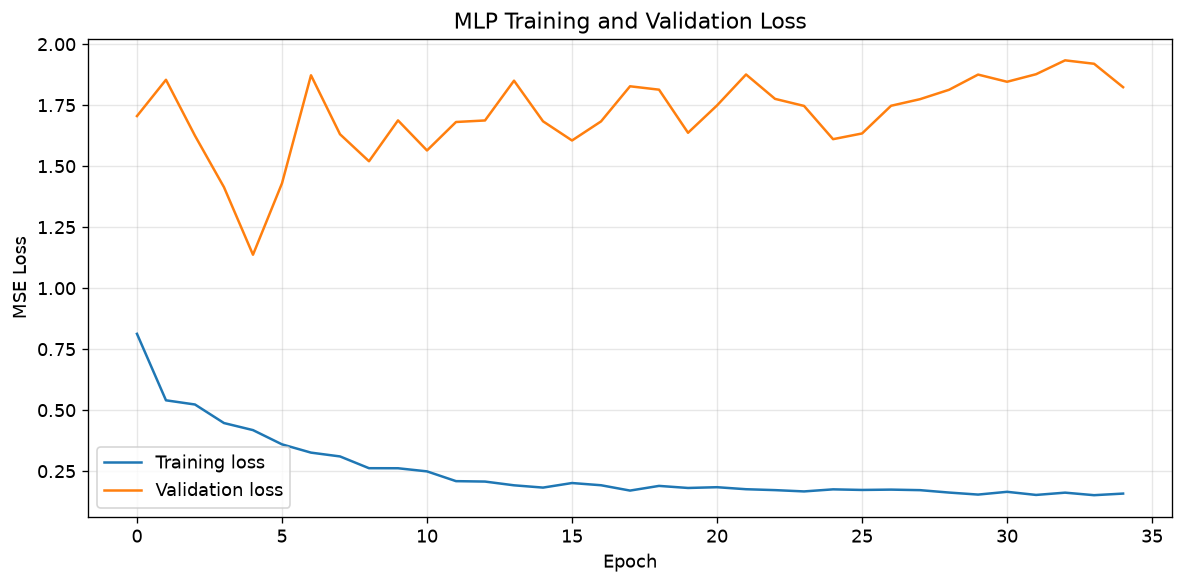

In [91]:
# ============================================================
# CELL 13E: MLP LEARNING CURVE
# ============================================================

plt.figure(
    figsize=(10, 5)
)


plt.plot(
    history_mlp.history["loss"],
    label="Training loss"
)


plt.plot(
    history_mlp.history["val_loss"],
    label="Validation loss"
)


plt.title(
    "MLP Training and Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [92]:
# ============================================================
# CELL 13F: MLP TEST PREDICTIONS
# ============================================================

mlp_pred_scaled = mlp_model.predict(
    X_test_scaled,
    verbose=0
)


mlp_predictions = y_scaler.inverse_transform(
    mlp_pred_scaled
)


print(
    "MLP predictions shape:",
    mlp_predictions.shape
)

MLP predictions shape: (69, 3)


In [93]:
# ============================================================
# CELL 13G: MLP PERFORMANCE
# ============================================================

mlp_results = []


for i, target in enumerate(target_names):

    result = evaluate_forecast(

        y_test.iloc[:, i],

        mlp_predictions[:, i],

        name=f"MLP - {target}"
    )

    mlp_results.append(result)


mlp_results_df = pd.DataFrame(
    mlp_results
)


display(
    mlp_results_df.round(4)
)

,Model,MAE,RMSE,MAPE (%),R2
0,MLP - Demand,49548.3542,55119.1001,7.9825,-2.8527
1,MLP - Supply,43522.6313,46573.0608,11.3199,-1.1129
2,MLP - Price,24.5064,31.8788,31.4554,-3.2946


In [94]:
# ============================================================
# CELL 13H: PREPARE SEQUENTIAL DATA
# ============================================================

SEQUENCE_LENGTH = 12


sequence_variables = [
    "demand",
    "supply",
    "price"
]


sequence_df = df[
    [
        "date",
        "demand",
        "supply",
        "price"
    ]
].copy()


print(
    "Sequence length:",
    SEQUENCE_LENGTH
)

print(
    "Sequence variables:",
    sequence_variables
)

Sequence length: 12
Sequence variables: ['demand', 'supply', 'price']


In [95]:
# ============================================================
# CELL 13I: TEMPORAL BOUNDARIES
# ============================================================

train_end_date = train_df[
    "date"
].max()

val_end_date = val_df[
    "date"
].max()


print(
    "Training ends:",
    train_end_date.date()
)

print(
    "Validation ends:",
    val_end_date.date()
)

print(
    "Test begins after:",
    val_end_date.date()
)

Training ends: 2014-10-01
Validation ends: 2020-07-01
Test begins after: 2020-07-01


In [96]:
# ============================================================
# CELL 13J: SEQUENCE SCALING
# ============================================================

from sklearn.preprocessing import StandardScaler


sequence_scaler = StandardScaler()


training_mask = (
    sequence_df["date"] <=
    train_end_date
)


sequence_scaler.fit(
    sequence_df.loc[
        training_mask,
        sequence_variables
    ]
)


sequence_scaled = sequence_scaler.transform(
    sequence_df[
        sequence_variables
    ]
)


print(
    "Sequence scaler fitted "
    "using training period only."
)

Sequence scaler fitted using training period only.


In [97]:
# ============================================================
# CELL 13K: CREATE LSTM/GRU SEQUENCES
# ============================================================

def create_sequences(
    data_scaled,
    dates,
    sequence_length=12,
    horizon=1
):

    X = []
    y = []
    target_dates = []
    origin_dates = []

    for i in range(
        sequence_length - 1,
        len(data_scaled) - horizon
    ):

        start = (
            i - sequence_length + 1
        )

        end = i + 1

        target_index = (
            i + horizon
        )


        X.append(
            data_scaled[
                start:end
            ]
        )

        y.append(
            data_scaled[
                target_index
            ]
        )

        origin_dates.append(
            dates.iloc[i]
        )

        target_dates.append(
            dates.iloc[
                target_index
            ]
        )


    return (
        np.array(X),
        np.array(y),
        np.array(origin_dates),
        np.array(target_dates)
    )

In [98]:
X_seq, y_seq, origin_dates_seq, target_dates_seq = (
    create_sequences(

        sequence_scaled,

        sequence_df["date"],

        sequence_length=
            SEQUENCE_LENGTH,

        horizon=1
    )
)


print(
    "X sequence shape:",
    X_seq.shape
)

print(
    "y sequence shape:",
    y_seq.shape
)

X sequence shape: (473, 12, 3)
y sequence shape: (473, 3)


In [99]:
# ============================================================
# CELL 13L: CHRONOLOGICAL SEQUENCE SPLIT
# ============================================================

seq_train_mask = (
    origin_dates_seq <=
    np.datetime64(train_end_date)
)


seq_val_mask = (
    (origin_dates_seq >
     np.datetime64(train_end_date))
    &
    (origin_dates_seq <=
     np.datetime64(val_end_date))
)


seq_test_mask = (
    origin_dates_seq >
    np.datetime64(val_end_date)
)


X_train_seq = X_seq[
    seq_train_mask
]

y_train_seq = y_seq[
    seq_train_mask
]


X_val_seq = X_seq[
    seq_val_mask
]

y_val_seq = y_seq[
    seq_val_mask
]


X_test_seq = X_seq[
    seq_test_mask
]

y_test_seq = y_seq[
    seq_test_mask
]


test_origin_dates_seq = (
    origin_dates_seq[
        seq_test_mask
    ]
)


test_target_dates_seq = (
    target_dates_seq[
        seq_test_mask
    ]
)


print(
    "Training:",
    X_train_seq.shape
)

print(
    "Validation:",
    X_val_seq.shape
)

print(
    "Test:",
    X_test_seq.shape
)

Training: (335, 12, 3)
Validation: (69, 12, 3)
Test: (69, 12, 3)


In [100]:
# ============================================================
# CELL 13M: LSTM MODEL
# ============================================================

def build_lstm(
    sequence_length,
    n_features,
    output_dim=3
):

    model = Sequential([

        Input(
            shape=(
                sequence_length,
                n_features
            )
        ),

        LSTM(
            32,
            return_sequences=False
        ),

        Dropout(0.20),

        Dense(
            16,
            activation="relu"
        ),

        Dropout(0.10),

        Dense(
            output_dim,
            activation="linear"
        )
    ])


    model.compile(

        optimizer=Adam(
            learning_rate=0.001
        ),

        loss="mse",

        metrics=["mae"]
    )

    return model


lstm_model = build_lstm(
    SEQUENCE_LENGTH,
    len(sequence_variables)
)


lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 32)                  │           4,608 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 3)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,187 (20.26 KB)

 Trainable params: 5,187 (20.26 KB)

 Non-trainable params: 0 (0.00 B)

In [101]:
# ============================================================
# CELL 13N: TRAIN LSTM
# ============================================================

lstm_early_stop = EarlyStopping(

    monitor="val_loss",

    patience=30,

    restore_best_weights=True,

    verbose=1
)


lstm_reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=10,

    min_lr=1e-6,

    verbose=1
)


history_lstm = lstm_model.fit(

    X_train_seq,
    y_train_seq,

    validation_data=(
        X_val_seq,
        y_val_seq
    ),

    epochs=500,

    batch_size=16,

    shuffle=False,

    callbacks=[
        lstm_early_stop,
        lstm_reduce_lr
    ],

    verbose=0
)


print(
    "LSTM epochs trained:",
    len(history_lstm.history["loss"])
)


Epoch 63: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 101: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 156: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 166: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 176: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.
Epoch 176: early stopping
Restoring model weights from the end of the best epoch: 146.
LSTM epochs trained: 176


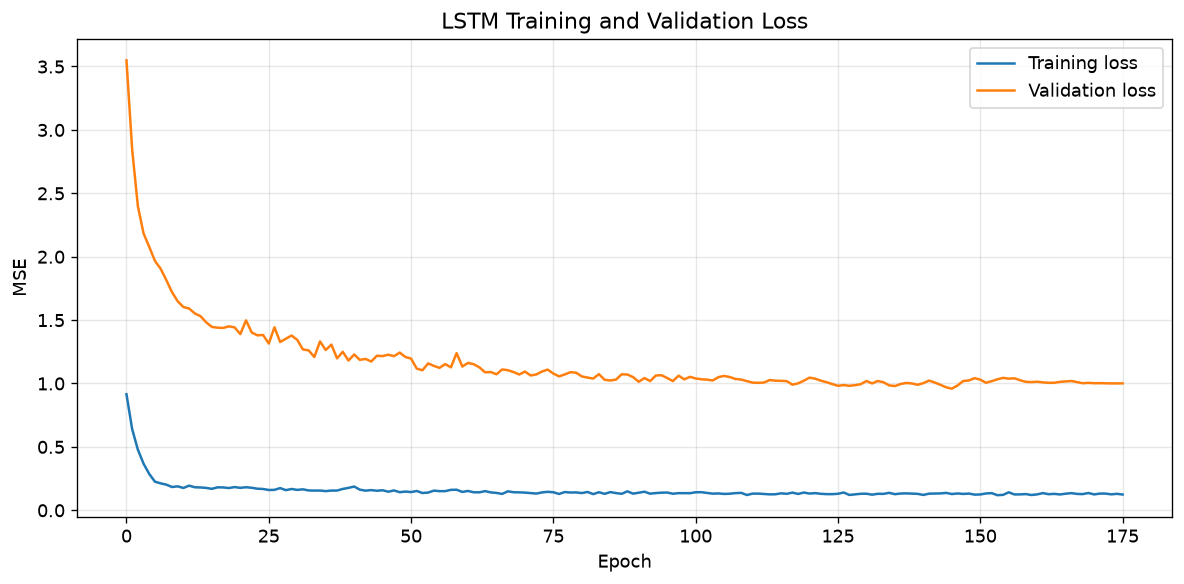

In [102]:
# ============================================================
# CELL 13O: LSTM LEARNING CURVE
# ============================================================

plt.figure(
    figsize=(10, 5)
)


plt.plot(
    history_lstm.history["loss"],
    label="Training loss"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="Validation loss"
)


plt.title(
    "LSTM Training and Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [103]:
# ============================================================
# CELL 13P: LSTM TEST PREDICTIONS
# ============================================================

lstm_pred_scaled = lstm_model.predict(
    X_test_seq,
    verbose=0
)


lstm_predictions = (
    sequence_scaler.inverse_transform(
        lstm_pred_scaled
    )
)


lstm_actual = (
    sequence_scaler.inverse_transform(
        y_test_seq
    )
)


print(
    lstm_predictions.shape
)

(69, 3)


In [104]:
# ============================================================
# CELL 13Q: LSTM PERFORMANCE
# ============================================================

lstm_results = []


for i, target in enumerate(
    target_names
):

    result = evaluate_forecast(

        lstm_actual[:, i],

        lstm_predictions[:, i],

        name=f"LSTM - {target}"
    )

    lstm_results.append(result)


lstm_results_df = pd.DataFrame(
    lstm_results
)


display(
    lstm_results_df.round(4)
)

,Model,MAE,RMSE,MAPE (%),R2
0,LSTM - Demand,37880.9529,42141.3215,6.0963,-1.2521
1,LSTM - Supply,79609.4669,84704.3576,20.2751,-5.9891
2,LSTM - Price,8.9866,11.4891,12.1733,0.4422


In [105]:
# ============================================================
# CELL 13R: GRU MODEL
# ============================================================

def build_gru(
    sequence_length,
    n_features,
    output_dim=3
):

    model = Sequential([

        Input(
            shape=(
                sequence_length,
                n_features
            )
        ),

        GRU(
            32,
            return_sequences=False
        ),

        Dropout(0.20),

        Dense(
            16,
            activation="relu"
        ),

        Dropout(0.10),

        Dense(
            output_dim,
            activation="linear"
        )
    ])


    model.compile(

        optimizer=Adam(
            learning_rate=0.001
        ),

        loss="mse",

        metrics=["mae"]
    )

    return model


gru_model = build_gru(
    SEQUENCE_LENGTH,
    len(sequence_variables)
)


gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru (GRU)                            │ (None, 32)                  │           3,552 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 3)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,131 (16.14 KB)

 Trainable params: 4,131 (16.14 KB)

 Non-trainable params: 0 (0.00 B)

In [106]:
# ============================================================
# CELL 13S: TRAIN GRU
# ============================================================

gru_early_stop = EarlyStopping(

    monitor="val_loss",

    patience=30,

    restore_best_weights=True,

    verbose=1
)


gru_reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=10,

    min_lr=1e-6,

    verbose=1
)


history_gru = gru_model.fit(

    X_train_seq,
    y_train_seq,

    validation_data=(
        X_val_seq,
        y_val_seq
    ),

    epochs=500,

    batch_size=16,

    shuffle=False,

    callbacks=[
        gru_early_stop,
        gru_reduce_lr
    ],

    verbose=0
)


print(
    "GRU epochs trained:",
    len(history_gru.history["loss"])
)


Epoch 50: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 60: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 70: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Epoch 70: early stopping
Restoring model weights from the end of the best epoch: 40.
GRU epochs trained: 70


In [107]:
# ============================================================
# CELL 13T: GRU PERFORMANCE
# ============================================================

gru_pred_scaled = gru_model.predict(
    X_test_seq,
    verbose=0
)


gru_predictions = (
    sequence_scaler.inverse_transform(
        gru_pred_scaled
    )
)


gru_results = []


for i, target in enumerate(
    target_names
):

    result = evaluate_forecast(

        lstm_actual[:, i],

        gru_predictions[:, i],

        name=f"GRU - {target}"
    )

    gru_results.append(result)


gru_results_df = pd.DataFrame(
    gru_results
)


display(
    gru_results_df.round(4)
)

,Model,MAE,RMSE,MAPE (%),R2
0,GRU - Demand,40473.2065,44513.7769,6.5149,-1.5128
1,GRU - Supply,94330.8179,99529.6487,24.0704,-8.6497
2,GRU - Price,9.7642,11.3442,14.3062,0.4562


In [108]:
# ============================================================
# CELL 13U: DEEP LEARNING RESULTS
# ============================================================

deep_results = pd.concat(
    [
        mlp_results_df,
        lstm_results_df,
        gru_results_df
    ],
    ignore_index=True
)


display(
    deep_results
    .sort_values("RMSE")
    .round(4)
)

,Model,MAE,RMSE,MAPE (%),R2
8,GRU - Price,9.7642,11.3442,14.3062,0.4562
5,LSTM - Price,8.9866,11.4891,12.1733,0.4422
2,MLP - Price,24.5064,31.8788,31.4554,-3.2946
3,LSTM - Demand,37880.9529,42141.3215,6.0963,-1.2521
6,GRU - Demand,40473.2065,44513.7769,6.5149,-1.5128
1,MLP - Supply,43522.6313,46573.0608,11.3199,-1.1129
0,MLP - Demand,49548.3542,55119.1001,7.9825,-2.8527
4,LSTM - Supply,79609.4669,84704.3576,20.2751,-5.9891
7,GRU - Supply,94330.8179,99529.6487,24.0704,-8.6497


In [109]:
# ============================================================
# CELL 13V: VERIFY TEST-PERIOD ALIGNMENT
# ============================================================

print(
    "Tabular test observations:",
    len(test_df)
)

print(
    "Sequence test observations:",
    len(test_origin_dates_seq)
)


print("\nTabular test range:")

print(
    test_df["date"].min(),
    "→",
    test_df["date"].max()
)


print("\nSequence test range:")

print(
    pd.Timestamp(
        test_origin_dates_seq.min()
    ),
    "→",
    pd.Timestamp(
        test_origin_dates_seq.max()
    )
)

Tabular test observations: 69
Sequence test observations: 69

Tabular test range:
2020-08-01 00:00:00 → 2026-04-01 00:00:00

Sequence test range:
2020-08-01 00:00:00 → 2026-04-01 00:00:00


In [110]:
# ============================================================
# CELL 13W: MASTER MODEL RESULTS
# ============================================================

master_results = pd.concat(
    [
        all_results_so_far,
        deep_results
    ],
    ignore_index=True
)


for target in target_names:

    print("\n" + "=" * 80)

    print(
        f"{target.upper()} — ALL MODELS"
    )

    print("=" * 80)


    ranking = (
        master_results[
            master_results[
                "Model"
            ].str.endswith(
                target
            )
        ]
        .sort_values("RMSE")
        .reset_index(drop=True)
    )


    ranking.index = (
        ranking.index + 1
    )


    display(
        ranking.round(4)
    )


DEMAND — ALL MODELS


,Model,MAE,RMSE,MAPE (%),R2
1,Gradient Boosting - Demand,22497.0576,28844.0135,3.6478,-0.0551
2,Naive - Demand,26573.2464,33726.2882,4.3933,-0.4425
3,Ridge - Demand,29777.1574,35946.1274,4.8337,-0.6386
4,Random Forest - Demand,32111.3485,35985.4083,5.1962,-0.6422
5,LSTM - Demand,37880.9529,42141.3215,6.0963,-1.2521
6,GRU - Demand,40473.2065,44513.7769,6.5149,-1.5128
7,SVR - Demand,42821.1210,47562.1219,6.8876,-1.8687
8,MLP - Demand,49548.3542,55119.1001,7.9825,-2.8527
9,Linear Regression - Demand,46566.3703,56334.6769,7.6457,-3.0246



SUPPLY — ALL MODELS


,Model,MAE,RMSE,MAPE (%),R2
1,Linear Regression - Supply,13827.4307,18575.3379,3.7300,0.6639
2,Ridge - Supply,17367.8826,19361.3644,4.5676,0.6348
3,Naive - Supply,16594.0580,22013.7615,4.4407,0.5279
4,MLP - Supply,43522.6313,46573.0608,11.3199,-1.1129
5,LSTM - Supply,79609.4669,84704.3576,20.2751,-5.9891
6,GRU - Supply,94330.8179,99529.6487,24.0704,-8.6497
7,Gradient Boosting - Supply,117737.5348,121418.9595,30.2630,-13.3610
8,Random Forest - Supply,119354.1255,123273.6346,30.6562,-13.8031
9,SVR - Supply,194377.1606,196977.1584,50.3545,-36.7957



PRICE — ALL MODELS


,Model,MAE,RMSE,MAPE (%),R2
1,Naive - Price,4.9606,6.4834,6.3744,0.8224
2,GRU - Price,9.7642,11.3442,14.3062,0.4562
3,LSTM - Price,8.9866,11.4891,12.1733,0.4422
4,Random Forest - Price,11.6534,14.7168,14.8928,0.0847
5,Gradient Boosting - Price,17.3337,20.0850,21.7646,-0.7048
6,Ridge - Price,17.8325,20.9453,22.7009,-0.8539
7,SVR - Price,21.9998,24.6837,27.8581,-1.5748
8,MLP - Price,24.5064,31.8788,31.4554,-3.2946
9,Linear Regression - Price,33.0817,35.8993,43.6175,-4.4461


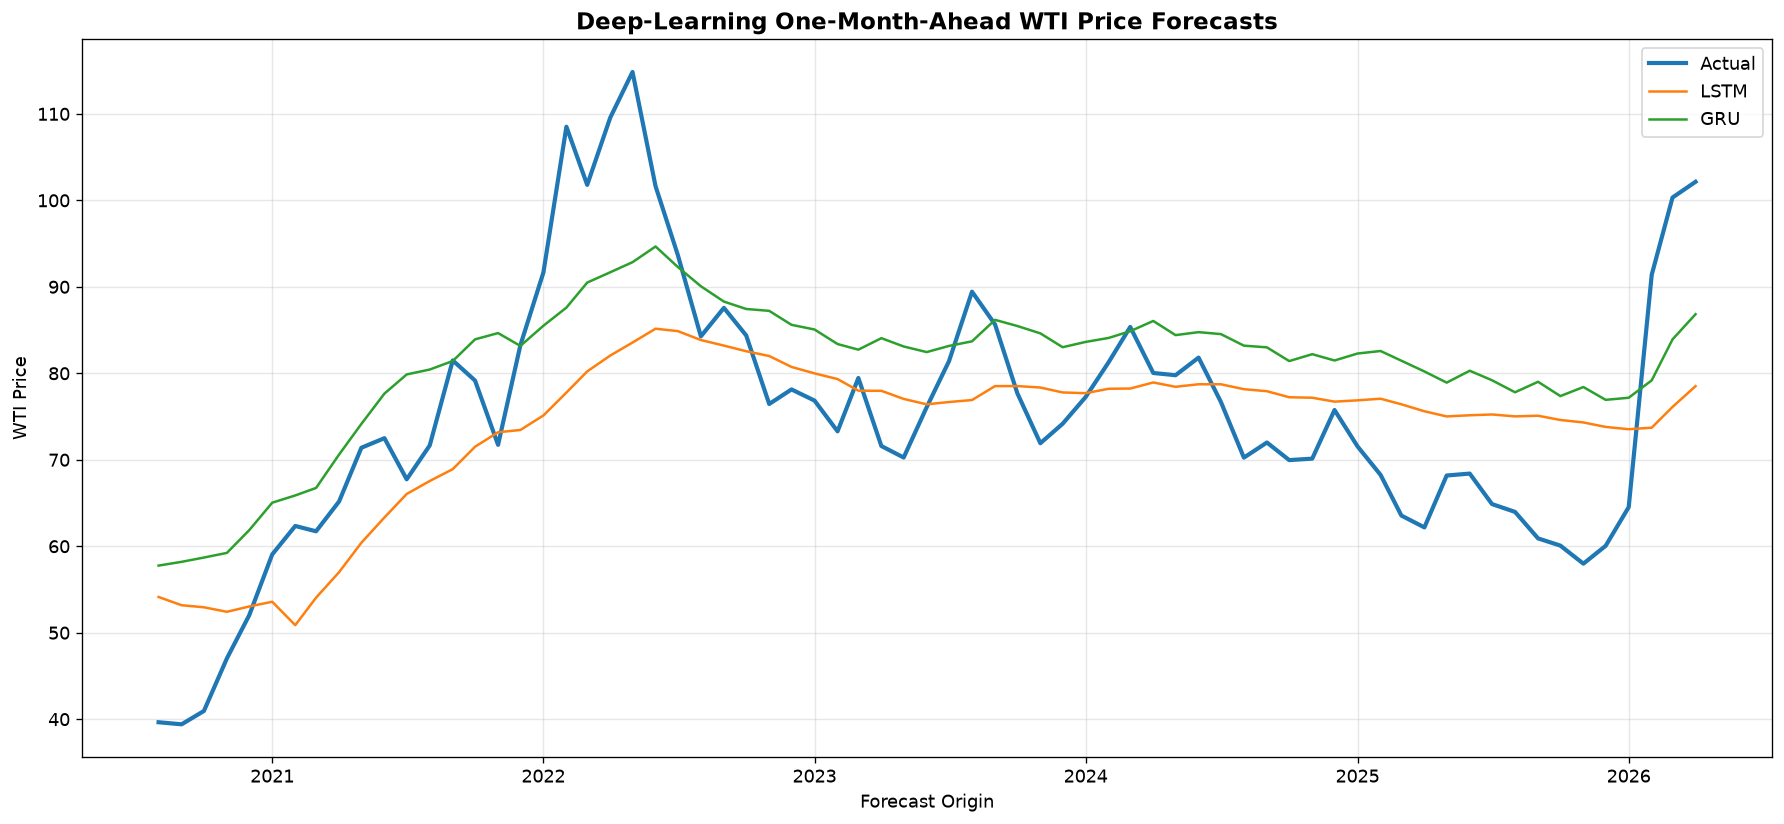

In [111]:
# ============================================================
# CELL 13X: DEEP LEARNING WTI PRICE FORECASTS
# ============================================================

plt.figure(
    figsize=(15, 7)
)


plt.plot(
    test_origin_dates_seq,
    lstm_actual[:, 2],
    label="Actual",
    linewidth=2.5
)


plt.plot(
    test_origin_dates_seq,
    lstm_predictions[:, 2],
    label="LSTM",
    linewidth=1.5
)


plt.plot(
    test_origin_dates_seq,
    gru_predictions[:, 2],
    label="GRU",
    linewidth=1.5
)


plt.title(
    "Deep-Learning One-Month-Ahead WTI Price Forecasts",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Forecast Origin"
)

plt.ylabel(
    "WTI Price"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [112]:
# ============================================================
# CELL 14A: MULTI-HORIZON DATASET BUILDER
# ============================================================

def build_horizon_dataset(
    feature_df,
    feature_columns,
    horizon
):
    """
    Construct supervised forecasting dataset for horizon h.

    Forecast origin: t
    Targets:
        Demand_(t+h)
        Supply_(t+h)
        Price_(t+h)
    """

    target_cols = [
        f"demand_target_h{horizon}",
        f"supply_target_h{horizon}",
        f"price_target_h{horizon}"
    ]

    data = feature_df[
        ["date"] +
        feature_columns +
        target_cols
    ].dropna().copy()

    return data, target_cols


print("Multi-horizon dataset builder ready.")

Multi-horizon dataset builder ready.


In [113]:
# ============================================================
# CELL 14B: FIXED TEMPORAL BOUNDARIES
# ============================================================

TRAIN_END_DATE = train_df["date"].max()
VAL_END_DATE = val_df["date"].max()

print("Training ends   :", TRAIN_END_DATE.date())
print("Validation ends :", VAL_END_DATE.date())

Training ends   : 2014-10-01
Validation ends : 2020-07-01


In [114]:
# ============================================================
# CELL 14C: CHRONOLOGICAL SPLIT FUNCTION
# ============================================================

def chronological_split(
    data,
    train_end_date,
    val_end_date
):

    train = data[
        data["date"] <= train_end_date
    ].copy()

    val = data[
        (data["date"] > train_end_date) &
        (data["date"] <= val_end_date)
    ].copy()

    test = data[
        data["date"] > val_end_date
    ].copy()

    return train, val, test

In [115]:
# ============================================================
# CELL 14D: MULTI-HORIZON RESULTS CONTAINER
# ============================================================

multi_horizon_results = []

multi_horizon_predictions = {}

print("Results containers initialized.")

Results containers initialized.


In [116]:
# ============================================================
# CELL 14E: MULTI-HORIZON MACHINE LEARNING
# ============================================================

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.svm import SVR


for horizon in FORECAST_HORIZONS:

    print("\n" + "=" * 80)
    print(
        f"FORECAST HORIZON: {horizon} MONTH(S)"
    )
    print("=" * 80)


    # --------------------------------------------------------
    # Build horizon-specific dataset
    # --------------------------------------------------------

    horizon_df, horizon_targets = (
        build_horizon_dataset(
            feature_df,
            feature_columns,
            horizon
        )
    )


    # --------------------------------------------------------
    # Chronological split
    # --------------------------------------------------------

    train_h, val_h, test_h = (
        chronological_split(
            horizon_df,
            TRAIN_END_DATE,
            VAL_END_DATE
        )
    )


    # --------------------------------------------------------
    # X / y
    # --------------------------------------------------------

    X_train_h = train_h[
        feature_columns
    ]

    X_val_h = val_h[
        feature_columns
    ]

    X_test_h = test_h[
        feature_columns
    ]


    y_train_h = train_h[
        horizon_targets
    ]

    y_val_h = val_h[
        horizon_targets
    ]

    y_test_h = test_h[
        horizon_targets
    ]


    # --------------------------------------------------------
    # Scaling
    # --------------------------------------------------------

    scaler_h = StandardScaler()

    X_train_h_scaled = (
        scaler_h.fit_transform(
            X_train_h
        )
    )

    X_val_h_scaled = (
        scaler_h.transform(
            X_val_h
        )
    )

    X_test_h_scaled = (
        scaler_h.transform(
            X_test_h
        )
    )


    # --------------------------------------------------------
    # Store predictions
    # --------------------------------------------------------

    multi_horizon_predictions[
        horizon
    ] = {}


    # ========================================================
    # TARGET LOOP
    # ========================================================

    for i, target_name in enumerate(
        target_names
    ):

        print(
            f"\n{target_name}"
        )


        ytr = y_train_h.iloc[:, i]
        yv = y_val_h.iloc[:, i]
        yt = y_test_h.iloc[:, i]


        # ====================================================
        # RIDGE
        # ====================================================

        best_rmse = np.inf
        best_ridge = None


        for alpha in ridge_alphas:

            model = Ridge(
                alpha=alpha
            )

            model.fit(
                X_train_h_scaled,
                ytr
            )

            pred_val = model.predict(
                X_val_h_scaled
            )

            rmse = np.sqrt(
                mean_squared_error(
                    yv,
                    pred_val
                )
            )


            if rmse < best_rmse:

                best_rmse = rmse
                best_ridge = model


        ridge_pred = best_ridge.predict(
            X_test_h_scaled
        )


        # ====================================================
        # RANDOM FOREST
        # ====================================================

        rf_model, rf_params, _ = tune_model(

            RandomForestRegressor,

            rf_grid,

            X_train_h,
            ytr,

            X_val_h,
            yv,

            fixed_params={
                "random_state": SEED,
                "n_jobs": -1
            }
        )


        rf_pred = rf_model.predict(
            X_test_h
        )


        # ====================================================
        # GRADIENT BOOSTING
        # ====================================================

        gb_model, gb_params, _ = tune_model(

            GradientBoostingRegressor,

            gb_grid,

            X_train_h,
            ytr,

            X_val_h,
            yv,

            fixed_params={
                "random_state": SEED
            }
        )


        gb_pred = gb_model.predict(
            X_test_h
        )


        # ====================================================
        # SVR
        # ====================================================

        svr_model, svr_params, _ = tune_model(

            SVR,

            svr_grid,

            X_train_h_scaled,
            ytr,

            X_val_h_scaled,
            yv
        )


        svr_pred = svr_model.predict(
            X_test_h_scaled
        )


        # ----------------------------------------------------
        # Store predictions
        # ----------------------------------------------------

        multi_horizon_predictions[
            horizon
        ][target_name] = {

            "Ridge":
                ridge_pred,

            "Random Forest":
                rf_pred,

            "Gradient Boosting":
                gb_pred,

            "SVR":
                svr_pred,

            "Actual":
                yt.values,

            "Dates":
                test_h["date"].values
        }


        # ----------------------------------------------------
        # Evaluation
        # ----------------------------------------------------

        predictions = {

            "Ridge":
                ridge_pred,

            "Random Forest":
                rf_pred,

            "Gradient Boosting":
                gb_pred,

            "SVR":
                svr_pred
        }


        for model_name, pred in predictions.items():

            metrics = evaluate_forecast(
                yt,
                pred,
                model_name
            )


            multi_horizon_results.append({

                "Horizon":
                    horizon,

                "Target":
                    target_name,

                "Model":
                    model_name,

                "MAE":
                    metrics["MAE"],

                "RMSE":
                    metrics["RMSE"],

                "MAPE (%)":
                    metrics["MAPE (%)"],

                "R2":
                    metrics["R2"]
            })


print(
    "\nMulti-horizon training completed."
)


FORECAST HORIZON: 1 MONTH(S)

Demand

Supply

Price

FORECAST HORIZON: 3 MONTH(S)

Demand

Supply

Price

FORECAST HORIZON: 6 MONTH(S)

Demand

Supply

Price

FORECAST HORIZON: 12 MONTH(S)

Demand

Supply

Price

Multi-horizon training completed.


In [117]:
# ============================================================
# CELL 14F: MULTI-HORIZON RESULTS
# ============================================================

multi_horizon_results_df = pd.DataFrame(
    multi_horizon_results
)


display(
    multi_horizon_results_df
    .sort_values(
        [
            "Target",
            "Horizon",
            "RMSE"
        ]
    )
    .round(4)
)

,Horizon,Target,Model,MAE,RMSE,MAPE (%),R2
2,1,Demand,Gradient Boosting,22497.0576,28844.0135,3.6478,-0.0551
0,1,Demand,Ridge,29777.1574,35946.1274,4.8337,-0.6386
1,1,Demand,Random Forest,32111.3485,35985.4083,5.1962,-0.6422
3,1,Demand,SVR,42821.1210,47562.1219,6.8876,-1.8687
14,3,Demand,Gradient Boosting,23591.2020,29745.2518,3.8236,-0.2068
13,3,Demand,Random Forest,24594.7319,30553.6196,3.9897,-0.2733
12,3,Demand,Ridge,39778.0752,45484.1747,6.4368,-1.8217
15,3,Demand,SVR,43084.7416,47555.7383,6.9238,-2.0846
25,6,Demand,Random Forest,27463.3048,34115.1285,4.4561,-0.6932
26,6,Demand,Gradient Boosting,28540.2465,34644.5564,4.6227,-0.7462


In [118]:
# ============================================================
# CELL 14G: BEST MODEL BY FORECAST HORIZON
# ============================================================

best_models_by_horizon = (

    multi_horizon_results_df

    .sort_values(
        "RMSE"
    )

    .groupby(
        [
            "Target",
            "Horizon"
        ],
        as_index=False
    )

    .first()
)


display(
    best_models_by_horizon.round(4)
)

,Target,Horizon,Model,MAE,RMSE,MAPE (%),R2
0,Demand,1,Gradient Boosting,22497.0576,28844.0135,3.6478,-0.0551
1,Demand,3,Gradient Boosting,23591.2020,29745.2518,3.8236,-0.2068
2,Demand,6,Random Forest,27463.3048,34115.1285,4.4561,-0.6932
3,Demand,12,Gradient Boosting,21949.0915,26435.7209,3.5081,-0.4756
4,Price,1,Random Forest,11.6534,14.7168,14.8928,0.0847
5,Price,3,Random Forest,11.1470,15.1503,13.5099,-0.1196
6,Price,6,Random Forest,17.3232,21.1285,20.7130,-1.6066
7,Price,12,Random Forest,25.2892,28.5069,30.4355,-3.7868
8,Supply,1,Ridge,17367.8826,19361.3644,4.5676,0.6348
9,Supply,3,Ridge,14291.8905,18075.8656,3.8214,0.6597


In [119]:
# ============================================================
# CELL 14H: PRICE RMSE TABLE
# ============================================================

price_rmse_table = (

    multi_horizon_results_df[

        multi_horizon_results_df[
            "Target"
        ] == "Price"

    ]

    .pivot(

        index="Model",

        columns="Horizon",

        values="RMSE"
    )
)


price_rmse_table.columns = [
    f"{h}-month"
    for h in price_rmse_table.columns
]


display(
    price_rmse_table.round(4)
)

,1-month,3-month,6-month,12-month
Model,,,,
Gradient Boosting,20.0850,24.3797,24.6144,30.9635
Random Forest,14.7168,15.1503,21.1285,28.5069
Ridge,20.9453,29.6863,39.7886,55.6000
SVR,24.6837,30.6277,31.0140,31.4979


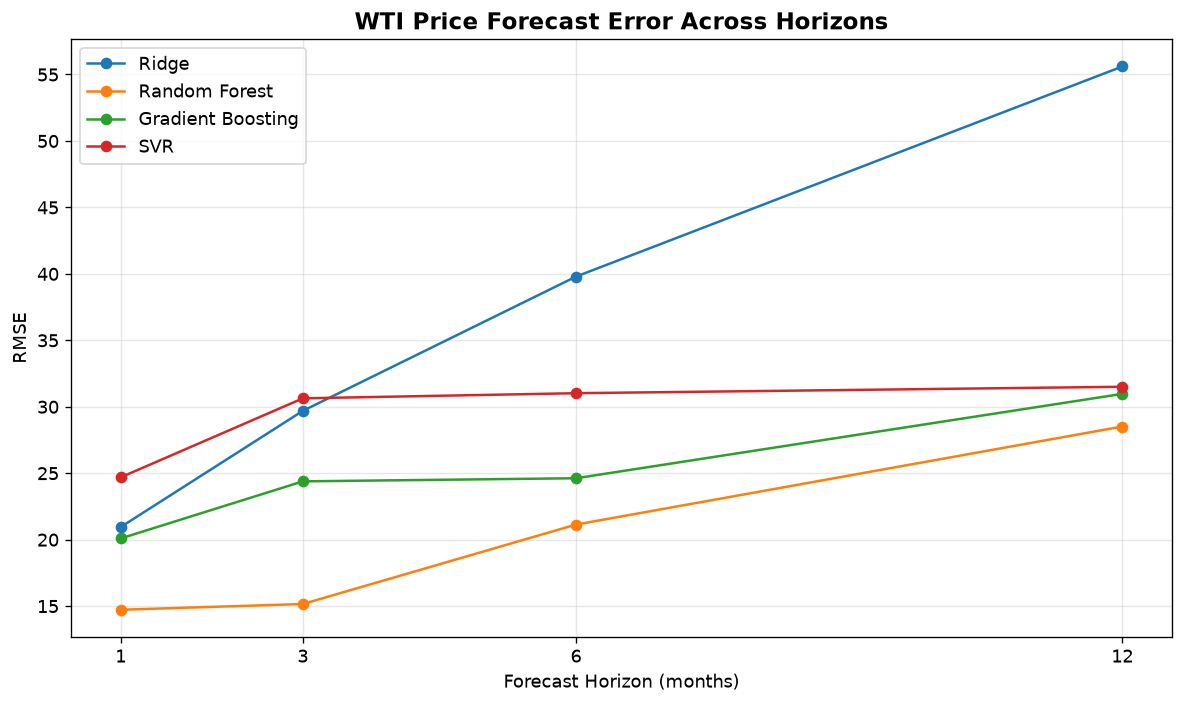

In [120]:
# ============================================================
# CELL 14I: PRICE RMSE VS FORECAST HORIZON
# ============================================================

price_results = (
    multi_horizon_results_df[
        multi_horizon_results_df[
            "Target"
        ] == "Price"
    ]
)


plt.figure(
    figsize=(10, 6)
)


for model_name in (
    price_results["Model"].unique()
):

    temp = price_results[
        price_results[
            "Model"
        ] == model_name
    ].sort_values(
        "Horizon"
    )


    plt.plot(
        temp["Horizon"],
        temp["RMSE"],
        marker="o",
        label=model_name
    )


plt.title(
    "WTI Price Forecast Error Across Horizons",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Forecast Horizon (months)"
)

plt.ylabel(
    "RMSE"
)

plt.xticks(
    FORECAST_HORIZONS
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()

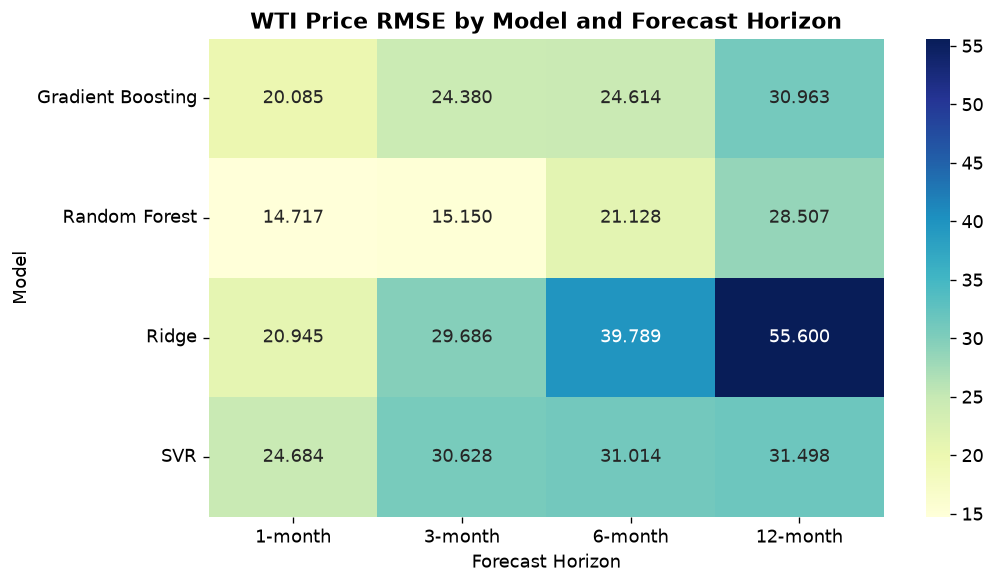

In [121]:
# ============================================================
# CELL 14J: MULTI-HORIZON RMSE HEATMAP
# ============================================================

plt.figure(
    figsize=(9, 5)
)


sns.heatmap(
    price_rmse_table,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu"
)


plt.title(
    "WTI Price RMSE by Model and Forecast Horizon",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel(
    "Forecast Horizon"
)

plt.ylabel(
    "Model"
)

plt.tight_layout()
plt.show()

In [123]:
# ============================================================
# DATA PREPROCESSING: PUBLICATION TABLES AND FIGURES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DATE_COL = "date"
D_COL = "demand"
S_COL = "supply"
P_COL = "price"

# Folder for manuscript-ready outputs
OUTPUT_DIR = Path("preprocessing_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Publication plotting defaults
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "legend.fontsize": 9,
    "figure.dpi": 120,
    "savefig.dpi": 600,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# ------------------------------------------------------------
# 2. PREPARE DATA
# ------------------------------------------------------------

data = df.copy()

data[DATE_COL] = pd.to_datetime(data[DATE_COL])
data = data.sort_values(DATE_COL).reset_index(drop=True)

# Ensure numeric
for col in [D_COL, S_COL, P_COL]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

print("Dataset shape:", data.shape)
print("Period:", data[DATE_COL].min(), "to", data[DATE_COL].max())

Dataset shape: (485, 27)
Period: 1986-01-01 00:00:00 to 2026-05-01 00:00:00



# Final Robustness, Statistical Significance, and Sensitivity Analyses

The following cells reproduce the additional robustness results reported in the manuscript: one-month forecast diagnostics, directional accuracy, improvement over persistence, Diebold–Mariano tests, actual-versus-predicted plots, feature importance, look-back sensitivity, chronological split sensitivity, and feature-set ablation.


In [124]:
# ============================================================
# FINAL ROBUSTNESS ANALYSIS: SETUP AND ONE-MONTH DIAGNOSTICS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.stattools import acf

# Locate the supplied workbook.
candidate_files = [
    Path("EIA_LV_Demand_Supply_Harmonized (1)(2).xlsx"),
    Path("/mnt/data/EIA_LV_Demand_Supply_Harmonized (1)(2).xlsx"),
    Path("EIA_LV_Demand_Supply_Harmonized(1).xlsx"),
    Path("/mnt/data/EIA_LV_Demand_Supply_Harmonized(1).xlsx"),
]
FILE = next((p for p in candidate_files if p.exists()), None)
if FILE is None:
    raise FileNotFoundError(
        "Place the supplied EIA Excel workbook in the notebook directory "
        "or update FILE to its location."
    )

OUT = OUTPUT_DIR
OUT.mkdir(exist_ok=True)

d = pd.read_excel(FILE, sheet_name="LV Ready").rename(columns={
    "t (month)": "t",
    "Date": "date",
    "D(t) raw": "demand",
    "S(t) raw": "supply",
    "P(t) raw": "price",
    "d(t)=D/mean(D)": "demand_norm",
    "s(t)=S/mean(S)": "supply_norm",
    "p(t)=P/mean(P)": "price_norm",
})
d["date"] = pd.to_datetime(d["date"])

RAW = ["demand", "supply", "price"]
NAMES = ["Demand", "Supply", "WTI Price"]

for v in RAW:
    d[f"{v}_logdiff"] = np.log(d[v]).diff()

d["month_sin"] = np.sin(2 * np.pi * d.date.dt.month / 12)
d["month_cos"] = np.cos(2 * np.pi * d.date.dt.month / 12)

f = d.copy()
LAGS = [1, 2, 3, 6, 12, 18, 24]

for v in RAW + [f"{v}_logdiff" for v in RAW]:
    for lag in LAGS:
        f[f"{v}_lag{lag}"] = f[v].shift(lag)

for v in RAW:
    for w in [3, 6, 12]:
        f[f"{v}_rollmean{w}"] = f[v].shift(1).rolling(w).mean()
        f[f"{v}_rollstd{w}"] = f[v].shift(1).rolling(w).std()
    for q in [1, 3, 6, 12]:
        f[f"{v}_pct{q}"] = f[v].pct_change(q).shift(1)

D, S, P = f.demand.shift(1), f.supply.shift(1), f.price.shift(1)
f["ds_gap"] = D - S
f["ds_imbalance"] = (D - S) / (D + S)
f["demand_supply_ratio"] = D / S
f["price_imbalance"] = P * f["ds_imbalance"]

for v in RAW:
    f[f"{v}_target_h1"] = f[v].shift(-1)

features = ["month_sin", "month_cos"]
for v in RAW + [f"{v}_logdiff" for v in RAW]:
    features += [f"{v}_lag{x}" for x in LAGS]

for v in RAW:
    for w in [3, 6, 12]:
        features += [f"{v}_rollmean{w}", f"{v}_rollstd{w}"]
    features += [f"{v}_pct{q}" for q in [1, 3, 6, 12]]

features += ["ds_gap", "ds_imbalance", "demand_supply_ratio", "price_imbalance"]
targets = [f"{v}_target_h1" for v in RAW]

m = f[["date"] + RAW + features + targets].dropna().copy()

n = len(m)
a = int(0.70 * n)
b = int(0.85 * n)
tr, te = m.iloc[:a], m.iloc[b:]

Xtr, Xte = tr[features], te[features]
Ytr, Yte = tr[targets], te[targets]

ss = StandardScaler().fit(Xtr)
Xtrs, Xtes = ss.transform(Xtr), ss.transform(Xte)

rfp = {
    "Demand": {"max_depth": 8, "max_features": 0.7, "min_samples_leaf": 2, "n_estimators": 500},
    "Supply": {"max_depth": 5, "max_features": 0.7, "min_samples_leaf": 2, "n_estimators": 200},
    "WTI Price": {"max_depth": None, "max_features": 0.7, "min_samples_leaf": 5, "n_estimators": 500},
}
gbp = {
    "Demand": {"learning_rate": 0.1, "max_depth": 3, "min_samples_leaf": 3, "n_estimators": 100, "subsample": 1.0},
    "Supply": {"learning_rate": 0.1, "max_depth": 2, "min_samples_leaf": 3, "n_estimators": 400, "subsample": 1.0},
    "WTI Price": {"learning_rate": 0.01, "max_depth": 3, "min_samples_leaf": 3, "n_estimators": 200, "subsample": 0.8},
}
svrp = {
    "Demand": {"C": 100, "epsilon": 0.01, "gamma": 0.1, "kernel": "rbf"},
    "Supply": {"C": 100, "epsilon": 0.01, "gamma": 0.001, "kernel": "rbf"},
    "WTI Price": {"C": 100, "epsilon": 0.1, "gamma": 0.001, "kernel": "rbf"},
}
alpha = {"Demand": 10, "Supply": 10, "WTI Price": 1000}

pred, fitted = {}, {}

for j, name in enumerate(NAMES):
    y = Ytr.iloc[:, j]

    lm = LinearRegression().fit(Xtrs, y)
    pred[name, "Linear Regression"] = lm.predict(Xtes)
    fitted[name, "Linear Regression"] = lm

    rd = Ridge(alpha=alpha[name]).fit(Xtrs, y)
    pred[name, "Ridge"] = rd.predict(Xtes)
    fitted[name, "Ridge"] = rd

    rf = RandomForestRegressor(random_state=42, n_jobs=-1, **rfp[name]).fit(Xtr, y)
    pred[name, "Random Forest"] = rf.predict(Xte)
    fitted[name, "Random Forest"] = rf

    gb = GradientBoostingRegressor(random_state=42, **gbp[name]).fit(Xtr, y)
    pred[name, "Gradient Boosting"] = gb.predict(Xte)
    fitted[name, "Gradient Boosting"] = gb

    sv = SVR(**svrp[name]).fit(Xtrs, y)
    pred[name, "SVR"] = sv.predict(Xtes)
    fitted[name, "SVR"] = sv

    # Persistence forecast: y_(t+1) = y_t.
    pred[name, "Naive"] = te[RAW[j]].values

rows = []
for j, name in enumerate(NAMES):
    actual = Yte.iloc[:, j].values
    current = te[RAW[j]].values
    naive_rmse = mean_squared_error(actual, pred[name, "Naive"]) ** 0.5

    for model in ["Naive", "Linear Regression", "Ridge", "Random Forest", "Gradient Boosting", "SVR"]:
        p = pred[name, model]
        e = p - actual
        rmse = mean_squared_error(actual, p) ** 0.5

        # Persistence predicts zero change, so directional accuracy is not meaningful for it.
        da = np.nan if model == "Naive" else 100 * np.mean(
            np.sign(p - current) == np.sign(actual - current)
        )

        rows.append([
            name,
            model,
            mean_absolute_error(actual, p),
            rmse,
            e.mean(),
            da,
            100 * (1 - rmse / naive_rmse),
            acf(e, nlags=1, fft=False)[1],
        ])

diag = pd.DataFrame(
    rows,
    columns=[
        "Target", "Model", "MAE", "RMSE", "Bias",
        "Directional Accuracy (%)", "RMSE Improvement vs Naive (%)",
        "Residual ACF(1)"
    ],
)
diag.to_csv(TABLE_DIR / "table_forecast_diagnostics.csv", index=False)

print("Test period:", te.date.min().date(), "to", te.date.max().date(), "N =", len(te))
display(diag.round(4))

Test period: 2020-08-01 to 2026-04-01 N = 69


,Target,Model,MAE,RMSE,Bias,Directional Accuracy (%),RMSE Improvement vs Naive (%),Residual ACF(1)
0,Demand,Naive,26573.2464,33726.2882,-679.6232,NaN,0.0000,-0.6232
1,Demand,Linear Regression,46566.3703,56334.6769,16623.2853,66.6667,-67.0349,0.5209
2,Demand,Ridge,29777.1574,35946.1274,-27256.2634,72.4638,-6.5819,0.4081
3,Demand,Random Forest,32287.7342,36190.1351,-28880.3691,59.4203,-7.3054,0.2763
4,Demand,Gradient Boosting,22538.3944,28866.2702,-19491.0557,73.9130,14.4102,0.4785
5,Demand,SVR,42821.1210,47562.1219,-38387.4577,56.5217,-41.0239,0.2482
6,Supply,Naive,16594.0580,22013.7615,-1399.2174,NaN,0.0000,-0.6104
7,Supply,Linear Regression,13827.4307,18575.3379,3229.3429,73.9130,15.6194,0.3316
8,Supply,Ridge,17367.8826,19361.3644,-12636.5682,59.4203,12.0488,0.0618
9,Supply,Random Forest,120296.6711,124197.3463,-120296.6711,49.2754,-464.1805,0.7115


In [125]:
# ============================================================
# DIEBOLD-MARIANO TESTS
# ============================================================

def dm_test(actual, forecast_a, forecast_b):
    """
    Two-sided Diebold-Mariano-style comparison using squared-error loss.
    Negative statistic => forecast_a has lower mean squared loss.
    """
    ea = np.asarray(actual) - np.asarray(forecast_a)
    eb = np.asarray(actual) - np.asarray(forecast_b)
    loss_diff = ea**2 - eb**2
    T = len(loss_diff)
    variance = np.var(loss_diff, ddof=1)

    if variance == 0:
        return np.nan, np.nan

    statistic = loss_diff.mean() / np.sqrt(variance / T)
    p_value = 2 * (1 - stats.norm.cdf(abs(statistic)))
    return statistic, p_value

selected = {
    "Demand": "Gradient Boosting",
    "Supply": "Linear Regression",
    "WTI Price": "Naive",
}

dm_rows = []
for j, name in enumerate(NAMES):
    for comparator in ["Naive", "Ridge", "Random Forest", "Gradient Boosting"]:
        if comparator == selected[name]:
            continue
        stat, pval = dm_test(
            Yte.iloc[:, j],
            pred[name, selected[name]],
            pred[name, comparator],
        )
        dm_rows.append([name, selected[name], comparator, stat, pval])

dm_df = pd.DataFrame(
    dm_rows,
    columns=["Target", "Selected Model", "Comparator", "DM statistic", "p-value"],
)
dm_df.to_csv(TABLE_DIR / "table_diebold_mariano.csv", index=False)
display(dm_df.round(4))

,Target,Selected Model,Comparator,DM statistic,p-value
0,Demand,Gradient Boosting,Naive,-1.1702,0.2419
1,Demand,Gradient Boosting,Ridge,-2.8892,0.0039
2,Demand,Gradient Boosting,Random Forest,-4.4375,0.0000
3,Supply,Linear Regression,Naive,-1.2120,0.2255
4,Supply,Linear Regression,Ridge,-0.3599,0.7189
5,Supply,Linear Regression,Random Forest,-17.3810,0.0000
6,Supply,Linear Regression,Gradient Boosting,-17.2898,0.0000
7,WTI Price,Naive,Ridge,-6.2600,0.0000
8,WTI Price,Naive,Random Forest,-5.1468,0.0000
9,WTI Price,Naive,Gradient Boosting,-7.0335,0.0000


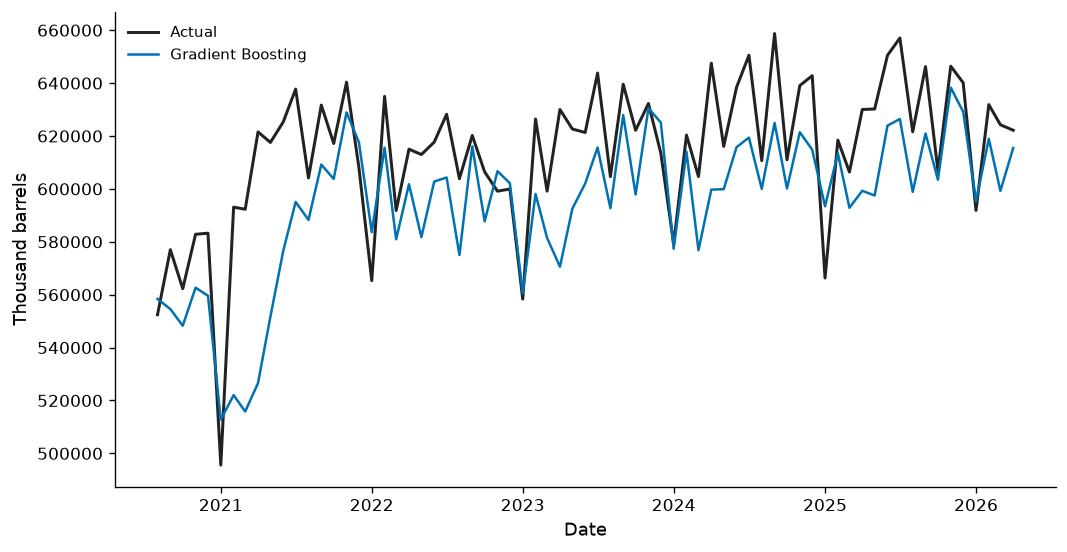

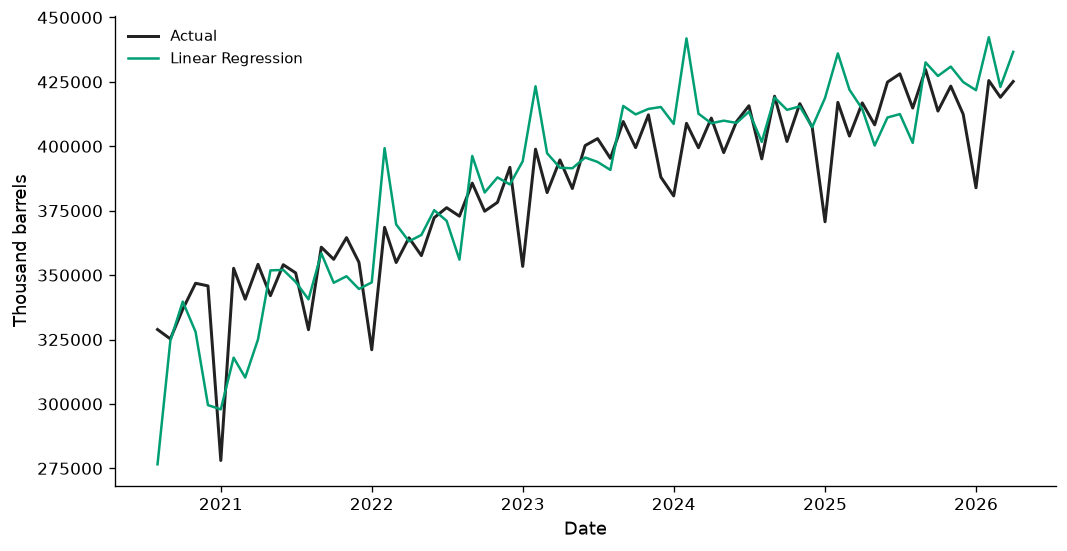

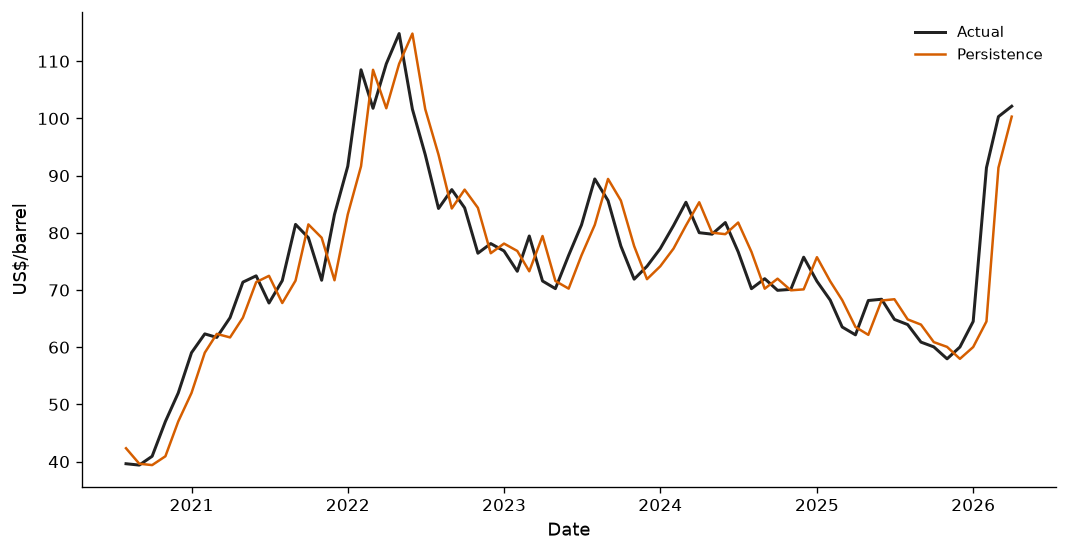

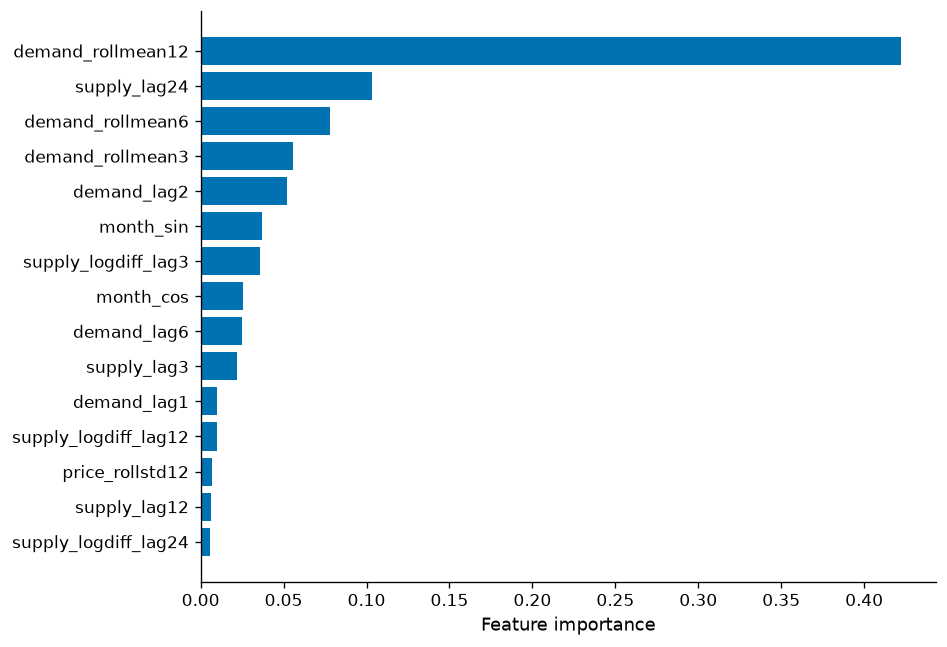

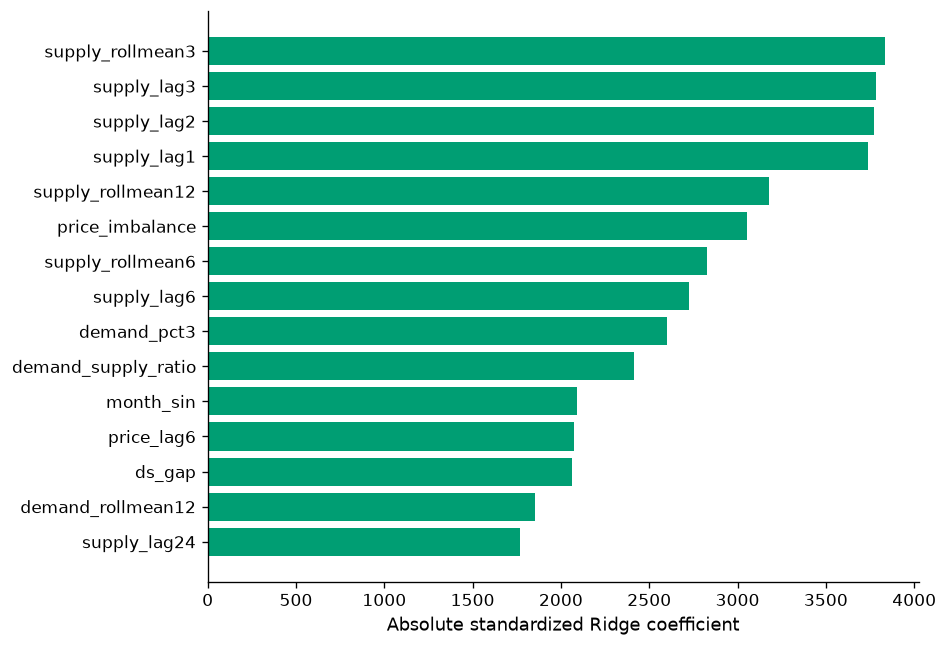

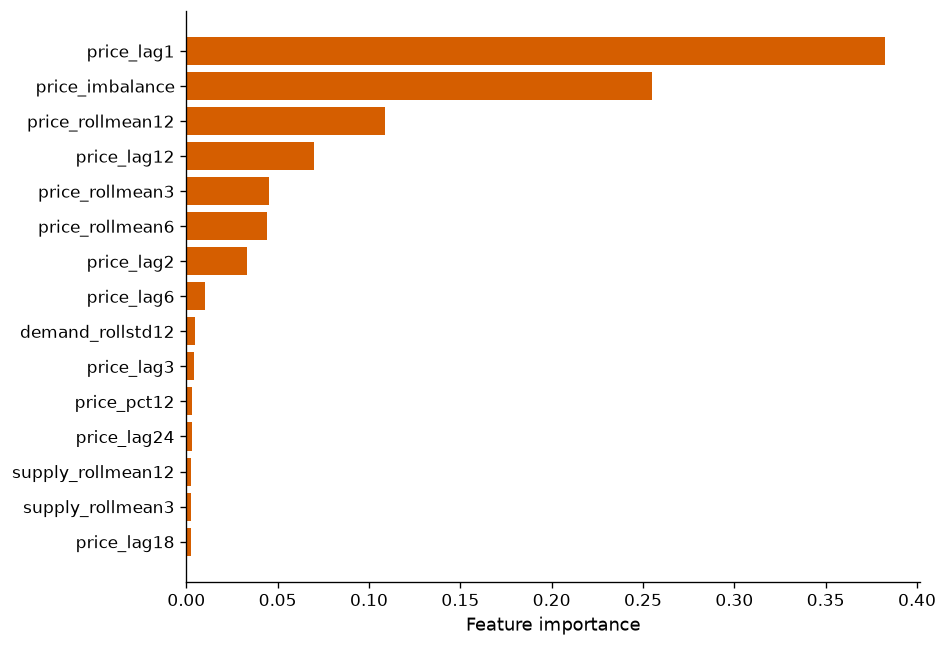

,Feature,Importance,Target,Model
0,demand_rollmean12,0.422178,Demand,Gradient Boosting
1,supply_lag24,0.103411,Demand,Gradient Boosting
2,demand_rollmean6,0.078066,Demand,Gradient Boosting
3,demand_rollmean3,0.055677,Demand,Gradient Boosting
4,demand_lag2,0.051858,Demand,Gradient Boosting
5,month_sin,0.037094,Demand,Gradient Boosting
6,supply_logdiff_lag3,0.035782,Demand,Gradient Boosting
7,month_cos,0.025280,Demand,Gradient Boosting
8,demand_lag6,0.024842,Demand,Gradient Boosting
9,supply_lag3,0.022159,Demand,Gradient Boosting


In [126]:
# ============================================================
# ACTUAL VS PREDICTED AND FEATURE IMPORTANCE FIGURES
# ============================================================

plt.rcParams.update({
    "font.size": 10,
    "savefig.dpi": 600,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

colors = {"Demand": "#0072B2", "Supply": "#009E73", "WTI Price": "#D55E00"}

for j, name in enumerate(NAMES):
    fig, ax = plt.subplots(figsize=(9, 4.7))
    ax.plot(te.date, Yte.iloc[:, j], label="Actual", color="#222222", linewidth=1.8)
    ax.plot(
        te.date,
        pred[name, selected[name]],
        label="Persistence" if selected[name] == "Naive" else selected[name],
        color=colors[name],
        linewidth=1.5,
    )
    ax.set_xlabel("Date")
    ax.set_ylabel("US$/barrel" if name == "WTI Price" else "Thousand barrels")
    ax.legend(frameon=False)
    fig.tight_layout()

    stem = name.lower().replace(" ", "_")
    fig.savefig(OUT / f"fig_{stem}_actual_vs_predicted.pdf", bbox_inches="tight")
    fig.savefig(OUT / f"fig_{stem}_actual_vs_predicted.png", bbox_inches="tight")
    plt.show()

# Interpretation models used for feature-importance analysis.
importance_rows = []
interpretation_model = {
    "Demand": "Gradient Boosting",
    "Supply": "Ridge",
    "WTI Price": "Random Forest",
}

for name in NAMES:
    model_name = interpretation_model[name]
    estimator = fitted[name, model_name]
    values = np.abs(estimator.coef_) if model_name == "Ridge" else estimator.feature_importances_

    q = (
        pd.DataFrame({"Feature": features, "Importance": values})
        .sort_values("Importance", ascending=False)
        .head(15)
    )
    q["Target"] = name
    q["Model"] = model_name
    importance_rows.append(q)

importance_df = pd.concat(importance_rows, ignore_index=True)
importance_df.to_csv(TABLE_DIR / "table_feature_importance.csv", index=False)

for name in NAMES:
    q = importance_df[importance_df.Target == name].sort_values("Importance")
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.barh(q.Feature, q.Importance, color=colors[name])
    ax.set_xlabel(
        "Absolute standardized Ridge coefficient"
        if name == "Supply"
        else "Feature importance"
    )
    fig.tight_layout()

    stem = name.lower().replace(" ", "_")
    fig.savefig(OUT / f"fig_{stem}_feature_importance.pdf", bbox_inches="tight")
    fig.savefig(OUT / f"fig_{stem}_feature_importance.png", bbox_inches="tight")
    plt.show()

display(importance_df)

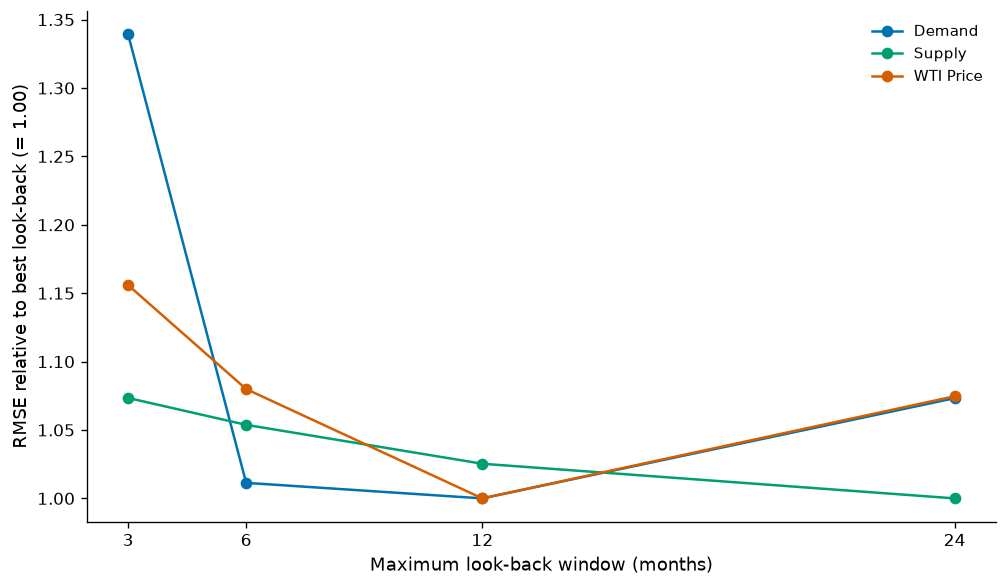

,Target,Maximum Look-back (months),Predictors,Test N,RMSE
0,Demand,3,36,72,36021.7492
1,Supply,3,36,72,20782.9670
2,WTI Price,3,36,72,15.6072
3,Demand,6,51,72,27201.0726
4,Supply,6,51,72,20402.3223
5,WTI Price,6,51,72,14.5806
6,Demand,12,66,71,26895.6411
7,Supply,12,66,71,19851.7428
8,WTI Price,12,66,71,13.5016
9,Demand,24,78,69,28866.2702


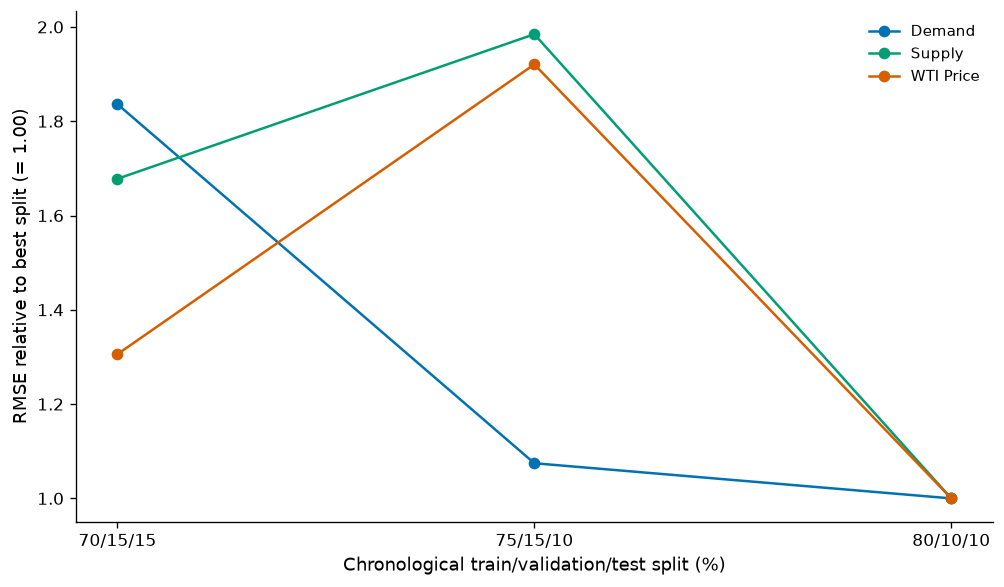

,Target,Train/Validation/Test (%),Test N,RMSE
0,Demand,70/15/15,69,28866.2702
1,Supply,70/15/15,69,19361.3644
2,WTI Price,70/15/15,69,14.5095
3,Demand,75/15/10,46,16893.3990
4,Supply,75/15/10,46,22900.0661
5,WTI Price,75/15/10,46,21.3396
6,Demand,80/10/10,46,15721.1204
7,Supply,80/10/10,46,11539.2178
8,WTI Price,80/10/10,46,11.1113


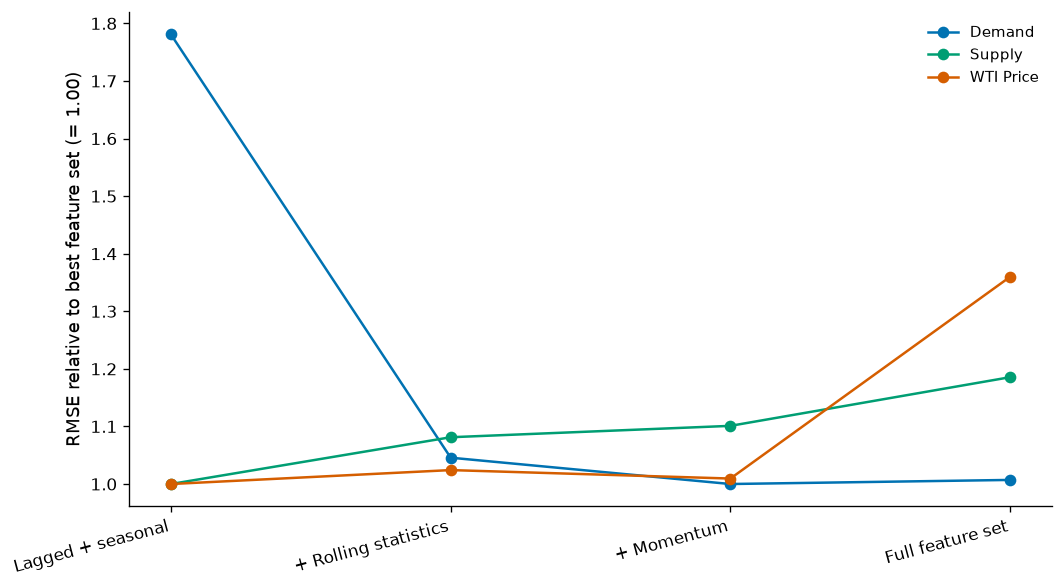

,Target,Feature Set,Predictors,Test N,RMSE
0,Demand,Lagged + seasonal,44,69,51040.8542
1,Supply,Lagged + seasonal,44,69,16331.2236
2,WTI Price,Lagged + seasonal,44,69,10.6695
3,Demand,+ Rolling statistics,62,69,29973.2769
4,Supply,+ Rolling statistics,62,69,17658.3021
5,WTI Price,+ Rolling statistics,62,69,10.9277
6,Demand,+ Momentum,74,69,28662.3359
7,Supply,+ Momentum,74,69,17981.1237
8,WTI Price,+ Momentum,74,69,10.7709
9,Demand,Full feature set,78,69,28866.2702


In [127]:
# ============================================================
# LOOK-BACK, SPLIT, AND FEATURE-ABLATION SENSITIVITY
# ============================================================

def lookback_columns(L):
    cols = ["month_sin", "month_cos"]
    allowed = [x for x in [1, 2, 3, 6, 12, 18, 24] if x <= L]

    for v in RAW + [f"{v}_logdiff" for v in RAW]:
        cols += [f"{v}_lag{x}" for x in allowed]

    for v in RAW:
        for w in [3, 6, 12]:
            if w <= L:
                cols += [f"{v}_rollmean{w}", f"{v}_rollstd{w}"]
        for q in [1, 3, 6, 12]:
            if q <= L:
                cols += [f"{v}_pct{q}"]

    cols += ["ds_gap", "ds_imbalance", "demand_supply_ratio", "price_imbalance"]
    return cols


def selected_predict(name, X_train, y_train, X_test):
    if name == "Demand":
        model = GradientBoostingRegressor(
            random_state=42, **gbp["Demand"]
        ).fit(X_train, y_train)
        return model.predict(X_test)

    if name == "Supply":
        scaler_local = StandardScaler().fit(X_train)
        model = Ridge(alpha=10).fit(scaler_local.transform(X_train), y_train)
        return model.predict(scaler_local.transform(X_test))

    model = RandomForestRegressor(
        random_state=42, n_jobs=-1, **rfp["WTI Price"]
    ).fit(X_train, y_train)
    return model.predict(X_test)


# ----- Look-back sensitivity -----
look_rows = []

for L in [3, 6, 12, 24]:
    cc = lookback_columns(L)
    z = f[["date"] + cc + targets].dropna().copy()
    nn = len(z)
    aa = int(0.70 * nn)
    bb = int(0.85 * nn)
    train_l, test_l = z.iloc[:aa], z.iloc[bb:]

    for j, name in enumerate(NAMES):
        pp = selected_predict(name, train_l[cc], train_l[targets[j]], test_l[cc])
        look_rows.append([
            name, L, len(cc), len(test_l),
            mean_squared_error(test_l[targets[j]], pp) ** 0.5
        ])

lookback_df = pd.DataFrame(
    look_rows,
    columns=["Target", "Maximum Look-back (months)", "Predictors", "Test N", "RMSE"],
)
lookback_df.to_csv(TABLE_DIR / "table_lookback_sensitivity.csv", index=False)

lookback_plot = lookback_df.copy()
lookback_plot["Relative RMSE"] = lookback_plot.groupby("Target")["RMSE"].transform(
    lambda x: x / x.min()
)

fig, ax = plt.subplots(figsize=(8.5, 5))
for name in NAMES:
    q = lookback_plot[lookback_plot.Target == name]
    ax.plot(
        q["Maximum Look-back (months)"],
        q["Relative RMSE"],
        marker="o",
        label=name,
        color=colors[name],
    )
ax.set_xlabel("Maximum look-back window (months)")
ax.set_ylabel("RMSE relative to best look-back (= 1.00)")
ax.set_xticks([3, 6, 12, 24])
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fig_lookback_sensitivity.pdf", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "fig_lookback_sensitivity.png", bbox_inches="tight")
plt.show()

display(lookback_df.round(4))


# ----- Chronological split sensitivity -----
split_rows = []

for train_frac, val_frac, test_frac in [
    (0.70, 0.15, 0.15),
    (0.75, 0.15, 0.10),
    (0.80, 0.10, 0.10),
]:
    nn = len(m)
    aa = int(train_frac * nn)
    bb = int((train_frac + val_frac) * nn)
    train_s, test_s = m.iloc[:aa], m.iloc[bb:]

    for j, name in enumerate(NAMES):
        pp = selected_predict(
            name, train_s[features], train_s[targets[j]], test_s[features]
        )
        split_rows.append([
            name,
            f"{int(train_frac*100)}/{int(val_frac*100)}/{int(test_frac*100)}",
            len(test_s),
            mean_squared_error(test_s[targets[j]], pp) ** 0.5,
        ])

split_df = pd.DataFrame(
    split_rows,
    columns=["Target", "Train/Validation/Test (%)", "Test N", "RMSE"],
)
split_df.to_csv(TABLE_DIR / "table_split_sensitivity.csv", index=False)

split_plot = split_df.copy()
split_plot["Relative RMSE"] = split_plot.groupby("Target")["RMSE"].transform(
    lambda x: x / x.min()
)
split_order = ["70/15/15", "75/15/10", "80/10/10"]

fig, ax = plt.subplots(figsize=(8.5, 5))
x = np.arange(len(split_order))
for name in NAMES:
    q = (
        split_plot[split_plot.Target == name]
        .set_index("Train/Validation/Test (%)")
        .loc[split_order]
    )
    ax.plot(x, q["Relative RMSE"], marker="o", label=name, color=colors[name])

ax.set_xticks(x, split_order)
ax.set_xlabel("Chronological train/validation/test split (%)")
ax.set_ylabel("RMSE relative to best split (= 1.00)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fig_split_sensitivity.pdf", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "fig_split_sensitivity.png", bbox_inches="tight")
plt.show()

display(split_df.round(4))


# ----- Feature-set ablation -----
lag_seasonal = ["month_sin", "month_cos"] + [c for c in features if "_lag" in c]
rolling = [c for c in features if "_rollmean" in c or "_rollstd" in c]
momentum = [c for c in features if "_pct" in c]

feature_sets = {
    "Lagged + seasonal": lag_seasonal,
    "+ Rolling statistics": lag_seasonal + rolling,
    "+ Momentum": lag_seasonal + rolling + momentum,
    "Full feature set": features,
}

ablation_rows = []

for label, cc in feature_sets.items():
    z = f[["date"] + cc + targets].dropna().copy()
    nn = len(z)
    aa = int(0.70 * nn)
    bb = int(0.85 * nn)
    train_a, test_a = z.iloc[:aa], z.iloc[bb:]

    for j, name in enumerate(NAMES):
        pp = selected_predict(name, train_a[cc], train_a[targets[j]], test_a[cc])
        ablation_rows.append([
            name, label, len(cc), len(test_a),
            mean_squared_error(test_a[targets[j]], pp) ** 0.5,
        ])

ablation_df = pd.DataFrame(
    ablation_rows,
    columns=["Target", "Feature Set", "Predictors", "Test N", "RMSE"],
)
ablation_df.to_csv(TABLE_DIR / "table_feature_ablation.csv", index=False)

ablation_plot = ablation_df.copy()
ablation_plot["Relative RMSE"] = ablation_plot.groupby("Target")["RMSE"].transform(
    lambda x: x / x.min()
)
feature_order = list(feature_sets.keys())

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(feature_order))
for name in NAMES:
    q = (
        ablation_plot[ablation_plot.Target == name]
        .set_index("Feature Set")
        .loc[feature_order]
    )
    ax.plot(x, q["Relative RMSE"], marker="o", label=name, color=colors[name])

ax.set_xticks(x, feature_order, rotation=15, ha="right")
ax.set_ylabel("RMSE relative to best feature set (= 1.00)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fig_feature_ablation.pdf", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "fig_feature_ablation.png", bbox_inches="tight")
plt.show()

display(ablation_df.round(4))


## Reproducibility note

All train/validation/test partitions are chronological. Scaling is fitted on training observations only. The persistence forecast is retained as a strong time-series benchmark. All generated manuscript figures are saved to `outputs/figures/`, while generated tables are saved to `outputs/tables/`.


In [128]:
# ============================================================
# OUTPUT INVENTORY
# Run this after completing the notebook.
# ============================================================

figure_files = sorted(p for p in FIGURE_DIR.glob("*") if p.is_file())
table_files = sorted(p for p in TABLE_DIR.glob("*") if p.is_file())

print(f"Saved figures: {len(figure_files)}")
for p in figure_files:
    print("  ", p)

print(f"\nSaved tables: {len(table_files)}")
for p in table_files:
    print("  ", p)


Saved figures: 6
   outputs\figures\fig_feature_ablation.pdf
   outputs\figures\fig_feature_ablation.png
   outputs\figures\fig_lookback_sensitivity.pdf
   outputs\figures\fig_lookback_sensitivity.png
   outputs\figures\fig_split_sensitivity.pdf
   outputs\figures\fig_split_sensitivity.png

Saved tables: 6
   outputs\tables\table_diebold_mariano.csv
   outputs\tables\table_feature_ablation.csv
   outputs\tables\table_feature_importance.csv
   outputs\tables\table_forecast_diagnostics.csv
   outputs\tables\table_lookback_sensitivity.csv
   outputs\tables\table_split_sensitivity.csv


# Reviewer-Requested Major-Revision Analyses

This section extends the original monthly petroleum forecasting analysis in response to the reviewers. It adds an auditable common-sample prediction ledger, recalculated metrics, explicit out-of-sample \(R^2\) relative to persistence, expanded loss functions, Harvey–Leybourne–Newbold forecast-encompassing tests, validation-based forecast combinations, an economic-value illustration for monthly WTI forecasts, and a separate daily-WTI robustness experiment at 1-, 5-, 10-, and 20-trading-day horizons.

The original monthly core experiment is retained. These analyses are additional robustness and application tests.

In [129]:
# Revision output folders
from pathlib import Path
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REVISION_DIR = OUTPUT_DIR / "reviewer_revision"
REV_FIGURE_DIR = REVISION_DIR / "figures"
REV_TABLE_DIR = REVISION_DIR / "tables"
REV_DATA_DIR = REVISION_DIR / "data"
for p in (REVISION_DIR, REV_FIGURE_DIR, REV_TABLE_DIR, REV_DATA_DIR):
    p.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED); random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
print("Revision outputs:", REVISION_DIR.resolve())

Revision outputs: C:\Users\SOBAdmin\Desktop\multi-horizon\preprocessing_outputs\reviewer_revision


## Common forecast origins and out-of-sample \(R^2\)

For every target and horizon, all competing forecasts are aligned to identical forecast origins and realized target observations before metrics are computed.

\[
R^2_{\mathrm{OOS}}=
1-\frac{\sum_t(y_t-\widehat y_{m,t})^2}
{\sum_t(y_t-\widehat y_{\mathrm{pers},t})^2}.
\]

A negative value therefore means that the candidate model has greater squared forecast loss than persistence.

In [130]:
# Common-sample monthly prediction ledger
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, median_absolute_error
from scipy import stats

MONTHLY_HORIZONS = [1, 3, 6, 12]

def monthly_predict(train_df, eval_df, cols, target_col, target_name):
    Xtr, Xev = train_df[cols], eval_df[cols]
    ytr = train_df[target_col]
    sc = StandardScaler().fit(Xtr)
    Xtrs, Xevs = sc.transform(Xtr), sc.transform(Xev)
    ans = {}
    ans["Linear Regression"] = LinearRegression().fit(Xtrs,ytr).predict(Xevs)
    ans["Ridge"] = Ridge(alpha=alpha[target_name]).fit(Xtrs,ytr).predict(Xevs)
    ans["Random Forest"] = RandomForestRegressor(
        random_state=SEED,n_jobs=-1,**rfp[target_name]).fit(Xtr,ytr).predict(Xev)
    ans["Gradient Boosting"] = GradientBoostingRegressor(
        random_state=SEED,**gbp[target_name]).fit(Xtr,ytr).predict(Xev)
    ans["SVR"] = SVR(**svrp[target_name]).fit(Xtrs,ytr).predict(Xevs)
    return ans

ledger_parts = []
for h in MONTHLY_HORIZONS:
    z = f.copy()
    tcols = []
    for raw in RAW:
        c = f"{raw}_target_h{h}"
        z[c] = z[raw].shift(-h)
        tcols.append(c)
    z["target_date"] = z["date"].shift(-h)
    z = z[["date","target_date"]+RAW+features+tcols].dropna().copy()
    n=len(z); a=int(.70*n); b=int(.85*n)
    train,test=z.iloc[:a],z.iloc[b:]
    for j,name in enumerate(NAMES):
        pp=monthly_predict(train,test,features,tcols[j],name)
        part=pd.DataFrame({
            "forecast_origin":test.date.to_numpy(),
            "target_date":test.target_date.to_numpy(),
            "horizon_months":h,"target":name,
            "actual":test[tcols[j]].to_numpy(),
            "Persistence":test[RAW[j]].to_numpy()
        })
        for k,v in pp.items(): part[k]=v
        ledger_parts.append(part)

monthly_ledger=pd.concat(ledger_parts,ignore_index=True)
assert not monthly_ledger.duplicated(["target","horizon_months","forecast_origin"]).any()
monthly_ledger.to_csv(REV_DATA_DIR/"monthly_prediction_ledger.csv",index=False)
display(monthly_ledger.head())

,forecast_origin,target_date,horizon_months,target,actual,Persistence,Linear Regression,Ridge,Random Forest,Gradient Boosting,SVR
0,2020-08-01,2020-09-01,1,Demand,552445.0,575294.0,454758.675950,513336.607350,545494.705826,558388.491357,575544.397413
1,2020-09-01,2020-10-01,1,Demand,577023.0,552445.0,587106.052637,566647.781151,543415.569497,554571.830627,575544.397413
2,2020-10-01,2020-11-01,1,Demand,562276.0,577023.0,586272.060142,548387.642353,539559.759505,548267.555608,575544.397413
3,2020-11-01,2020-12-01,1,Demand,582852.0,562276.0,517259.101917,529334.723295,550271.169693,562655.064023,575544.397413
4,2020-12-01,2021-01-01,1,Demand,583245.0,582852.0,429163.818390,524400.394023,556111.214451,559611.514378,575544.397413


In [131]:
# Recalculated loss functions and OOS R2
EPS=1e-12
def mape_safe(y,p):
    y,p=np.asarray(y,float),np.asarray(p,float); m=np.abs(y)>EPS
    return 100*np.mean(np.abs((y[m]-p[m])/y[m]))
def smape(y,p):
    y,p=np.asarray(y,float),np.asarray(p,float)
    return 100*np.mean(2*np.abs(p-y)/(np.abs(y)+np.abs(p)+EPS))
def mase(y,p,scale):
    return np.mean(np.abs(np.asarray(y)-np.asarray(p)))/(scale+EPS)
def rmsle_pos(y,p):
    y,p=np.asarray(y,float),np.asarray(p,float)
    return np.nan if np.any(y<0) or np.any(p<0) else np.sqrt(np.mean((np.log1p(p)-np.log1p(y))**2))
def oos_r2(y,p,pers):
    den=np.sum((np.asarray(y)-np.asarray(pers))**2)
    return np.nan if den<=EPS else 1-np.sum((np.asarray(y)-np.asarray(p))**2)/den
def da(y,p,origin):
    return 100*np.mean(np.sign(np.asarray(p)-origin)==np.sign(np.asarray(y)-origin))

models=["Persistence","Linear Regression","Ridge","Random Forest","Gradient Boosting","SVR"]
rows=[]
for (target,h),g in monthly_ledger.groupby(["target","horizon_months"],sort=False):
    y=g.actual.to_numpy(); pers=g.Persistence.to_numpy()
    scale=np.mean(np.abs(y-pers))
    for model in models:
        p=g[model].to_numpy()
        rows.append([target,h,model,len(g),mean_absolute_error(y,p),
                     median_absolute_error(y,p),np.sqrt(mean_squared_error(y,p)),
                     mape_safe(y,p),smape(y,p),mase(y,p,scale),rmsle_pos(y,p),
                     np.mean(p-y),oos_r2(y,p,pers),
                     np.nan if model=="Persistence" else da(y,p,pers)])
verified_metrics=pd.DataFrame(rows,columns=[
    "Target","Horizon (months)","Model","N","MAE","Median AE","RMSE","MAPE (%)",
    "sMAPE (%)","MASE","RMSLE","Bias","OOS R2 vs Persistence","Directional Accuracy (%)"])
verified_metrics.to_csv(REV_TABLE_DIR/"table_verified_monthly_metrics_and_losses.csv",index=False)

audit=monthly_ledger.groupby(["target","horizon_months"]).agg(
    N=("actual","size"),first_forecast_origin=("forecast_origin","min"),
    last_forecast_origin=("forecast_origin","max"),first_target_date=("target_date","min"),
    last_target_date=("target_date","max")).reset_index()
audit.to_csv(REV_TABLE_DIR/"table_forecast_origin_audit.csv",index=False)
display(audit); display(verified_metrics.round(4))

,target,horizon_months,N,first_forecast_origin,last_forecast_origin,first_target_date,last_target_date
0,Demand,1,69,2020-08-01,2026-04-01,2020-09-01,2026-05-01
1,Demand,3,69,2020-06-01,2026-02-01,2020-09-01,2026-05-01
2,Demand,6,69,2020-03-01,2025-11-01,2020-09-01,2026-05-01
3,Demand,12,68,2019-10-01,2025-05-01,2020-10-01,2026-05-01
4,Supply,1,69,2020-08-01,2026-04-01,2020-09-01,2026-05-01
5,Supply,3,69,2020-06-01,2026-02-01,2020-09-01,2026-05-01
6,Supply,6,69,2020-03-01,2025-11-01,2020-09-01,2026-05-01
7,Supply,12,68,2019-10-01,2025-05-01,2020-10-01,2026-05-01
8,WTI Price,1,69,2020-08-01,2026-04-01,2020-09-01,2026-05-01
9,WTI Price,3,69,2020-06-01,2026-02-01,2020-09-01,2026-05-01


,Target,Horizon (months),Model,N,MAE,Median AE,RMSE,MAPE (%),sMAPE (%),MASE,RMSLE,Bias,OOS R2 vs Persistence,Directional Accuracy (%)
0,Demand,1,Persistence,69,26573.2464,23207.0000,33726.2882,4.3933,4.3929,1.0000,0.0569,-679.6232,0.0000,NaN
1,Demand,1,Linear Regression,69,46566.3703,42221.6728,56334.6769,7.6457,7.6286,1.7524,0.0952,16623.2853,-1.7901,66.6667
2,Demand,1,Ridge,69,29777.1574,26067.0685,35946.1274,4.8337,5.0042,1.1206,0.0610,-27256.2634,-0.1360,72.4638
3,Demand,1,Random Forest,69,32287.7342,32550.5381,36190.1351,5.2206,5.3780,1.2150,0.0604,-28880.3691,-0.1514,59.4203
4,Demand,1,Gradient Boosting,69,22538.3944,18682.3683,28866.2702,3.6551,3.7617,0.8482,0.0490,-19491.0557,0.2674,73.9130
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,WTI Price,12,Linear Regression,68,39.2010,37.3555,47.9038,52.5802,76.2512,2.0740,NaN,-27.7053,-3.2022,54.4118
68,WTI Price,12,Ridge,68,39.1701,34.2631,43.0367,49.8028,69.3588,2.0724,0.8112,-39.1701,-2.3917,52.9412
69,WTI Price,12,Random Forest,68,14.7516,10.0041,19.3021,18.9302,20.8447,0.7805,0.2678,-10.0446,0.3178,69.1176
70,WTI Price,12,Gradient Boosting,68,18.9650,17.2454,23.2857,23.5984,27.4257,1.0034,0.3292,-17.1264,0.0071,60.2941


## Forecast encompassing and combinations

The Harvey–Leybourne–Newbold encompassing statistic uses
\(d_t=e_{i,t}(e_{i,t}-e_{j,t})\) to test whether forecast \(i\) encompasses forecast \(j\). The notebook also evaluates equal-weight and validation-estimated convex forecast combinations. Combination weights are selected using validation data only and are frozen before test evaluation.

In [132]:
# Harvey-Leybourne-Newbold encompassing tests
def hln_encompassing(y,fi,fj):
    y,fi,fj=map(lambda x:np.asarray(x,float),(y,fi,fj))
    ei=y-fi; ej=y-fj; d=ei*(ei-ej); n=len(d)
    if n<3 or np.var(d,ddof=1)<=EPS: return np.nan,np.nan
    stat=np.sqrt(n-1)*np.mean(d)/np.std(d,ddof=1)
    return stat,2*stats.t.sf(abs(stat),df=n-1)

enc=[]
for (target,h),g in monthly_ledger.groupby(["target","horizon_months"],sort=False):
    y=g.actual.to_numpy()
    rms={m:np.sqrt(mean_squared_error(y,g[m])) for m in models}
    preferred=min(rms,key=rms.get)
    for competitor in models:
        if competitor==preferred: continue
        st,p=hln_encompassing(y,g[preferred],g[competitor])
        enc.append([target,h,preferred,competitor,st,p,p<.05 if pd.notna(p) else np.nan])
encompassing_df=pd.DataFrame(enc,columns=[
    "Target","Horizon (months)","Preferred forecast","Competitor",
    "HLN statistic","p-value","Reject encompassing at 5%"])
encompassing_df.to_csv(REV_TABLE_DIR/"table_hln_forecast_encompassing.csv",index=False)
display(encompassing_df.round(4))

,Target,Horizon (months),Preferred forecast,Competitor,HLN statistic,p-value,Reject encompassing at 5%
0,Demand,1,Gradient Boosting,Persistence,2.9220,0.0047,True
1,Demand,1,Gradient Boosting,Linear Regression,4.1249,0.0001,True
2,Demand,1,Gradient Boosting,Ridge,-0.8074,0.4223,False
3,Demand,1,Gradient Boosting,Random Forest,-2.4759,0.0158,True
4,Demand,1,Gradient Boosting,SVR,-1.0876,0.2806,False
5,Supply,1,Linear Regression,Persistence,2.9509,0.0043,True
6,Supply,1,Linear Regression,Ridge,4.1795,0.0001,True
7,Supply,1,Linear Regression,Random Forest,3.1507,0.0024,True
8,Supply,1,Linear Regression,Gradient Boosting,3.1283,0.0026,True
9,Supply,1,Linear Regression,SVR,2.5761,0.0122,True


In [133]:
# Validation-estimated forecast combinations
def convex_weight(y,f1,f2):
    y,f1,f2=map(lambda x:np.asarray(x,float),(y,f1,f2))
    x=f1-f2; den=np.dot(x,x)
    return .5 if den<=EPS else float(np.clip(np.dot(y-f2,x)/den,0,1))

comb=[]
combpred=[]
for h in MONTHLY_HORIZONS:
    z=f.copy(); tc=[]
    for raw in RAW:
        c=f"{raw}_target_h{h}"; z[c]=z[raw].shift(-h); tc.append(c)
    z["target_date"]=z.date.shift(-h)
    z=z[["date","target_date"]+RAW+features+tc].dropna()
    n=len(z); a=int(.70*n); b=int(.85*n)
    tr,val,trval,te=z.iloc[:a],z.iloc[a:b],z.iloc[:b],z.iloc[b:]
    for j,name in enumerate(NAMES):
        vp=monthly_predict(tr,val,features,tc[j],name)
        tp=monthly_predict(trval,te,features,tc[j],name)
        yv=val[tc[j]].to_numpy(); pv=val[RAW[j]].to_numpy()
        yt=te[tc[j]].to_numpy(); pt=te[RAW[j]].to_numpy()
        best=min(vp,key=lambda m:np.sqrt(mean_squared_error(yv,vp[m])))
        w=convex_weight(yv,pv,vp[best])
        eq=.5*pt+.5*tp[best]; opt=w*pt+(1-w)*tp[best]
        for label,p in [("Persistence",pt),(best,tp[best]),("Equal-weight combination",eq),
                        ("Validation-weighted combination",opt)]:
            comb.append([name,h,label,best,w if "Validation" in label else np.nan,
                         mean_absolute_error(yt,p),np.sqrt(mean_squared_error(yt,p)),oos_r2(yt,p,pt)])
        combpred.append(pd.DataFrame({
            "forecast_origin":te.date,"target_date":te.target_date,"Target":name,
            "Horizon (months)":h,"actual":yt,"Persistence":pt,"Selected ML model":best,
            "Selected ML forecast":tp[best],"Equal-weight combination":eq,
            "Validation-weighted combination":opt,"Weight on persistence":w}))
combination_metrics=pd.DataFrame(comb,columns=[
    "Target","Horizon (months)","Forecast","Selected ML model",
    "Validation weight on persistence","MAE","RMSE","OOS R2 vs Persistence"])
combination_predictions=pd.concat(combpred,ignore_index=True)
combination_metrics.to_csv(REV_TABLE_DIR/"table_forecast_combinations.csv",index=False)
combination_predictions.to_csv(REV_DATA_DIR/"forecast_combination_predictions.csv",index=False)
display(combination_metrics.round(4))

,Target,Horizon (months),Forecast,Selected ML model,Validation weight on persistence,MAE,RMSE,OOS R2 vs Persistence
0,Demand,1,Persistence,Gradient Boosting,NaN,26573.2464,33726.2882,0.0000
1,Demand,1,Gradient Boosting,Gradient Boosting,NaN,51842.4949,61826.9275,-2.3606
2,Demand,1,Equal-weight combination,Gradient Boosting,NaN,31048.2950,37203.6834,-0.2168
3,Demand,1,Validation-weighted combination,Gradient Boosting,0.2982,38726.6644,45876.1173,-0.8503
4,Supply,1,Persistence,Ridge,NaN,16594.0580,22013.7615,0.0000
5,Supply,1,Ridge,Ridge,NaN,12045.6106,15598.7310,0.4979
6,Supply,1,Equal-weight combination,Ridge,NaN,12770.4078,16985.2423,0.4047
7,Supply,1,Validation-weighted combination,Ridge,0.6603,13845.7744,18301.5845,0.3088
8,WTI Price,1,Persistence,Random Forest,NaN,4.9606,6.4834,0.0000
9,WTI Price,1,Random Forest,Random Forest,NaN,10.7471,13.7735,-3.5132


## Economic-value illustration for monthly WTI

The following diagnostic converts the sign of each one-month WTI forecast into an unlevered directional exposure and reports cumulative return, volatility, drawdown, turnover, and a Sharpe-type statistic with an adjustable transaction-cost assumption. It is an illustration of forecast use rather than a proposed deployable trading strategy.

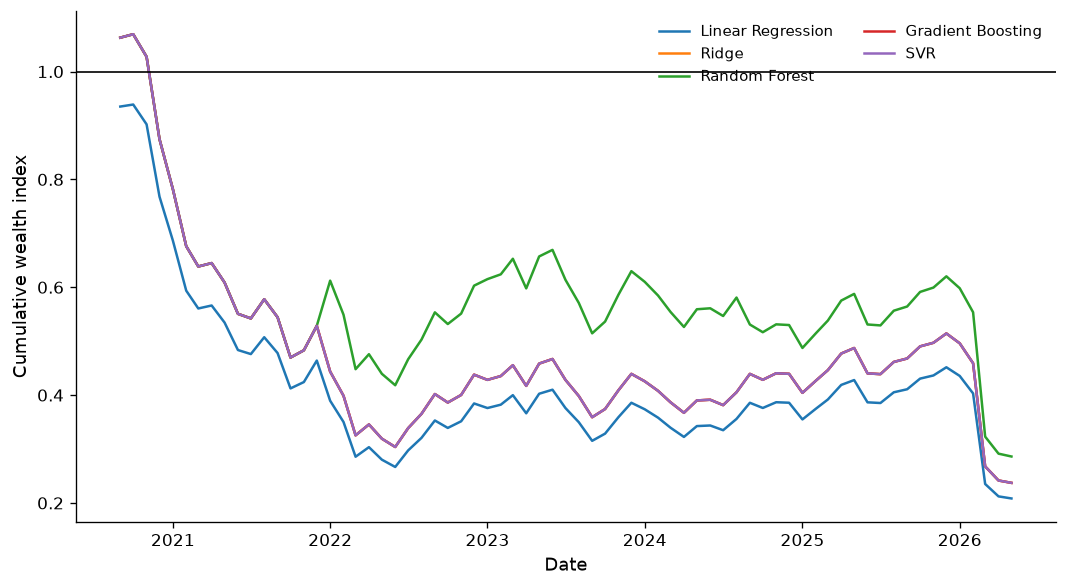

,Model,N,Mean monthly net return (%),Annualized volatility (%),Annualized Sharpe-type ratio,Cumulative net return (%),Maximum drawdown (%),Directional hit rate (%),Average monthly turnover,Transaction cost (bps)
0,Persistence,69,0.0000,0.0000,NaN,0.0000,0.0000,NaN,0.0000,10.0
1,Linear Regression,69,-1.8211,30.1415,-0.7250,-79.1671,-77.8107,46.3768,0.0435,10.0
2,Ridge,69,-1.6330,30.2656,-0.6475,-76.2735,-77.8107,47.8261,0.0145,10.0
3,Random Forest,69,-1.3649,30.4288,-0.5383,-71.3872,-73.2410,49.2754,0.1884,10.0
4,Gradient Boosting,69,-1.6330,30.2656,-0.6475,-76.2735,-77.8107,47.8261,0.0145,10.0
5,SVR,69,-1.6330,30.2656,-0.6475,-76.2735,-77.8107,47.8261,0.0145,10.0


In [134]:
# Monthly WTI economic-value diagnostic
WTI_TRANSACTION_COST_BPS=10.0
cost=WTI_TRANSACTION_COST_BPS/10000
wti=monthly_ledger[(monthly_ledger.target=="WTI Price")&(monthly_ledger.horizon_months==1)].copy()
cur=wti.Persistence.to_numpy(); fut=wti.actual.to_numpy(); rr=fut/cur-1
econ=[]; paths={}
for model in models:
    forecast=wti[model].to_numpy()
    pos=np.zeros(len(wti)) if model=="Persistence" else np.sign(forecast-cur)
    turnover=np.abs(np.diff(np.r_[0,pos]))
    net=pos*rr-cost*turnover
    wealth=np.cumprod(1+net); peak=np.maximum.accumulate(wealth); dd=wealth/peak-1
    vol=np.std(net,ddof=1)
    econ.append([model,len(net),100*np.mean(net),100*np.sqrt(12)*vol,
                 np.nan if vol<=EPS else np.sqrt(12)*np.mean(net)/vol,
                 100*(wealth[-1]-1),100*np.min(dd),
                 np.nan if model=="Persistence" else da(fut,forecast,cur),
                 np.mean(turnover),WTI_TRANSACTION_COST_BPS])
    paths[model]=wealth
economic_value_df=pd.DataFrame(econ,columns=[
    "Model","N","Mean monthly net return (%)","Annualized volatility (%)",
    "Annualized Sharpe-type ratio","Cumulative net return (%)","Maximum drawdown (%)",
    "Directional hit rate (%)","Average monthly turnover","Transaction cost (bps)"])
economic_value_df.to_csv(REV_TABLE_DIR/"table_wti_economic_value.csv",index=False)
fig,ax=plt.subplots(figsize=(9,5))
for model,wealth in paths.items():
    if model!="Persistence": ax.plot(wti.target_date,wealth,label=model)
ax.axhline(1,color="black",lw=1); ax.set_xlabel("Date"); ax.set_ylabel("Cumulative wealth index")
ax.legend(frameon=False,ncol=2); fig.tight_layout()
fig.savefig(REV_FIGURE_DIR/"fig_wti_economic_value.pdf",bbox_inches="tight")
fig.savefig(REV_FIGURE_DIR/"fig_wti_economic_value.png",bbox_inches="tight")
plt.show(); display(economic_value_df.round(4))

# Daily WTI frequency-robustness experiment

This module tests whether the monthly persistence result is frequency-dependent. It evaluates WTI at 1-, 5-, 10-, and 20-trading-day horizons. The cell first uses a cached `daily_wti.csv`; if absent, it attempts to retrieve the public FRED `DCOILWTICO` WTI Cushing spot-price series using `pandas_datareader` and caches it locally.

This daily experiment is separate from the monthly demand–supply–WTI framework.

In [137]:
# Daily WTI data loader
DAILY_WTI_CACHE=REV_DATA_DIR/"daily_wti.csv"
def load_daily_wti():
    if DAILY_WTI_CACHE.exists():
        z=pd.read_csv(DAILY_WTI_CACHE,parse_dates=["date"])
        return z.sort_values("date").dropna().reset_index(drop=True)
    try:
        from pandas_datareader import data as pdr
    except ImportError as e:
        raise ImportError("Install pandas_datareader or place daily_wti.csv with columns date,price in "
                          "outputs/reviewer_revision/data/") from e
    z=pdr.DataReader("DCOILWTICO","fred","1986-01-01").rename(columns={"DCOILWTICO":"price"}).reset_index()
    z.columns=["date","price"]; z["price"]=pd.to_numeric(z.price,errors="coerce")
    z=z.dropna().sort_values("date").reset_index(drop=True)
    z.to_csv(DAILY_WTI_CACHE,index=False)
    return z
daily_wti=load_daily_wti()
print(daily_wti.shape,daily_wti.date.min(),daily_wti.date.max())
display(daily_wti.head())

(9537, 2) 1986-01-02 00:00:00 2026-11-03 00:00:00


,date,price
0,1986-01-02,25.56
1,1986-01-03,26.00
2,1986-01-06,26.53
3,1986-01-07,25.85
4,1986-01-08,25.87


In [138]:
# pip install pandas_datareader

In [139]:
# Daily WTI features and forecasts
daily=daily_wti.copy(); daily["log_price"]=np.log(daily.price); daily["log_return"]=daily.log_price.diff()
DLAGS=[1,2,3,5,10,20,40,60]; DROLL=[5,10,20,60]
for lag in DLAGS:
    daily[f"price_lag{lag}"]=daily.price.shift(lag)
    daily[f"return_lag{lag}"]=daily.log_return.shift(lag)
for w in DROLL:
    daily[f"price_mean{w}"]=daily.price.shift(1).rolling(w).mean()
    daily[f"price_std{w}"]=daily.price.shift(1).rolling(w).std()
    daily[f"return_mean{w}"]=daily.log_return.shift(1).rolling(w).mean()
    daily[f"return_std{w}"]=daily.log_return.shift(1).rolling(w).std()
daily["dow_sin"]=np.sin(2*np.pi*daily.date.dt.dayofweek/5); daily["dow_cos"]=np.cos(2*np.pi*daily.date.dt.dayofweek/5)
daily["month_sin"]=np.sin(2*np.pi*daily.date.dt.month/12); daily["month_cos"]=np.cos(2*np.pi*daily.date.dt.month/12)
dfeatures=["dow_sin","dow_cos","month_sin","month_cos"]+[f"price_lag{x}" for x in DLAGS]+[f"return_lag{x}" for x in DLAGS]
dfeatures += [f"{v}_{s}{w}" for w in DROLL for v in ["price","return"] for s in ["mean","std"]]
DH=[1,5,10,20]
dmodels={
 "Linear Regression":("scaled",LinearRegression()),
 "Ridge":("scaled",Ridge(alpha=10)),
 "Random Forest":("raw",RandomForestRegressor(n_estimators=400,max_depth=12,min_samples_leaf=3,max_features=.7,random_state=SEED,n_jobs=-1)),
 "Gradient Boosting":("raw",GradientBoostingRegressor(n_estimators=300,learning_rate=.03,max_depth=3,min_samples_leaf=5,random_state=SEED)),
 "SVR":("scaled",SVR(C=100,epsilon=.05,gamma="scale"))
}
parts=[]
for h in DH:
    z=daily.copy(); z["target"]=z.price.shift(-h); z["target_date"]=z.date.shift(-h)
    z=z[["date","target_date","price"]+dfeatures+["target"]].dropna()
    n=len(z); a=int(.70*n); b=int(.85*n); tr,te=z.iloc[:a],z.iloc[b:]
    Xtr,Xte=tr[dfeatures],te[dfeatures]; ytr=tr.target
    sc=StandardScaler().fit(Xtr); Xtrs,Xtes=sc.transform(Xtr),sc.transform(Xte)
    part=pd.DataFrame({"forecast_origin":te.date,"target_date":te.target_date,
                       "horizon_trading_days":h,"actual":te.target,"Persistence":te.price})
    for name,(mode,est0) in dmodels.items():
        est=clone(est0)
        if mode=="scaled": est.fit(Xtrs,ytr); part[name]=est.predict(Xtes)
        else: est.fit(Xtr,ytr); part[name]=est.predict(Xte)
    parts.append(part)
daily_ledger=pd.concat(parts,ignore_index=True)
daily_ledger.to_csv(REV_DATA_DIR/"daily_wti_prediction_ledger.csv",index=False)
display(daily_ledger.head())

,forecast_origin,target_date,horizon_trading_days,actual,Persistence,Linear Regression,Ridge,Random Forest,Gradient Boosting,SVR
0,2021-03-10,2021-03-11,1,66.02,64.45,64.036666,64.278511,65.531614,64.373632,60.534515
1,2021-03-11,2021-03-12,1,65.59,66.02,64.163660,64.415661,65.290290,64.289558,63.733594
2,2021-03-12,2021-03-15,1,65.36,65.59,65.628203,65.385179,66.440130,66.066364,64.374679
3,2021-03-15,2021-03-16,1,64.82,65.36,65.419446,65.266967,66.185414,65.995204,61.926369
4,2021-03-16,2021-03-17,1,64.55,64.82,65.300415,65.229895,65.679099,65.278284,62.260894


In [140]:
# Daily WTI metrics, DM and encompassing tests
def dm_sq(y,f1,f2):
    e1=np.asarray(y)-np.asarray(f1); e2=np.asarray(y)-np.asarray(f2); d=e1**2-e2**2; n=len(d)
    if n<3 or np.var(d,ddof=1)<=EPS:return np.nan,np.nan
    st=np.mean(d)/np.sqrt(np.var(d,ddof=1)/n); return st,2*stats.norm.sf(abs(st))
drows=[]; tests=[]
for h,g in daily_ledger.groupby("horizon_trading_days"):
    y=g.actual.to_numpy(); pers=g.Persistence.to_numpy(); scale=np.mean(np.abs(y-pers))
    rms={}
    for model in models:
        p=g[model].to_numpy(); rms[model]=np.sqrt(mean_squared_error(y,p))
        drows.append([h,model,len(g),mean_absolute_error(y,p),median_absolute_error(y,p),rms[model],
                      mape_safe(y,p),smape(y,p),mase(y,p,scale),rmsle_pos(y,p),oos_r2(y,p,pers),
                      np.nan if model=="Persistence" else da(y,p,pers)])
    pref=min(rms,key=rms.get)
    for comp in models:
        if comp==pref:continue
        ds,dp=dm_sq(y,g[pref],g[comp]); hs,hp=hln_encompassing(y,g[pref],g[comp])
        tests.append([h,pref,comp,ds,dp,hs,hp])
daily_metrics=pd.DataFrame(drows,columns=["Horizon (trading days)","Model","N","MAE","Median AE","RMSE",
    "MAPE (%)","sMAPE (%)","MASE","RMSLE","OOS R2 vs Persistence","Directional Accuracy (%)"])
daily_tests=pd.DataFrame(tests,columns=["Horizon (trading days)","Preferred forecast","Competitor",
    "DM statistic","DM p-value","HLN statistic","HLN p-value"])
daily_metrics.to_csv(REV_TABLE_DIR/"table_daily_wti_metrics.csv",index=False)
daily_tests.to_csv(REV_TABLE_DIR/"table_daily_wti_dm_hln_tests.csv",index=False)
display(daily_metrics.round(4)); display(daily_tests.round(4))

,Horizon (trading days),Model,N,MAE,Median AE,RMSE,MAPE (%),sMAPE (%),MASE,RMSLE,OOS R2 vs Persistence,Directional Accuracy (%)
0,1,Persistence,1413,1.5464,1.0900,2.2765,1.8981,1.8943,1.0000,0.0259,0.0000,NaN
1,1,Linear Regression,1413,2.2398,1.5989,3.2019,2.7447,2.7405,1.4484,0.0367,-0.9782,50.1062
2,1,Ridge,1413,2.3032,1.6655,3.2628,2.8194,2.8181,1.4895,0.0375,-1.0542,50.8846
3,1,Random Forest,1413,2.3058,1.6709,3.2499,2.8317,2.8277,1.4911,0.0376,-1.0380,49.9646
4,1,Gradient Boosting,1413,2.2779,1.6369,3.2276,2.7858,2.7863,1.4731,0.0371,-1.0101,49.9646
5,1,SVR,1413,4.8770,2.0855,10.0017,5.4900,6.0361,3.1538,0.1241,-18.3015,49.6815
6,5,Persistence,1412,3.4018,2.3800,4.8064,4.1806,4.1783,1.0000,0.0555,0.0000,NaN
7,5,Linear Regression,1412,3.7052,2.7292,5.2853,4.5468,4.5531,1.0892,0.0612,-0.2092,51.0623
8,5,Ridge,1412,3.6851,2.7220,5.2333,4.5232,4.5351,1.0833,0.0609,-0.1855,52.3371
9,5,Random Forest,1412,3.8566,2.9367,5.3598,4.8163,4.8129,1.1337,0.0639,-0.2435,54.5326


,Horizon (trading days),Preferred forecast,Competitor,DM statistic,DM p-value,HLN statistic,HLN p-value
0,1,Persistence,Linear Regression,-8.7824,0.0000,0.6609,0.5088
1,1,Persistence,Ridge,-9.1872,0.0000,1.0906,0.2756
2,1,Persistence,Random Forest,-9.3649,0.0000,0.9186,0.3585
3,1,Persistence,Gradient Boosting,-8.8986,0.0000,1.0239,0.3061
4,1,Persistence,SVR,-9.6450,0.0000,0.5977,0.5501
5,5,Persistence,Linear Regression,-4.5237,0.0000,1.0685,0.2855
6,5,Persistence,Ridge,-3.9548,0.0001,2.2021,0.0278
7,5,Persistence,Random Forest,-4.3949,0.0000,3.6856,0.0002
8,5,Persistence,Gradient Boosting,-5.0216,0.0000,1.5092,0.1315
9,5,Persistence,SVR,-9.8829,0.0000,1.2751,0.2025


In [141]:
# Daily WTI validation-based combinations
def daily_predict(train,ev):
    Xtr,Xev=train[dfeatures],ev[dfeatures]; ytr=train.target
    sc=StandardScaler().fit(Xtr); Xtrs,Xevs=sc.transform(Xtr),sc.transform(Xev); ans={}
    for name,(mode,e0) in dmodels.items():
        e=clone(e0)
        if mode=="scaled": e.fit(Xtrs,ytr); ans[name]=e.predict(Xevs)
        else: e.fit(Xtr,ytr); ans[name]=e.predict(Xev)
    return ans
dc=[]
for h in DH:
    z=daily.copy(); z["target"]=z.price.shift(-h); z["target_date"]=z.date.shift(-h)
    z=z[["date","target_date","price"]+dfeatures+["target"]].dropna()
    n=len(z); a=int(.70*n); b=int(.85*n); tr,val,trval,te=z.iloc[:a],z.iloc[a:b],z.iloc[:b],z.iloc[b:]
    vp=daily_predict(tr,val); tp=daily_predict(trval,te); yv=val.target.to_numpy(); pv=val.price.to_numpy()
    yt=te.target.to_numpy(); pt=te.price.to_numpy()
    best=min(vp,key=lambda m:np.sqrt(mean_squared_error(yv,vp[m]))); w=convex_weight(yv,pv,vp[best])
    eq=.5*pt+.5*tp[best]; opt=w*pt+(1-w)*tp[best]
    for label,p in [("Persistence",pt),(best,tp[best]),("Equal-weight combination",eq),("Validation-weighted combination",opt)]:
        dc.append([h,label,best,w if "Validation" in label else np.nan,mean_absolute_error(yt,p),
                   np.sqrt(mean_squared_error(yt,p)),oos_r2(yt,p,pt)])
daily_combinations=pd.DataFrame(dc,columns=["Horizon (trading days)","Forecast","Selected ML model",
    "Validation weight on persistence","MAE","RMSE","OOS R2 vs Persistence"])
daily_combinations.to_csv(REV_TABLE_DIR/"table_daily_wti_combinations.csv",index=False)
display(daily_combinations.round(4))

,Horizon (trading days),Forecast,Selected ML model,Validation weight on persistence,MAE,RMSE,OOS R2 vs Persistence
0,1,Persistence,Ridge,NaN,1.5464,2.2765,0.0000
1,1,Ridge,Ridge,NaN,2.3051,3.2642,-1.0558
2,1,Equal-weight combination,Ridge,NaN,1.7774,2.5366,-0.2415
3,1,Validation-weighted combination,Ridge,0.5162,1.7636,2.5193,-0.2247
4,5,Persistence,Linear Regression,NaN,3.4018,4.8064,0.0000
5,5,Linear Regression,Linear Regression,NaN,3.7373,5.3090,-0.2201
6,5,Equal-weight combination,Linear Regression,NaN,3.4820,4.9139,-0.0452
7,5,Validation-weighted combination,Linear Regression,0.4677,3.4940,4.9312,-0.0526
8,10,Persistence,Linear Regression,NaN,4.4906,6.2687,0.0000
9,10,Linear Regression,Linear Regression,NaN,4.6977,6.5125,-0.0793


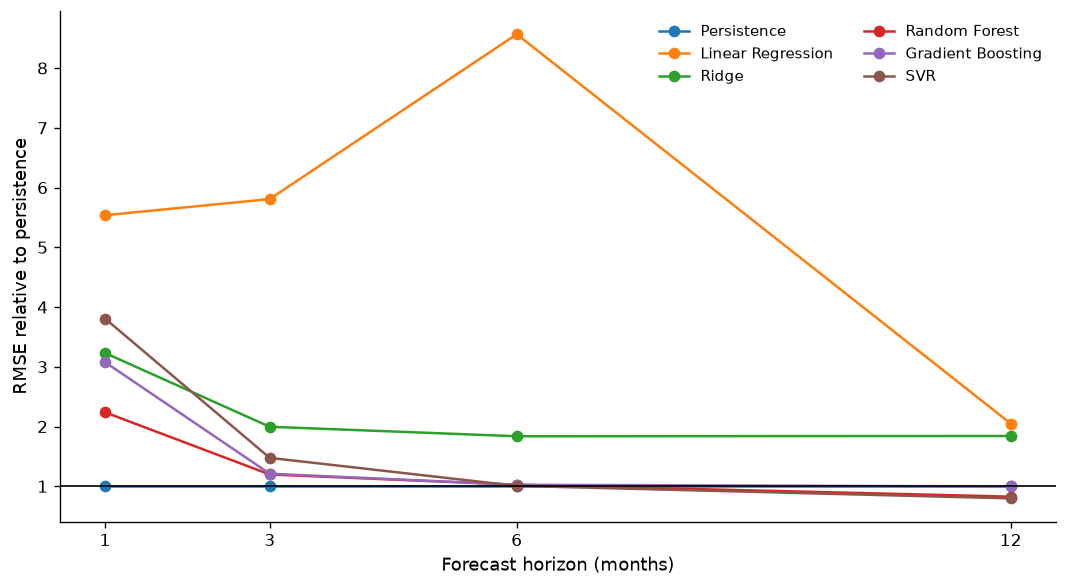

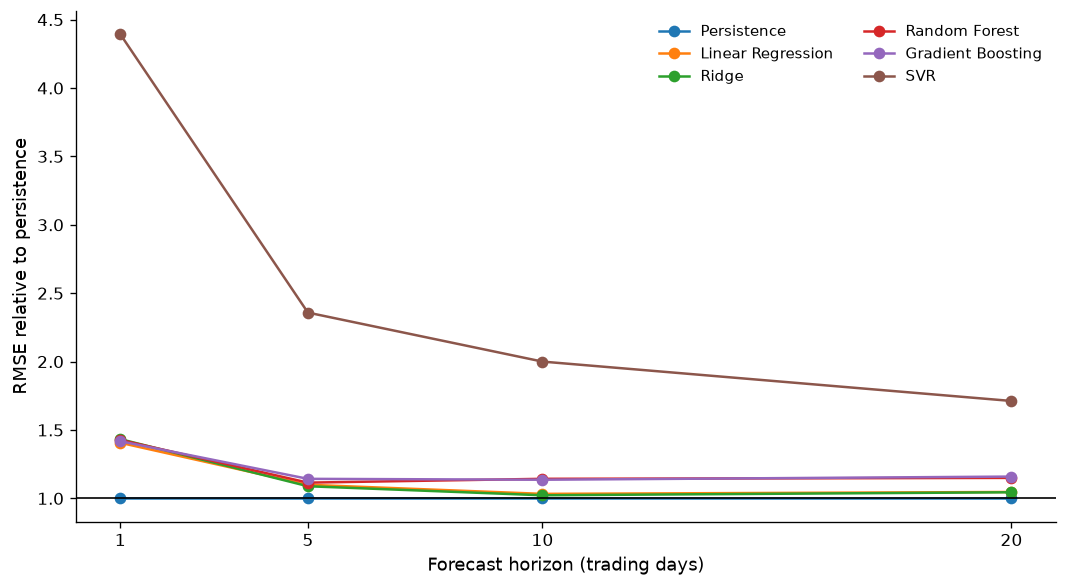

In [142]:
# Reviewer-revision comparison figures
q=verified_metrics[verified_metrics.Target=="WTI Price"].copy()
base=q[q.Model=="Persistence"].set_index("Horizon (months)").RMSE
q["Relative RMSE"]=q.apply(lambda r:r.RMSE/base.loc[r["Horizon (months)"]],axis=1)
fig,ax=plt.subplots(figsize=(9,5))
for model in q.Model.unique():
    z=q[q.Model==model]; ax.plot(z["Horizon (months)"],z["Relative RMSE"],marker="o",label=model)
ax.axhline(1,color="black",lw=1); ax.set_xlabel("Forecast horizon (months)"); ax.set_ylabel("RMSE relative to persistence")
ax.set_xticks(MONTHLY_HORIZONS); ax.legend(frameon=False,ncol=2); fig.tight_layout()
fig.savefig(REV_FIGURE_DIR/"fig_monthly_wti_relative_rmse.pdf",bbox_inches="tight")
fig.savefig(REV_FIGURE_DIR/"fig_monthly_wti_relative_rmse.png",bbox_inches="tight"); plt.show()

q=daily_metrics.copy(); base=q[q.Model=="Persistence"].set_index("Horizon (trading days)").RMSE
q["Relative RMSE"]=q.apply(lambda r:r.RMSE/base.loc[r["Horizon (trading days)"]],axis=1)
fig,ax=plt.subplots(figsize=(9,5))
for model in q.Model.unique():
    z=q[q.Model==model]; ax.plot(z["Horizon (trading days)"],z["Relative RMSE"],marker="o",label=model)
ax.axhline(1,color="black",lw=1); ax.set_xlabel("Forecast horizon (trading days)"); ax.set_ylabel("RMSE relative to persistence")
ax.set_xticks(DH); ax.legend(frameon=False,ncol=2); fig.tight_layout()
fig.savefig(REV_FIGURE_DIR/"fig_daily_wti_relative_rmse.pdf",bbox_inches="tight")
fig.savefig(REV_FIGURE_DIR/"fig_daily_wti_relative_rmse.png",bbox_inches="tight"); plt.show()

## Interpretation safeguards

Report only values produced after executing the revised notebook. Negative \(R^2_{\mathrm{OOS}}\) denotes underperformance relative to persistence. Persistence directional accuracy is left undefined because it predicts no change. Combination weights are learned only from validation observations. Split changes alter both sample size and calendar composition. The daily WTI experiment is a frequency robustness test, and the economic-value exercise is an illustrative application rather than a deployable trading strategy.

In [143]:
# Revision output inventory
for title,folder in [("TABLES",REV_TABLE_DIR),("FIGURES",REV_FIGURE_DIR),("DATA",REV_DATA_DIR)]:
    print("\n"+title)
    for p in sorted(folder.glob("*")):
        if p.is_file(): print(" ",p)


TABLES
  preprocessing_outputs\reviewer_revision\tables\table_daily_wti_combinations.csv
  preprocessing_outputs\reviewer_revision\tables\table_daily_wti_dm_hln_tests.csv
  preprocessing_outputs\reviewer_revision\tables\table_daily_wti_metrics.csv
  preprocessing_outputs\reviewer_revision\tables\table_forecast_combinations.csv
  preprocessing_outputs\reviewer_revision\tables\table_forecast_origin_audit.csv
  preprocessing_outputs\reviewer_revision\tables\table_hln_forecast_encompassing.csv
  preprocessing_outputs\reviewer_revision\tables\table_verified_monthly_metrics_and_losses.csv
  preprocessing_outputs\reviewer_revision\tables\table_wti_economic_value.csv

FIGURES
  preprocessing_outputs\reviewer_revision\figures\fig_daily_wti_relative_rmse.pdf
  preprocessing_outputs\reviewer_revision\figures\fig_daily_wti_relative_rmse.png
  preprocessing_outputs\reviewer_revision\figures\fig_monthly_wti_relative_rmse.pdf
  preprocessing_outputs\reviewer_revision\figures\fig_monthly_wti_relative